# Functional Knowledge Integration Pipeline (FKIP) v8.2

**Project:** gut microbiome and keratoconus  
**Environment:** Google Colab  
**Objective:** publication-oriented, deterministic and fully traceable harmonization of functional metagenomic results from COG, KEGG and FOAM.

## Architecture

### Stage 1 — Statistical and hierarchical deconvolution

- Uses canonical terminal statistical units.
- Uses **Level-ID** as the preferred terminal abundance representation for COG and KEGG.
- Uses **FOAM Level-4** as the tested terminal module/system representation.
- Uses rollups as sources of native `Function`, EC, gene aliases and complete hierarchy paths.
- Detects repeated paths, repeated identifiers, conflicting vectors and annotation-identity overlap.
- Does not require a fixed absolute-estimate threshold.

### Stage 2 — Deterministic knowledge integration

- Integrates native `Function`, hierarchy, COG2024, GO Biological Process, EC-to-GO, KEGG-reaction-to-GO, MetaCyc-to-GO, GMM and MiMeDB.
- Applies specificity-first process assignment.
- Separates canonical function, primary process, functional context and broad biological theme.
- Retains ambiguous, host/eukaryotic and unresolved evidence without promoting it into the primary summary.

## Main publication outputs

- Terminal-feature volcano plots for COG, KEGG and FOAM.
- Study-priority harmonized processes ranked by specificity, statistical signal, direction, independent support and confidence.
- Evidence matrix distinguishing official, native, contextual, conflicting and absent support.
- Complete traceability tables and automatic upload to `FKIP/results/FKIP_v8_2` in Google Drive.


### Two-pass curation workflow
- **FIRST_PASS**: produces automatic harmonization tables, the manual review template and the draft figure.
- **CURATED_RERUN**: if a manual override file is present, the curated assignments are merged deterministically and propagated into summary tables and the final figure.

### GO propagation safeguard
GO evidence is linked by `feature_key`/canonical feature provenance through EC, KEGG-reaction or MetaCyc identifiers. GO Molecular Function and GO Biological Process are retained as separate aspects: EC and KEGG-reaction mappings primarily support Molecular Function, whereas only exact Biological Process mappings may directly support a harmonized process. Molecular Function evidence is contextual and never promoted automatically into Biological Process evidence.

### Consolidation safeguard introduced in v8.2
Manual curation is merged without erasing valid automatic assignments. Blank spreadsheet cells are treated as missing values, never as replacement text. Automatic assignments remain the default and are replaced only by an explicit, non-empty manual assignment.


In [1]:
# ============================================================
# 0. Install and import packages
# ============================================================
get_ipython().system('pip -q install pandas numpy openpyxl requests tqdm google-api-python-client google-auth-httplib2 google-auth-oauthlib')

import os
import re
import io
import csv
import json
import math
import time
import zipfile
import hashlib
import warnings
import unicodedata
from pathlib import Path
from datetime import datetime, timezone
from typing import Dict, List, Optional, Tuple, Iterable
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

from google.colab import auth
import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload, MediaFileUpload

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_colwidth", 180)


In [2]:
# ============================================================
# 1. Configuration — FKIP v8.2
# ============================================================
FKIP_FOLDER_ID = "1b4Fo5XZZjMUjjGzIo8q9dMn8N9KzYlTi"

# Optional read-only fallback containing the original BugBuster outputs.
# It is searched only when terminal matrices are not found in the FKIP folder.
BUGBUSTER_OUTPUT_FOLDER_ID = "1ol1VpX3ViritXnKlLaBXu1Ttm1vF3YQ3"
SEARCH_BUGBUSTER_ARCHIVE_IF_NEEDED = True

P_VALUE_THRESHOLD = 0.05
ABS_ESTIMATE_THRESHOLD = None

TERMINAL_LEVELS = {
    "COG": {"Level-ID"},
    "KEGG": {"Level-ID"},
    "FOAM": {"Level-4"},
}

POSITIVE_GROUP = "Keratoconus"
NEGATIVE_GROUP = "Healthy siblings"

PROJECT_ROOT = Path("/content/FKIP_v8_2")
CACHE_DIR = PROJECT_ROOT / "cache"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
for directory in (CACHE_DIR, OUTPUT_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DRIVE_RESULTS_PARENT = "results"
DRIVE_RESULTS_FOLDER = "FKIP_v8_2"


MANUAL_CURATION_FOLDER = "inputs/manual_curation"
MANUAL_OVERRIDE_FILENAME = "FKIP8_1_1_Manual_Overrides.xlsx"
MANUAL_TEMPLATE_FILENAME = "FKIP8_1_1_Manual_Review_Template.xlsx"
FIGURE_STYLE_REFERENCE = "taxonomic_multipanel_style"
FIGURE_WIDTH = 24
FIGURE_HEIGHT = 18
PANEL_A_LABELS_PER_DATABASE = 6
PANEL_B_SPECIFIC_PROCESSES = 10
PANEL_B_CORE_PROCESSES = 5
PANEL_B_WRAP_THEME = 32
PANEL_B_WRAP_FUNCTION = 46
PANEL_C_WRAP = 34
VOLCANO_EXCLUDE_GENERIC_LABELS = True
MIMEDB_CHUNK_SIZE = 50_000
MIMEDB_MAX_HITS = 100_000

# Candidate suffixes. The first exact match is preferred; filename fallback is allowed.
EXPECTED_CANDIDATES = {
    "master_stats": [
        "inputs/LM_Functional_Master_Stats.csv",
        "LM_Functional_Master_Stats.csv",
    ],
    "nominal": [
        "inputs/LM_Functional_Nominal_Significant.csv",
        "LM_Functional_Nominal_Significant.csv",
    ],
    "cog_rollup": [
        "native_rollups/combined_wide_COG_rollup.tsv",
        "combined_wide_COG_rollup.tsv",
    ],
    "kegg_rollup": [
        "native_rollups/combined_wide_KEGG_rollup.tsv",
        "combined_wide_KEGG_rollup.tsv",
    ],
    "foam_rollup": [
        "native_rollups/combined_wide_FOAM_rollup.tsv",
        "combined_wide_FOAM_rollup.tsv",
    ],
    "cog_level_id": [
        "native_rollups/combined_wide_COG_level-id.tsv",
        "combined_wide_COG_level-id.tsv",
    ],
    "kegg_level_id": [
        "native_rollups/combined_wide_KEGG_level-id.tsv",
        "combined_wide_KEGG_level-id.tsv",
    ],
    "foam_level_4": [
        "native_rollups/combined_wide_FOAM_level-4.tsv",
        "combined_wide_FOAM_level-4.tsv",
    ],
    "cog_def": ["resources/cog/cog-24.def.tab", "cog-24.def.tab"],
    "cog_fun": ["resources/cog/cog-24.fun.tab", "cog-24.fun.tab"],
    "go_obo": ["resources/go/go-basic.obo", "go-basic.obo"],
    "ec2go": ["resources/go/ec2go.txt", "ec2go.txt"],
    "kegg_reaction2go": ["resources/go/kegg_reaction2go.txt", "kegg_reaction2go.txt"],
    "metacyc2go": ["resources/go/metacyc2go.txt", "metacyc2go.txt"],
    "gmm": [
        "resources/gmm/GMM_VieiraSilva_2016_Supplementary_Data_1.txt",
        "GMM_VieiraSilva_2016_Supplementary_Data_1.txt",
    ],
    "mimedb_genes": ["resources/mimedb/mimedb_genes_v1.csv", "mimedb_genes_v1.csv"],
    "mimedb_metabolites": ["resources/mimedb/mimedb_metabolites_v2.csv", "mimedb_metabolites_v2.csv"],
    "mimedb_microbes": ["resources/mimedb/mimedb_microbes_v2.csv", "mimedb_microbes_v2.csv"],
    "manual_overrides": [
        "inputs/manual_curation/FKIP8_1_1_Manual_Overrides.xlsx",
        "inputs/manual_curation/FKIP8_1_1_Manual_Overrides.csv",
        "FKIP8_1_1_Manual_Overrides.xlsx",
        "FKIP8_1_1_Manual_Overrides.csv",
    ],
}

RUN_TIMESTAMP = datetime.now(timezone.utc).isoformat()
print("FKIP v8.2 configured at", RUN_TIMESTAMP)


FKIP v8.2 configured at 2026-07-24T21:49:22.427003+00:00


In [3]:
# ============================================================
# 2. Google Drive discovery, read-only input cache and fallback
# ============================================================
auth.authenticate_user()
_credentials, _ = google.auth.default()
DRIVE = build("drive", "v3", credentials=_credentials, cache_discovery=False)

FOLDER_MIME = "application/vnd.google-apps.folder"
SHORTCUT_MIME = "application/vnd.google-apps.shortcut"


def get_metadata(file_id: str) -> dict:
    return DRIVE.files().get(
        fileId=file_id,
        supportsAllDrives=True,
        fields=(
            "id,name,mimeType,size,md5Checksum,modifiedTime,parents,driveId,"
            "webViewLink,shortcutDetails,capabilities(canDownload,canListChildren)"
        ),
    ).execute()


def list_children(folder_id: str, drive_id: Optional[str] = None) -> List[dict]:
    items, token = [], None
    while True:
        params = {
            "q": f"'{folder_id}' in parents and trashed=false",
            "spaces": "drive",
            "fields": (
                "nextPageToken,files(id,name,mimeType,size,md5Checksum,modifiedTime,"
                "parents,driveId,webViewLink,shortcutDetails,capabilities(canDownload,canListChildren))"
            ),
            "pageToken": token,
            "pageSize": 1000,
            "orderBy": "folder,name",
            "supportsAllDrives": True,
            "includeItemsFromAllDrives": True,
        }
        if drive_id:
            params["corpora"] = "drive"
            params["driveId"] = drive_id
        else:
            params["corpora"] = "user"
        response = DRIVE.files().list(**params).execute()
        items.extend(response.get("files", []))
        token = response.get("nextPageToken")
        if not token:
            return items


def resolve_shortcut(item: dict) -> dict:
    if item.get("mimeType") != SHORTCUT_MIME:
        return dict(item)
    target_id = item.get("shortcutDetails", {}).get("targetId")
    if not target_id:
        return dict(item)
    target = get_metadata(target_id)
    target["display_name"] = item.get("name", target.get("name", ""))
    target["shortcut_id"] = item.get("id", "")
    return target


def walk_drive(folder_id: str, base_path: str, drive_id: Optional[str] = None) -> List[dict]:
    output, visited = [], set()

    def _walk(current_id: str, current_path: str, current_drive_id: Optional[str]):
        if current_id in visited:
            return
        visited.add(current_id)
        for original in list_children(current_id, current_drive_id):
            item = resolve_shortcut(original)
            display_name = original.get("name", item.get("name", "unnamed"))
            path = f"{current_path}/{display_name}"
            row = dict(item)
            row["display_name"] = display_name
            row["path"] = path
            row["is_folder"] = item.get("mimeType") == FOLDER_MIME
            output.append(row)
            if row["is_folder"]:
                _walk(item["id"], path, item.get("driveId", current_drive_id))

    root = get_metadata(folder_id)
    if root.get("mimeType") == SHORTCUT_MIME:
        root = resolve_shortcut(root)
        folder_id = root["id"]
    _walk(folder_id, base_path, root.get("driveId", drive_id))
    return output


def normalize_drive_path(value: str) -> str:
    return str(value).replace("\\", "/").strip().lower()


def resolve_candidates(items: List[dict], candidates: Dict[str, List[str]]) -> Dict[str, Optional[dict]]:
    files = [x for x in items if not x.get("is_folder", False)]
    resolved = {}
    for key, suffixes in candidates.items():
        exact_hits = []
        for suffix in suffixes:
            suffix_norm = normalize_drive_path(suffix)
            exact_hits.extend(
                x for x in files if normalize_drive_path(x.get("path", "")).endswith(suffix_norm)
            )
        # Deduplicate hits by file ID.
        exact_hits = list({x["id"]: x for x in exact_hits}.values())
        if len(exact_hits) == 1:
            resolved[key] = exact_hits[0]
            continue
        if len(exact_hits) > 1:
            # Prefer the shortest path, then most recently modified.
            exact_hits.sort(key=lambda x: (len(x.get("path", "")), x.get("modifiedTime", "")), reverse=False)
            resolved[key] = exact_hits[0]
            print(f"WARNING: multiple candidates for {key}; selected {resolved[key]['path']}")
            continue
        # Filename-only fallback.
        names = {Path(s).name.lower() for s in suffixes}
        name_hits = [x for x in files if x.get("display_name", x.get("name", "")).lower() in names]
        if name_hits:
            name_hits.sort(key=lambda x: (len(x.get("path", "")), x.get("modifiedTime", "")))
            resolved[key] = name_hits[0]
        else:
            resolved[key] = None
    return resolved


def safe_filename(name: str) -> str:
    return re.sub(r"[^A-Za-z0-9._-]+", "_", name)


def download_file(info: Optional[dict], overwrite: bool = False) -> Optional[Path]:
    if info is None:
        return None
    local = CACHE_DIR / f"{info['id']}_{safe_filename(info.get('display_name', info.get('name', 'file')))}"
    expected_size = int(info.get("size", 0) or 0)
    if local.exists() and not overwrite and (expected_size == 0 or local.stat().st_size == expected_size):
        return local
    request = DRIVE.files().get_media(fileId=info["id"], supportsAllDrives=True)
    with open(local, "wb") as handle:
        downloader = MediaIoBaseDownload(handle, request, chunksize=20 * 1024 * 1024)
        done = False
        while not done:
            _, done = downloader.next_chunk()
    return local


print("Scanning FKIP folder in read-only mode...")
FKIP_ITEMS = walk_drive(FKIP_FOLDER_ID, "FKIP")
FILES = resolve_candidates(FKIP_ITEMS, EXPECTED_CANDIDATES)

# Optional fallback: recover Level-ID/Level-4 matrices from BugBuster Archive.zip.
terminal_keys = ["cog_level_id", "kegg_level_id", "foam_level_4"]
if SEARCH_BUGBUSTER_ARCHIVE_IF_NEEDED and any(FILES.get(k) is None for k in terminal_keys):
    print("Terminal matrix missing; searching BugBuster output for Archive.zip...")
    BUG_ITEMS = walk_drive(BUGBUSTER_OUTPUT_FOLDER_ID, "BugBuster_output")
    archives = [
        x for x in BUG_ITEMS
        if not x.get("is_folder", False)
        and x.get("display_name", x.get("name", "")).lower() == "archive.zip"
    ]
    if archives:
        archive_info = sorted(archives, key=lambda x: len(x.get("path", "")))[0]
        archive_path = download_file(archive_info)
        extract_dir = CACHE_DIR / "bugbuster_archive_terminal_matrices"
        extract_dir.mkdir(parents=True, exist_ok=True)
        wanted = {
            "cog_level_id": "combined_wide_COG_level-id.tsv",
            "kegg_level_id": "combined_wide_KEGG_level-id.tsv",
            "foam_level_4": "combined_wide_FOAM_level-4.tsv",
        }
        with zipfile.ZipFile(archive_path) as archive:
            members = {Path(x.filename).name: x for x in archive.infolist() if not x.is_dir()}
            for key, filename in wanted.items():
                if FILES.get(key) is not None or filename not in members:
                    continue
                destination = extract_dir / filename
                with archive.open(members[filename]) as source, open(destination, "wb") as target:
                    target.write(source.read())
                FILES[key] = {
                    "id": f"archive::{filename}",
                    "name": filename,
                    "display_name": filename,
                    "path": f"{archive_info['path']}::{filename}",
                    "size": destination.stat().st_size,
                    "modifiedTime": archive_info.get("modifiedTime"),
                    "md5Checksum": "",
                    "local_override": str(destination),
                }
                print("Recovered from Archive.zip:", filename)
    else:
        print("Archive.zip was not found; terminal-matrix audit will report NOT_AVAILABLE where appropriate.")

required = {
    "master_stats", "cog_rollup", "kegg_rollup", "foam_rollup",
    "cog_def", "cog_fun", "go_obo", "ec2go", "kegg_reaction2go", "metacyc2go",
}
missing_required = sorted(k for k in required if FILES.get(k) is None)
if missing_required:
    raise FileNotFoundError("Missing required FKIP resources: " + ", ".join(missing_required))

LOCAL = {}
for key, info in FILES.items():
    if info is None:
        LOCAL[key] = None
    elif info.get("local_override"):
        LOCAL[key] = Path(info["local_override"])
    else:
        LOCAL[key] = download_file(info)
    print(f"{key:22s}", "OK" if LOCAL[key] else "not available")


Scanning FKIP folder in read-only mode...
Terminal matrix missing; searching BugBuster output for Archive.zip...
Recovered from Archive.zip: combined_wide_COG_level-id.tsv
Recovered from Archive.zip: combined_wide_KEGG_level-id.tsv
Recovered from Archive.zip: combined_wide_FOAM_level-4.tsv
master_stats           OK
nominal                OK
cog_rollup             OK
kegg_rollup            OK
foam_rollup            OK
cog_level_id           OK
kegg_level_id          OK
foam_level_4           OK
cog_def                OK
cog_fun                OK
go_obo                 OK
ec2go                  OK
kegg_reaction2go       OK
metacyc2go             OK
gmm                    OK
mimedb_genes           OK
mimedb_metabolites     OK
mimedb_microbes        OK
manual_overrides       OK


In [4]:
# ============================================================
# 3. General parsers, normalization and semantic utilities
# ============================================================
def detect_encoding(path: Path) -> str:
    sample = Path(path).read_bytes()[:200_000]
    for enc in ("utf-8-sig", "utf-8", "latin-1", "cp1252"):
        try:
            sample.decode(enc)
            return enc
        except UnicodeDecodeError:
            pass
    return "utf-8"


def read_text(path: Optional[Path]) -> str:
    if path is None:
        return ""
    return Path(path).read_text(encoding=detect_encoding(path), errors="replace")


def read_table(path: Path, sep=",", required_columns=None, **kwargs) -> pd.DataFrame:
    params = dict(sep=sep, encoding=detect_encoding(path), low_memory=False)
    params.update(kwargs)
    try:
        df = pd.read_csv(path, engine="c", **params)
    except Exception:
        params.pop("low_memory", None)
        df = pd.read_csv(path, engine="python", on_bad_lines="warn", **params)
    df.columns = [str(c).strip() for c in df.columns]
    if required_columns:
        missing = set(required_columns).difference(df.columns)
        if missing:
            raise ValueError(f"{Path(path).name}: missing columns {sorted(missing)}")
    return df


def clean_text(value) -> str:
    return "" if pd.isna(value) else str(value).strip()


def canonical_text(value) -> str:
    text = unicodedata.normalize("NFKC", clean_text(value)).casefold()
    text = re.sub(r"\[(?:PATH|BR|MODULE|KO|RN|mD)\s*:[^\]]+\]", "", text, flags=re.I)
    text = re.sub(r"\([^)]*\b(?:PATH|BR|MODULE|KO|RN)\s*:[^)]*\)", "", text, flags=re.I)
    text = text.replace("_", " ")
    text = re.sub(r"[^a-z0-9+./'-]+", " ", text)
    return re.sub(r"\s+", " ", text).strip(" -:;,.")


def ordered_unique(values: Iterable) -> List[str]:
    seen, out = set(), []
    for value in values:
        value = clean_text(value)
        if value and value not in seen:
            seen.add(value)
            out.append(value)
    return out


def split_multi(value: str) -> List[str]:
    return ordered_unique(re.split(r"\s*\|\|\s*|\s*;\s*", clean_text(value)))


def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def normalize_database(value) -> str:
    text = clean_text(value).upper()
    if "COG" in text:
        return "COG"
    if "KEGG" in text or text == "KO":
        return "KEGG"
    if "FOAM" in text:
        return "FOAM"
    return text


def normalize_level(value) -> str:
    text = clean_text(value)
    m = re.search(r"level\s*[-_ ]?\s*(id|[1-4])", text, flags=re.I)
    return f"Level-{m.group(1).upper()}" if m else text


def extract_explicit_id(name: str, database: str) -> str:
    text = clean_text(name)
    patterns = {
        "COG": [r"\bCOG\d{4,5}\b"],
        "KEGG": [r"\bK\d{5}\b", r"\bR\d{5}\b", r"\bM\d{5}\b"],
        "FOAM": [r"\[\s*mD\s*:\s*([A-Za-z0-9_.-]+)\s*\]", r"\bK\d{5}\b", r"\bm\d{5}\b"],
    }
    for pattern in patterns.get(database, []):
        match = re.search(pattern, text, flags=re.I)
        if match:
            token = match.group(1) if match.lastindex else match.group(0)
            return token.upper()
    return ""


def extract_identifiers(text: str) -> Dict[str, List[str]]:
    value = clean_text(text)
    return {
        "COG": sorted(set(x.upper() for x in re.findall(r"\bCOG\d{4,5}\b", value, flags=re.I))),
        "KO": sorted(set(x.upper() for x in re.findall(r"\bK\d{5}\b", value, flags=re.I))),
        "REACTION": sorted(set(x.upper() for x in re.findall(r"\bR\d{5}\b", value, flags=re.I))),
        "GO": sorted(set(x.upper() for x in re.findall(r"\bGO:\d{7}\b", value, flags=re.I))),
        "MODULE": sorted(set(x.upper() for x in re.findall(r"\bmD\s*:\s*m?\d{5}\b|\bm\d{5}\b", value, flags=re.I))),
    }


def extract_ecs(value: str) -> List[str]:
    return sorted(set(re.findall(r"\b\d+\.(?:\d+|-|n)\.(?:\d+|-|n)\.(?:\d+|-|n)\b", clean_text(value))))


UNINFORMATIVE = {
    "", "function unknown", "general function prediction only", "poorly characterized",
    "not included in pathway or brite", "not included in regular maps", "unclassified",
    "unknown", "other", "hypothetical protein", "uncharacterized protein",
}

HOST_CONTEXT_PATTERNS = [
    r"human disease", r"cancer", r"neurodegenerative disease", r"cardiovascular disease",
    r"endocrine and metabolic disease", r"infectious disease", r"immune system",
    r"nervous system", r"circulatory system", r"endocrine system", r"digestive system",
    r"meiosis", r"apoptosis", r"ribosome biogenesis in eukaryotes",
    r"protein processing in endoplasmic reticulum", r"autophagy - animal", r"autophagy - yeast",
    r"alzheimer", r"amyotrophic lateral sclerosis", r"huntington", r"parkinson",
]

THEME_RULES = [
    (r"translation|ribosom|trna|aminoacyl", "Translation and ribosome biogenesis"),
    (r"replication|recombination|dna repair|mismatch repair|homologous recombination", "DNA replication and repair"),
    (r"transcription|rna polymerase|rna processing|rna degradation", "Transcription and RNA regulation"),
    (r"methan|oxidative phosphorylation|hydrogenase|energy production|respiration", "Energy metabolism"),
    (r"amino acid|lysine|cysteine|methionine|arginine|proline|glutamate|aspartate|peptide", "Amino acid metabolism"),
    (r"carbohydrate|glycolysis|starch|sugar|glycan|pentose|butanoate|propanoate|lactose", "Carbohydrate metabolism"),
    (r"lipid|fatty acid|ether lipid|isoprenoid", "Lipid metabolism"),
    (r"purine|pyrimidine|nucleotide", "Nucleotide metabolism"),
    (r"cofactor|vitamin|folate|thiamine|riboflavin|porphyrin", "Cofactor and vitamin metabolism"),
    (r"polyketide|secondary metabolite|nonribosomal peptide|surfactin", "Secondary metabolism"),
    (r"transport|transporter|permease|channel|efflux|phosphotransferase system", "Transport and nutrient acquisition"),
    (r"two-component|signal transduction|quorum sensing|chemotaxis|regulator", "Environmental sensing and signaling"),
    (r"flagell|motility|biofilm|cellular community", "Cell motility and community behavior"),
    (r"defense|antimicrobial|drug resistance|crispr|stress response|detoxification|mercur", "Stress response and antimicrobial defense"),
    (r"cell cycle|cell division|chromosome partition|z-ring|ftsz", "Cell division and cellular organization"),
    (r"cell wall|membrane/envelope biogenesis|peptidoglycan", "Cell envelope biogenesis and maintenance"),
    (r"protein turnover|chaperone|posttranslational|proteolysis|peptidase", "Protein turnover and quality control"),
    (r"secretion|extracellular structure|intracellular trafficking", "Secretion and extracellular interaction"),
]

CORE_HOUSEKEEPING_PATTERNS = [
    r"^translation", r"ribosome", r"aminoacyl-trna", r"dna replication",
    r"rna polymerase", r"central carbon", r"glycolysis", r"oxidative phosphorylation",
    r"protein turnover", r"chaperone", r"basic transcription",
]

BROAD_PROCESS_PATTERNS = [
    r"^energy metabolism$", r"^amino acid metabolism$", r"^carbohydrate metabolism$",
    r"^lipid metabolism$", r"^nucleotide metabolism$", r"^transport and nutrient acquisition$",
    r"^environmental sensing and signaling$", r"^secondary metabolism$",
]


def theme_from_text(text: str) -> str:
    for pattern, theme in THEME_RULES:
        if re.search(pattern, clean_text(text), flags=re.I):
            return theme
    return ""


def is_host_text(text: str) -> Tuple[bool, str]:
    for pattern in HOST_CONTEXT_PATTERNS:
        if re.search(pattern, clean_text(text), flags=re.I):
            return True, pattern
    return False, ""


def first_informative(*values) -> str:
    for value in values:
        value = clean_text(value)
        if value and canonical_text(value) not in UNINFORMATIVE:
            return value
    return ""


def parse_function_fields(function: str, database: str, ec_value: str = "", gene_value: str = "") -> dict:
    native = clean_text(function)
    canonical = native
    gene_aliases = split_multi(gene_value)
    enzyme_aliases = []

    # FOAM frequently encodes EC-like aliases and genes before a semicolon.
    if database == "FOAM" and ";" in native:
        prefix, tail = native.split(";", 1)
        canonical = clean_text(tail)
        for token in [x.strip() for x in prefix.split(",")]:
            if re.fullmatch(r"E?\d+\.\d+\.\d+\.\d+", token, flags=re.I):
                enzyme_aliases.append(token.lstrip("Ee"))
            elif token and not token.lower().startswith("ec"):
                gene_aliases.append(token)

    # Remove database identifier decorations without altering the preserved native text.
    canonical = re.sub(r"\[(?:mD|BR|PATH|MODULE|KO|RN)\s*:[^\]]+\]", "", canonical, flags=re.I)
    canonical = re.sub(r"^E\d+\.\d+\.\d+\.\d+\s*,?\s*", "", canonical, flags=re.I)
    canonical = re.sub(r"\s+", " ", canonical).strip(" ;,.-")
    normalized = canonical_text(canonical)

    low = normalized
    if not low or low in UNINFORMATIVE or re.search(r"uncharacterized|hypothetical|unknown function", low):
        semantic_class = "uncharacterized"
        informativeness = "uncharacterized"
    elif re.search(r"transport|transporter|permease|channel|efflux|importer|exporter", low):
        semantic_class = "specific_transporter"
        informativeness = "specific"
    elif re.search(r"regulator|transcription factor|response regulator|sensor kinase|quorum", low):
        semantic_class = "regulatory_protein"
        informativeness = "specific"
    elif re.search(r"cell division|z-ring|chromosome partition|ribosomal protein|chaperone", low):
        semantic_class = "cellular_system_protein"
        informativeness = "specific"
    elif extract_ecs(ec_value + " " + native) or re.search(r"ase\b|synthase|synthetase|dehydrogenase|kinase|hydrolase|reductase", low):
        semantic_class = "specific_enzyme"
        informativeness = "specific" if len(low.split()) >= 2 else "generic"
    elif low in {"atpase", "protein", "membrane protein", "enzyme"} or len(low.split()) <= 1:
        semantic_class = "generic_protein"
        informativeness = "generic"
    else:
        semantic_class = "described_protein"
        informativeness = "moderate"

    return {
        "native_function": native,
        "normalized_function": normalized,
        "canonical_function": canonical,
        "function_semantic_class": semantic_class,
        "function_informativeness": informativeness,
        "function_gene_aliases": " || ".join(ordered_unique(gene_aliases)),
        "function_enzyme_aliases": " || ".join(ordered_unique(enzyme_aliases + extract_ecs(ec_value))),
    }


def function_process_candidate(canonical_function: str, semantic_class: str) -> Tuple[str, str]:
    text = clean_text(canonical_function)
    low = canonical_text(text)
    if not low or semantic_class in {"uncharacterized", "generic_protein"}:
        return "", "FUNCTION_NOT_INFORMATIVE"

    if re.search(r"cell division protein zapb|interacts with ftsz|z-ring", low):
        return "Bacterial cell division and Z-ring organization", "FUNCTION_CELL_DIVISION_ZAPB"
    if re.search(r"mercuric reductase|mercury reductase|\bmera\b", low):
        return "Mercury detoxification", "FUNCTION_MERCURY_DETOXIFICATION"
    if "formaldehyde" in low:
        return "Formaldehyde detoxification and aldehyde oxidation", "FUNCTION_FORMALDEHYDE"
    if "quorum" in low or re.search(r"luxr|sdia", low):
        return "Quorum-sensing regulation", "FUNCTION_QUORUM_REGULATION"
    if re.search(r"crispr|cas protein", low):
        return "CRISPR-Cas adaptive defense", "FUNCTION_CRISPR"
    if re.search(r"trna.*modif|trna.*methyl|trm\w*", low):
        return "tRNA modification", "FUNCTION_TRNA_MODIFICATION"
    if re.search(r"dna repair|dna ligase|ribonuclease hi|dna polymerase", low):
        return "DNA replication and repair", "FUNCTION_DNA_REPAIR"
    if re.search(r"ribosomal protein|translation factor|initiation factor|elongation factor", low):
        return "Translation and ribosome biogenesis", "FUNCTION_TRANSLATION"
    if re.search(r"\bpts system\b|phosphotransferase system", low):
        substrate = re.sub(r"\b(?:pts|phosphotransferase) system.*$", "", low).strip(" ,;/-")
        if substrate:
            return substrate[:1].upper() + substrate[1:] + " phosphotransferase-system transport", "FUNCTION_PTS_TRANSPORT"
        return "Phosphotransferase-system transport", "FUNCTION_PTS_TRANSPORT"

    if semantic_class == "specific_transporter":
        cleaned = re.sub(r"\b(?:abc-type|abc type|pts|phosphotransferase system)\b", "", low)
        cleaned = re.sub(r"\b(?:transport system|transporter|transport|permease|channel|efflux pump|importer|exporter)\b.*$", "", cleaned)
        cleaned = re.sub(r"\b(?:atp-binding|atpase|substrate-binding|permease) component\b", "", cleaned)
        cleaned = cleaned.replace("-specific", "")
        substrate = re.sub(r"\s+", " ", cleaned).strip(" ,;/-")
        if substrate and 1 <= len(substrate.split()) <= 8:
            parts = [part.strip() for part in substrate.split("/") if part.strip()]
            if len(parts) > 1:
                substrate = ", ".join(parts[:-1]) + " and " + parts[-1]
            elif parts:
                substrate = parts[0]
            return substrate[:1].upper() + substrate[1:] + " transport", "FUNCTION_SPECIFIC_TRANSPORT"
        return "Specific membrane transport", "FUNCTION_GENERIC_TRANSPORT"

    if re.search(r"alcohol.*dehydrogenase|aldehyde.*dehydrogenase", low):
        return "Alcohol and aldehyde oxidation", "FUNCTION_ALCOHOL_ALDEHYDE"
    if re.search(r"surfactin synthetase|nonribosomal peptide", low):
        return "Nonribosomal peptide biosynthesis", "FUNCTION_NRP_BIOSYNTHESIS"
    if re.search(r"cell wall|peptidoglycan", low):
        return "Cell-envelope biogenesis and maintenance", "FUNCTION_CELL_ENVELOPE"

    return "", "FUNCTION_NO_CONTROLLED_PROCESS"


def process_specificity(process: str) -> Tuple[str, int, bool, bool]:
    text = canonical_text(process)
    if not text:
        return "unresolved", 0, False, False
    core = any(re.search(p, text, flags=re.I) for p in CORE_HOUSEKEEPING_PATTERNS)
    broad = any(re.search(p, text, flags=re.I) for p in BROAD_PROCESS_PATTERNS)
    if core:
        return "core_housekeeping", 1, True, broad
    if broad:
        return "broad_context", 1, False, True
    if re.search(r"specific membrane transport|abc-type transport|signal transduction|biosynthesis|degradation", text):
        return "functional_system", 3, False, False
    if re.search(r"transport|detoxification|quorum|cell division|z-ring|crispr|formaldehyde|mercury|phosphonate|sulfate|lactose", text):
        return "specific_process", 4, False, False
    return "intermediate_process", 3, False, False


CONFIDENCE_SCORE = {"High": 3, "Moderate": 2, "Low": 1, "Not assigned": 0, "Excluded": 0}


In [5]:
# ============================================================
# 4. Statistical units and evidence strata
# ============================================================
STATS_COLUMNS = ["Name", "Estimate", "Std_Error", "t_value", "p_value", "Database", "Level", "p_adj"]

master = read_table(LOCAL["master_stats"], required_columns=STATS_COLUMNS)
nominal_file = read_table(LOCAL["nominal"], required_columns=STATS_COLUMNS) if LOCAL.get("nominal") else pd.DataFrame()

for df in (master, nominal_file):
    if df.empty:
        continue
    df["Database_norm"] = df["Database"].map(normalize_database)
    df["Level_norm"] = df["Level"].map(normalize_level)
    for column in ["Estimate", "Std_Error", "t_value", "p_value", "p_adj"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

master["nominal_significant"] = master["p_value"].lt(P_VALUE_THRESHOLD)
master["FDR_significant"] = master["p_adj"].lt(P_VALUE_THRESHOLD)
master["terminal_level"] = master.apply(
    lambda row: row["Level_norm"] in TERMINAL_LEVELS.get(row["Database_norm"], set()), axis=1
)
master["FKIP_selected"] = master["terminal_level"] & master["nominal_significant"]
master["enriched_group"] = np.select(
    [master["Estimate"].gt(0), master["Estimate"].lt(0)],
    [POSITIVE_GROUP, NEGATIVE_GROUP],
    default="No direction",
)
master["evidence_stratum"] = np.select(
    [
        master["terminal_level"] & master["FDR_significant"],
        master["terminal_level"] & master["nominal_significant"],
        ~master["terminal_level"] & master["nominal_significant"],
    ],
    ["FDR_terminal", "Nominal_terminal", "Nominal_nonterminal_context"],
    default="Contextual",
)

terminal_stats = master.loc[master["terminal_level"]].copy()
terminal_stats["feature_name_raw"] = terminal_stats["Name"].map(clean_text)
terminal_stats["feature_name_key"] = terminal_stats["Name"].map(canonical_text)
terminal_stats["official_id_input"] = terminal_stats.apply(
    lambda row: extract_explicit_id(row["Name"], row["Database_norm"]), axis=1
)
terminal_stats["feature_key"] = (
    terminal_stats["Database_norm"].astype(str)
    + "::" + terminal_stats["Level_norm"].astype(str)
    + "::" + terminal_stats["Name"].astype(str)
)
terminal_stats["abs_estimate"] = terminal_stats["Estimate"].abs()
terminal_stats["abs_estimate_percentile_within_database"] = terminal_stats.groupby("Database_norm")["abs_estimate"].rank(pct=True)

selected = terminal_stats.loc[terminal_stats["nominal_significant"]].copy()

print("Master rows:", len(master))
print("All terminal statistical rows:", len(terminal_stats))
print("Nominal terminal features selected:", len(selected))
print("FDR-significant terminal features:", int(selected["FDR_significant"].sum()))
display(selected.groupby(["Database_norm", "Level_norm"]).size().rename("n").reset_index())


Master rows: 21025
All terminal statistical rows: 9279
Nominal terminal features selected: 291
FDR-significant terminal features: 0


,Database_norm,Level_norm,n
0,COG,Level-ID,111
1,FOAM,Level-4,3
2,KEGG,Level-ID,177


In [6]:
# ============================================================
# 5. Native rollups, Function parsing and COG2024 resources
# ============================================================
ROLLUP_COLUMNS = {
    "COG": ["L1", "L2", "L3", "L4", "ID", "Function", "EC"],
    "KEGG": ["L1", "L2", "L3", "ID", "Function", "EC", "Gene"],
    "FOAM": ["L1", "L2", "L3", "L4", "ID", "Function", "EC"],
}

raw_rollups = {
    "COG": read_table(LOCAL["cog_rollup"], sep="\t", required_columns=ROLLUP_COLUMNS["COG"]),
    "KEGG": read_table(LOCAL["kegg_rollup"], sep="\t", required_columns=ROLLUP_COLUMNS["KEGG"]),
    "FOAM": read_table(LOCAL["foam_rollup"], sep="\t", required_columns=ROLLUP_COLUMNS["FOAM"]),
}


def vector_hash(values: Iterable) -> str:
    array = pd.to_numeric(pd.Series(list(values)), errors="coerce").fillna(0).to_numpy(dtype=np.float64)
    return hashlib.sha256(np.round(array, 12).tobytes()).hexdigest()


def prepare_rollup(df: pd.DataFrame, database: str) -> Tuple[pd.DataFrame, List[str]]:
    out = df.copy()
    metadata_cols = ROLLUP_COLUMNS[database]
    sample_cols = [column for column in out.columns if column not in metadata_cols]
    out = out[metadata_cols + sample_cols].copy()
    for column in metadata_cols:
        out[column] = out[column].map(clean_text)
    for column in sample_cols:
        out[column] = pd.to_numeric(out[column], errors="coerce")
    out["native_source_row"] = np.arange(1, len(out) + 1)
    out["ID_key"] = out["ID"].str.upper().str.strip()
    out["Function_key"] = out["Function"].map(canonical_text)
    for level in ("L1", "L2", "L3", "L4"):
        if level in out.columns:
            out[f"{level}_key"] = out[level].map(canonical_text)
    hierarchy = [column for column in ("L1", "L2", "L3", "L4") if column in out.columns]
    out["native_hierarchy_path"] = out[hierarchy + ["ID", "Function"]].apply(
        lambda row: " > ".join(ordered_unique(row.tolist())), axis=1
    )
    parsed = out.apply(
        lambda row: pd.Series(parse_function_fields(row["Function"], database, row.get("EC", ""), row.get("Gene", ""))),
        axis=1,
    )
    out = pd.concat([out.reset_index(drop=True), parsed.reset_index(drop=True)], axis=1)
    out["abundance_vector_hash"] = out[sample_cols].apply(lambda row: vector_hash(row.tolist()), axis=1)
    return out.drop_duplicates(), sample_cols


rollups, rollup_sample_columns = {}, {}
for database, dataframe in raw_rollups.items():
    rollups[database], rollup_sample_columns[database] = prepare_rollup(dataframe, database)

# ID-level rollup audit and canonical metadata dictionary.
rollup_id_rows, canonical_rollup_rows = [], []
for database, dataframe in rollups.items():
    for identifier, group in dataframe.groupby("ID_key", dropna=False, sort=False):
        functions = ordered_unique(group["native_function"])
        canonical_functions = ordered_unique(group["canonical_function"])
        ecs = ordered_unique(group["EC"])
        genes = ordered_unique(group.get("Gene", pd.Series(dtype=str)))
        vectors = ordered_unique(group["abundance_vector_hash"])
        paths = ordered_unique(group["native_hierarchy_path"])
        function_conflict = len([x for x in canonical_functions if x]) > 1
        if len(group) == 1:
            status = "PASS_EXACT_SINGLE_PATH"
        elif len(vectors) == 1:
            status = "PASS_MULTIPLE_PATHS_SAME_VECTOR"
        else:
            status = "WARNING_MULTIPLE_PATHS_DIFFERENT_VECTOR"
        rollup_id_rows.append({
            "Database": database,
            "ID": identifier,
            "n_native_paths": len(paths),
            "n_distinct_vectors": len(vectors),
            "n_distinct_functions": len(canonical_functions),
            "n_distinct_ECs": len(ecs),
            "n_distinct_genes": len(genes),
            "function_conflict_flag": function_conflict,
            "rollup_ID_status": status,
            "native_functions": " || ".join(functions),
            "canonical_functions": " || ".join(canonical_functions),
            "native_ECs": " || ".join(ecs),
            "native_genes": " || ".join(genes),
            "native_paths": " || ".join(paths),
            "vector_hashes": " || ".join(vectors),
        })
        canonical_rollup_rows.append({
            "Database": database,
            "ID_key": identifier,
            "native_function": functions[0] if len(functions) == 1 else " || ".join(functions),
            "normalized_function": canonical_text(canonical_functions[0]) if len(canonical_functions) == 1 else "",
            "canonical_function": canonical_functions[0] if len(canonical_functions) == 1 else "",
            "function_conflict_flag": function_conflict,
            "native_ECs": " || ".join(ecs),
            "native_genes": " || ".join(genes),
            "native_paths": " || ".join(paths),
            "n_native_paths": len(paths),
            "n_distinct_vectors": len(vectors),
            "rollup_ID_status": status,
        })

rollup_id_audit = pd.DataFrame(rollup_id_rows)
canonical_rollup_dictionary = pd.DataFrame(canonical_rollup_rows)

# COG2024 definitions.
cog_def_raw = read_table(LOCAL["cog_def"], sep="\t", header=None)
while cog_def_raw.shape[1] < 7:
    cog_def_raw[cog_def_raw.shape[1]] = ""
cog_def = cog_def_raw.iloc[:, :7].copy()
cog_def.columns = ["COG_ID", "Category_codes", "Description", "Gene_symbol", "Functional_system", "PubMed", "PDB"]
for column in cog_def.columns:
    cog_def[column] = cog_def[column].map(clean_text)
cog_def["COG_ID_key"] = cog_def["COG_ID"].str.upper()

cog_fun_rows = []
for line_number, line in enumerate(read_text(LOCAL["cog_fun"]).splitlines(), 1):
    if not line.strip() or line.lstrip().startswith("#"):
        continue
    fields = [value.strip() for value in line.rstrip("\r\n").split("\t")]
    cog_fun_rows.append({"line_number": line_number, "fields": fields})
cog_fun_raw = pd.DataFrame(cog_fun_rows)

cog_domains, cog_categories = {}, {}
for fields in cog_fun_raw["fields"]:
    code = fields[0] if fields else ""
    if re.fullmatch(r"\d+", code):
        cog_domains[code] = fields[1] if len(fields) > 1 else ""
    elif re.fullmatch(r"[A-Z]", code):
        domain_code = fields[1] if len(fields) > 1 else ""
        cog_categories[code] = {
            "domain_code": domain_code,
            "description": fields[-1] if len(fields) > 1 else "",
        }


def expand_cog_category_codes(code_string: str) -> List[dict]:
    output = []
    for code in re.findall(r"[A-Z]", clean_text(code_string).upper()):
        metadata = cog_categories.get(code, {})
        domain_code = metadata.get("domain_code", "")
        output.append({
            "COG_category_code": code,
            "COG_category_description": metadata.get("description", ""),
            "COG_domain_code": domain_code,
            "COG_domain_description": cog_domains.get(domain_code, ""),
        })
    return output

print({db: {"rows": len(df), "IDs": df["ID_key"].nunique()} for db, df in rollups.items()})
print("COG2024 definitions:", len(cog_def), "| categories:", len(cog_categories))
display(rollup_id_audit.groupby(["Database", "rollup_ID_status"]).size().rename("n").reset_index())


{'COG': {'rows': 4179, 'IDs': 4179}, 'KEGG': {'rows': 16308, 'IDs': 8935}, 'FOAM': {'rows': 4249, 'IDs': 1906}}
COG2024 definitions: 5061 | categories: 26


,Database,rollup_ID_status,n
0,COG,PASS_EXACT_SINGLE_PATH,4179
1,FOAM,PASS_EXACT_SINGLE_PATH,957
2,FOAM,PASS_MULTIPLE_PATHS_SAME_VECTOR,941
3,FOAM,WARNING_MULTIPLE_PATHS_DIFFERENT_VECTOR,8
4,KEGG,PASS_EXACT_SINGLE_PATH,5560
5,KEGG,PASS_MULTIPLE_PATHS_SAME_VECTOR,3375


In [7]:
# ============================================================
# 6. Level-ID / Level-4 terminal-matrix audit
# ============================================================
def load_optional_terminal(key: str) -> Optional[pd.DataFrame]:
    path = LOCAL.get(key)
    if path is None:
        return None
    try:
        return read_table(path, sep="\t")
    except Exception as error:
        print(f"Optional terminal matrix {key} could not be read: {error}")
        return None


optional_terminal = {
    "COG": load_optional_terminal("cog_level_id"),
    "KEGG": load_optional_terminal("kegg_level_id"),
    "FOAM": load_optional_terminal("foam_level_4"),
}


def prepare_terminal_matrix(df: Optional[pd.DataFrame], database: str) -> Tuple[Optional[pd.DataFrame], List[str]]:
    if df is None:
        return None, []
    out = df.copy()
    out.columns = [str(column).strip() for column in out.columns]
    known_metadata = set(ROLLUP_COLUMNS[database]) | {"Name", "Level", "Database", "Feature"}
    sample_cols = [column for column in out.columns if column not in known_metadata]
    # Retain only columns that are predominantly numeric as sample columns.
    numeric_sample_cols = []
    for column in sample_cols:
        converted = pd.to_numeric(out[column], errors="coerce")
        if converted.notna().mean() >= 0.80:
            out[column] = converted
            numeric_sample_cols.append(column)
    id_col = "ID" if "ID" in out.columns else None
    if database == "FOAM" and "L4" in out.columns:
        # FOAM Level-4 is the tested statistical unit, even when component KOs are retained.
        out["terminal_key"] = out["L4"].map(canonical_text)
    elif id_col:
        out["terminal_key"] = out[id_col].map(clean_text).str.upper()
    elif "Name" in out.columns:
        out["terminal_key"] = out["Name"].map(canonical_text)
    else:
        out["terminal_key"] = out.iloc[:, 0].map(canonical_text)
    if numeric_sample_cols:
        out["terminal_vector_hash"] = out[numeric_sample_cols].apply(lambda row: vector_hash(row.tolist()), axis=1)
    else:
        out["terminal_vector_hash"] = ""
    return out, numeric_sample_cols


prepared_terminal, terminal_sample_columns = {}, {}
for database, dataframe in optional_terminal.items():
    prepared_terminal[database], terminal_sample_columns[database] = prepare_terminal_matrix(dataframe, database)

rollup_level_rows = []
rollup_terminal_id_rows = []
for database in ("COG", "KEGG", "FOAM"):
    terminal = prepared_terminal[database]
    rollup = rollups[database]
    if terminal is None:
        rollup_level_rows.append({
            "Database": database,
            "terminal_matrix_status": "NOT_AVAILABLE",
            "rollup_rows": len(rollup),
            "rollup_unique_IDs": rollup["ID_key"].nunique(),
            "terminal_rows": np.nan,
            "terminal_unique_keys": np.nan,
            "IDs_compared": 0,
            "PASS": 0,
            "WARNING": 0,
            "FAIL": 0,
        })
        continue

    terminal_groups = {key: group for key, group in terminal.groupby("terminal_key", dropna=False)}
    pass_count = warning_count = fail_count = compared = 0

    if database == "FOAM":
        # Compare Level-4 modules/systems, not individual component KOs.
        comparison_rollup = rollup.loc[rollup["L4_key"].fillna("").ne("")].copy()
        rollup_groups = comparison_rollup.groupby("L4_key", dropna=False)
        comparison_unit = "FOAM_Level_4"
    else:
        rollup_groups = rollup.groupby("ID_key", dropna=False)
        comparison_unit = "ID"

    for identifier, group in rollup_groups:
        terminal_group = terminal_groups.get(identifier)
        rollup_hashes = set(group["abundance_vector_hash"].dropna().astype(str))
        terminal_hashes = set() if terminal_group is None else set(terminal_group["terminal_vector_hash"].dropna().astype(str))
        aggregate_hash = ""
        if database == "FOAM" and rollup_sample_columns[database]:
            aggregate_vector = group[rollup_sample_columns[database]].sum(axis=0).tolist()
            aggregate_hash = vector_hash(aggregate_vector)

        if terminal_group is None:
            status = "WARNING_MISSING_TERMINAL_UNIT"
            warning_count += 1
        else:
            compared += 1
            if database == "FOAM" and aggregate_hash and aggregate_hash in terminal_hashes:
                status = "PASS_LEVEL4_AGGREGATE"
                pass_count += 1
            elif len(rollup_hashes) == 1 and rollup_hashes == terminal_hashes:
                status = "PASS_EXACT" if len(group) == 1 else "PASS_MULTIPLE_PATHS_SAME_VECTOR"
                pass_count += 1
            elif rollup_hashes.intersection(terminal_hashes):
                status = "WARNING_TERMINAL_MATCHES_COMPONENT_NOT_AGGREGATE"
                warning_count += 1
            else:
                status = "FAIL_VECTOR_CONFLICT"
                fail_count += 1

        rollup_terminal_id_rows.append({
            "Database": database,
            "comparison_unit": comparison_unit,
            "terminal_unit": identifier,
            "n_rollup_rows": len(group),
            "n_component_IDs": group["ID_key"].nunique(),
            "n_rollup_vectors": len(rollup_hashes),
            "n_terminal_rows": 0 if terminal_group is None else len(terminal_group),
            "n_terminal_vectors": len(terminal_hashes),
            "rollup_level_id_status": status,
            "rollup_vector_hashes": " || ".join(sorted(rollup_hashes)),
            "rollup_aggregate_hash": aggregate_hash,
            "terminal_vector_hashes": " || ".join(sorted(terminal_hashes)),
        })

    rollup_level_rows.append({
        "Database": database,
        "terminal_matrix_status": "AVAILABLE",
        "rollup_rows": len(rollup),
        "rollup_unique_IDs": rollup["ID_key"].nunique(),
        "terminal_rows": len(terminal),
        "terminal_unique_keys": terminal["terminal_key"].nunique(),
        "IDs_compared": compared,
        "PASS": pass_count,
        "WARNING": warning_count,
        "FAIL": fail_count,
    })

rollup_level_audit = pd.DataFrame(rollup_level_rows)
rollup_terminal_id_audit = pd.DataFrame(rollup_terminal_id_rows)
display(rollup_level_audit)


,Database,terminal_matrix_status,rollup_rows,rollup_unique_IDs,terminal_rows,terminal_unique_keys,IDs_compared,PASS,WARNING,FAIL
0,COG,AVAILABLE,4179,4179,4179,4179,0,0,4179,0
1,KEGG,AVAILABLE,16308,8935,8025,8025,0,0,8935,0
2,FOAM,AVAILABLE,4249,1906,147,140,139,62,0,77


In [8]:
# ============================================================
# 7. Exact and level-aware matching of statistical units
# ============================================================
def match_selected_feature(feature: pd.Series, rollup: pd.DataFrame) -> Tuple[pd.DataFrame, str, bool, str]:
    database = feature["Database_norm"]
    level = feature["Level_norm"]
    name_key = clean_text(feature["feature_name_key"])
    official_id = clean_text(feature["official_id_input"]).upper()

    if official_id:
        if database == "FOAM" and official_id.startswith("M") and not official_id.startswith("MD:"):
            module_key = official_id.lower()
            for column in ["L4", "L3", "L2", "Function"]:
                if column in rollup.columns:
                    hits = rollup.loc[rollup[column].str.contains(module_key, case=False, na=False, regex=False)]
                    if not hits.empty:
                        return hits.copy(), "exact_foam_module_identifier", False, ""
        hits = rollup.loc[rollup["ID_key"].eq(official_id)]
        if not hits.empty:
            return hits.copy(), "exact_identifier", False, ""

    # FOAM Level-4 is a terminal module/system tested as one statistical unit.
    if database == "FOAM" and level == "Level-4":
        if name_key and "L4_key" in rollup.columns:
            hits = rollup.loc[rollup["L4_key"].eq(name_key)]
            if not hits.empty:
                return hits.copy(), "exact_foam_level4_label", False, ""
        # Exact module identifier embedded in the label.
        module_match = re.search(r"\[\s*mD\s*:\s*(m\d{5})\s*\]", clean_text(feature["Name"]), flags=re.I)
        if module_match:
            module_id = module_match.group(1)
            hits = rollup.loc[
                rollup.get("L4", pd.Series("", index=rollup.index)).str.contains(
                    rf"mD\s*:\s*{re.escape(module_id)}", case=False, na=False, regex=True
                )
            ]
            if not hits.empty:
                return hits.copy(), "exact_foam_module_identifier", False, ""

    # Exact tested hierarchy label.
    level_to_column = {"Level-1": "L1_key", "Level-2": "L2_key", "Level-3": "L3_key", "Level-4": "L4_key"}
    target_column = level_to_column.get(level)
    if target_column and target_column in rollup.columns and name_key:
        hits = rollup.loc[rollup[target_column].eq(name_key)]
        if not hits.empty:
            return hits.copy(), f"exact_{level.lower()}_label", False, ""

    # Function matching is accepted automatically only when it maps to one canonical ID.
    if name_key:
        hits = rollup.loc[rollup["Function_key"].eq(name_key)]
        if not hits.empty:
            unique_ids = hits["ID_key"].nunique()
            if unique_ids == 1:
                return hits.copy(), "exact_normalized_function_unique_ID", False, ""
            return hits.copy(), "ambiguous_function_multiple_IDs", True, f"Function maps to {unique_ids} IDs"

    return rollup.iloc[0:0].copy(), "unmatched", True, "No exact identifier, hierarchy-label or unique-function match"


evidence_rows, unmatched_rows = [], []
for _, feature in selected.iterrows():
    database = feature["Database_norm"]
    hits, method, ambiguous, reason = match_selected_feature(feature, rollups[database])
    if hits.empty:
        unmatched_rows.append({**feature.to_dict(), "match_method": method, "match_review_reason": reason})
        continue
    for _, hit in hits.iterrows():
        row = feature.to_dict()
        row.update({
            "match_method": method,
            "match_ambiguous": ambiguous,
            "match_review_reason": reason,
            "native_source_row": hit["native_source_row"],
            "native_id": hit["ID"],
            "native_function": hit["native_function"],
            "normalized_function": hit["normalized_function"],
            "canonical_function": hit["canonical_function"],
            "function_semantic_class": hit["function_semantic_class"],
            "function_informativeness": hit["function_informativeness"],
            "function_gene_aliases": hit["function_gene_aliases"],
            "function_enzyme_aliases": hit["function_enzyme_aliases"],
            "ec_number": hit.get("EC", ""),
            "gene_symbol": hit.get("Gene", ""),
            "native_l1": hit.get("L1", ""),
            "native_l2": hit.get("L2", ""),
            "native_l3": hit.get("L3", ""),
            "native_l4": hit.get("L4", ""),
            "native_hierarchy_path": hit["native_hierarchy_path"],
            "abundance_vector_hash": hit["abundance_vector_hash"],
        })
        evidence_rows.append(row)

evidence = pd.DataFrame(evidence_rows)
unmatched = pd.DataFrame(unmatched_rows)

if evidence.empty:
    raise RuntimeError("No selected terminal features could be matched to the native rollups.")

coverage = selected.groupby("Database_norm").size().rename("selected").reset_index()
matched_counts = (
    evidence[["feature_key", "Database_norm"]].drop_duplicates()
    .groupby("Database_norm").size().rename("matched").reset_index()
)
coverage = coverage.merge(matched_counts, on="Database_norm", how="left").fillna({"matched": 0})
coverage["unmatched"] = coverage["selected"] - coverage["matched"]
coverage["coverage_percent"] = 100 * coverage["matched"] / coverage["selected"]
display(coverage)


,Database_norm,selected,matched,unmatched,coverage_percent
0,COG,111,111,0,100.0
1,FOAM,3,3,0,100.0
2,KEGG,177,177,0,100.0


In [9]:
# ============================================================
# 8. Gene Ontology evidence by exact identifier and ontology aspect
#    FKIP 8.2 — GO Molecular Function and Biological Process separated
# ============================================================
def parse_go_obo(path: Path) -> Tuple[pd.DataFrame, str]:
    text = read_text(path)
    version_match = re.search(r"^data-version:\s*(.+)$", text, flags=re.M)
    version = version_match.group(1).strip() if version_match else ""
    records = []
    for block in text.split("\n[Term]\n")[1:]:
        go_id = re.search(r"^id:\s*(GO:\d+)", block, flags=re.M)
        if not go_id:
            continue
        name = re.search(r"^name:\s*(.+)$", block, flags=re.M)
        namespace = re.search(r"^namespace:\s*(.+)$", block, flags=re.M)
        obsolete = bool(re.search(r"^is_obsolete:\s*true", block, flags=re.M))
        parents = re.findall(r"^is_a:\s*(GO:\d+)", block, flags=re.M)
        parents += re.findall(r"^relationship:\s*part_of\s+(GO:\d+)", block, flags=re.M)
        records.append({
            "GO_ID": go_id.group(1),
            "GO_name": name.group(1).strip() if name else "",
            "GO_namespace": namespace.group(1).strip() if namespace else "",
            "GO_obsolete": obsolete,
            "GO_parents": " || ".join(ordered_unique(parents)),
        })
    frame = pd.DataFrame(records)
    active = frame.loc[~frame["GO_obsolete"]].copy()
    namespace_map = dict(zip(active["GO_ID"], active["GO_namespace"]))
    parent_map = {
        row.GO_ID: [parent for parent in split_multi(row.GO_parents) if namespace_map.get(parent) == row.GO_namespace]
        for row in active.itertuples()
    }
    depth_cache = {}

    def depth(go_id: str, trail=None) -> int:
        if go_id in depth_cache:
            return depth_cache[go_id]
        trail = set() if trail is None else set(trail)
        if go_id in trail:
            return 0
        trail.add(go_id)
        parents = [parent for parent in parent_map.get(go_id, []) if parent in parent_map]
        value = 0 if not parents else 1 + max(depth(parent, trail) for parent in parents)
        depth_cache[go_id] = value
        return value

    active["GO_depth"] = active["GO_ID"].map(depth)
    frame = frame.merge(active[["GO_ID", "GO_depth"]], on="GO_ID", how="left")
    return frame, version


def normalize_ec_id(value: str) -> str:
    value = clean_text(value).upper().replace("EC:", "").replace("EC ", "")
    value = re.sub(r"^[^0-9]+|[^0-9N.\-]+$", "", value)
    match = re.search(r"\d+\.(?:\d+|-|N)\.(?:\d+|-|N)\.(?:\d+|-|N)", value, flags=re.I)
    return match.group(0).lower() if match else ""


def normalize_reaction_id(value: str) -> str:
    match = re.search(r"\bR\d{5}\b", clean_text(value), flags=re.I)
    return match.group(0).upper() if match else ""


def normalize_metacyc_id(value: str) -> str:
    value = clean_text(value).upper()
    value = re.sub(r"^(METACYC:|META:)", "", value)
    return value.strip(" ;,|>")


def parse_x2go(path: Path, source: str) -> pd.DataFrame:
    rows = []
    for line_number, raw in enumerate(read_text(path).splitlines(), 1):
        line = raw.strip()
        if not line or line.startswith("!"):
            continue
        go_ids = re.findall(r"GO:\d{7}", line)
        if not go_ids:
            continue
        left = line.split(">", 1)[0].strip()
        if source == "ec2go":
            source_ids = [normalize_ec_id(x) for x in re.findall(r"(?:EC:)?(\d+\.(?:\d+|-|n)\.(?:\d+|-|n)\.(?:\d+|-|n))", left, flags=re.I)]
        elif source == "kegg_reaction2go":
            source_ids = [normalize_reaction_id(x) for x in re.findall(r"\bR\d{5}\b", left, flags=re.I)]
        elif source == "metacyc2go":
            matches = re.findall(r"(?:MetaCyc:|META:)([^\s>]+)", left, flags=re.I)
            source_ids = [normalize_metacyc_id(x) for x in matches]
        else:
            source_ids = []
        for source_id in ordered_unique([x for x in source_ids if x]):
            for go_id in ordered_unique(go_ids):
                rows.append({
                    "mapping_source": source,
                    "source_id": source_id,
                    "source_entry": left,
                    "GO_ID": go_id,
                    "raw_line": raw,
                    "line_number": line_number,
                })
    return pd.DataFrame(rows)


def ec_components(ec_id: str) -> tuple:
    normalized = normalize_ec_id(ec_id)
    parts = normalized.split(".") if normalized else []
    return tuple(parts) if len(parts) == 4 else tuple()


def ec_mapping_compatible(feature_ec: str, mapping_ec: str) -> bool:
    feature_parts = ec_components(feature_ec)
    mapping_parts = ec_components(mapping_ec)
    if not feature_parts or not mapping_parts:
        return False
    specified = sum(part != "-" for part in mapping_parts)
    if specified < 3:
        return False
    return all(m == "-" or f == m for f, m in zip(feature_parts, mapping_parts))


go_terms, GO_VERSION = parse_go_obo(LOCAL["go_obo"])
go_active = go_terms.loc[~go_terms["GO_obsolete"]].copy()
go_bp = go_active.loc[go_active["GO_namespace"].eq("biological_process")].copy()
go_mf = go_active.loc[go_active["GO_namespace"].eq("molecular_function")].copy()
go_cc = go_active.loc[go_active["GO_namespace"].eq("cellular_component")].copy()
GO_ASPECT_LABEL = {
    "biological_process": "GO_BP",
    "molecular_function": "GO_MF",
    "cellular_component": "GO_CC",
}

_x2go_parts = [
    parse_x2go(LOCAL["ec2go"], "ec2go"),
    parse_x2go(LOCAL["kegg_reaction2go"], "kegg_reaction2go"),
    parse_x2go(LOCAL["metacyc2go"], "metacyc2go"),
]
_x2go_parts = [part for part in _x2go_parts if part is not None and not part.empty]
if _x2go_parts:
    x2go_all = pd.concat(_x2go_parts, ignore_index=True).merge(
        go_active[["GO_ID", "GO_name", "GO_namespace", "GO_depth"]],
        on="GO_ID",
        how="inner",
    )
    x2go_all["GO_aspect"] = x2go_all["GO_namespace"].map(GO_ASPECT_LABEL).fillna("GO_other")
else:
    x2go_all = pd.DataFrame(columns=[
        "mapping_source", "source_id", "source_entry", "GO_ID", "raw_line", "line_number",
        "GO_name", "GO_namespace", "GO_depth", "GO_aspect",
    ])

# Build normalized exact source identifiers for every selected evidence row.
feature_identifier_rows = []
for _, row in evidence.iterrows():
    feature_text = " | ".join([
        clean_text(row.get("native_function", "")),
        clean_text(row.get("native_hierarchy_path", "")),
        clean_text(row.get("ec_number", "")),
        clean_text(row.get("function_enzyme_aliases", "")),
    ])
    ec_candidates = extract_ecs(feature_text)
    reaction_candidates = re.findall(r"\bR\d{5}\b", feature_text, flags=re.I)
    metacyc_candidates = re.findall(r"(?:MetaCyc:|META:)([A-Za-z0-9_.-]+)", feature_text, flags=re.I)

    for ec in ordered_unique([normalize_ec_id(x) for x in ec_candidates if normalize_ec_id(x)]):
        feature_identifier_rows.append({
            "feature_key": row["feature_key"], "Database": row["Database_norm"],
            "native_id": row["native_id"], "mapping_source": "ec2go", "source_id": ec,
        })
    for rid in ordered_unique([normalize_reaction_id(x) for x in reaction_candidates if normalize_reaction_id(x)]):
        feature_identifier_rows.append({
            "feature_key": row["feature_key"], "Database": row["Database_norm"],
            "native_id": row["native_id"], "mapping_source": "kegg_reaction2go", "source_id": rid,
        })
    for mid in ordered_unique([normalize_metacyc_id(x) for x in metacyc_candidates if normalize_metacyc_id(x)]):
        feature_identifier_rows.append({
            "feature_key": row["feature_key"], "Database": row["Database_norm"],
            "native_id": row["native_id"], "mapping_source": "metacyc2go", "source_id": mid,
        })

feature_identifiers = pd.DataFrame(feature_identifier_rows).drop_duplicates() if feature_identifier_rows else pd.DataFrame(
    columns=["feature_key", "Database", "native_id", "mapping_source", "source_id"]
)

# Exact identifier matches across all GO aspects.
if not feature_identifiers.empty and not x2go_all.empty:
    exact_go = feature_identifiers.merge(
        x2go_all,
        on=["mapping_source", "source_id"],
        how="inner",
        validate="many_to_many",
    )
    exact_go["identifier_match_type"] = "exact_identifier"
else:
    exact_go = pd.DataFrame()

# Conservative hierarchical EC matching: a complete feature EC may match an official EC mapping
# with a wildcard only in the final component. These rows remain contextual, not exact BP evidence.
wildcard_rows = []
if not feature_identifiers.empty and not x2go_all.empty:
    feature_ec = feature_identifiers.loc[feature_identifiers["mapping_source"].eq("ec2go")].copy()
    map_ec = x2go_all.loc[x2go_all["mapping_source"].eq("ec2go") & x2go_all["source_id"].str.contains("-", regex=False, na=False)].copy()
    exact_pairs = set(zip(exact_go.get("feature_key", []), exact_go.get("source_id", []), exact_go.get("GO_ID", []))) if not exact_go.empty else set()
    for _, frow in feature_ec.iterrows():
        for _, mrow in map_ec.iterrows():
            if ec_mapping_compatible(frow["source_id"], mrow["source_id"]):
                key = (frow["feature_key"], frow["source_id"], mrow["GO_ID"])
                if key in exact_pairs:
                    continue
                wildcard_rows.append({
                    **frow.to_dict(),
                    "mapped_source_id": mrow["source_id"],
                    "source_entry": mrow["source_entry"],
                    "GO_ID": mrow["GO_ID"],
                    "raw_line": mrow["raw_line"],
                    "line_number": mrow["line_number"],
                    "GO_name": mrow["GO_name"],
                    "GO_namespace": mrow["GO_namespace"],
                    "GO_depth": mrow["GO_depth"],
                    "GO_aspect": mrow["GO_aspect"],
                    "identifier_match_type": "hierarchical_EC_wildcard",
                })
wildcard_go = pd.DataFrame(wildcard_rows)

parts = [frame for frame in [exact_go, wildcard_go] if frame is not None and not frame.empty]
if parts:
    go_evidence = pd.concat(parts, ignore_index=True, sort=False)
    if "mapped_source_id" not in go_evidence.columns:
        go_evidence["mapped_source_id"] = ""
    go_evidence["mapped_source_id"] = go_evidence["mapped_source_id"].fillna(go_evidence["source_id"])
    go_evidence["GO_term"] = go_evidence["GO_name"]
    go_evidence["GO_version"] = GO_VERSION
    go_evidence["GO_evidence_route"] = (
        go_evidence["identifier_match_type"].astype(str) + "_" + go_evidence["mapping_source"].astype(str)
    )
    go_evidence = go_evidence[[
        "feature_key", "Database", "native_id", "mapping_source", "source_id", "mapped_source_id",
        "identifier_match_type", "GO_ID", "GO_term", "GO_namespace", "GO_aspect", "GO_depth",
        "GO_version", "GO_evidence_route", "source_entry", "raw_line", "line_number",
    ]].drop_duplicates()
else:
    go_evidence = pd.DataFrame(columns=[
        "feature_key", "Database", "native_id", "mapping_source", "source_id", "mapped_source_id",
        "identifier_match_type", "GO_ID", "GO_term", "GO_namespace", "GO_aspect", "GO_depth",
        "GO_version", "GO_evidence_route", "source_entry", "raw_line", "line_number",
    ])

go_bp_evidence = go_evidence.loc[go_evidence["GO_namespace"].eq("biological_process")].copy()
go_mf_evidence = go_evidence.loc[go_evidence["GO_namespace"].eq("molecular_function")].copy()
go_cc_evidence = go_evidence.loc[go_evidence["GO_namespace"].eq("cellular_component")].copy()

GO_GENERIC_BP_NAMES = {
    "biological process", "cellular process", "metabolic process", "cellular metabolic process",
    "biological regulation", "regulation of biological process", "response to stimulus",
}
GO_GENERIC_MF_NAMES = {
    "molecular function", "catalytic activity", "binding", "transporter activity",
}


def summarize_aspect(group: pd.DataFrame, generic_names: set, prefix: str) -> pd.Series:
    informative = group.loc[~group["GO_term"].map(canonical_text).isin(generic_names)].copy()
    candidate = informative if not informative.empty else group.copy()
    candidate = candidate.sort_values(["GO_depth", "identifier_match_type", "GO_term"], ascending=[False, True, True])
    primary = candidate.iloc[0]
    return pd.Series({
        f"{prefix}_primary_ID": primary["GO_ID"],
        f"{prefix}_primary_term": primary["GO_term"],
        f"{prefix}_primary_depth": primary["GO_depth"],
        f"{prefix}_IDs": " || ".join(ordered_unique(group["GO_ID"])),
        f"{prefix}_terms": " || ".join(ordered_unique(group["GO_term"])),
        f"{prefix}_routes": " || ".join(ordered_unique(group["GO_evidence_route"])),
        f"{prefix}_match_types": " || ".join(ordered_unique(group["identifier_match_type"])),
    })

if not go_bp_evidence.empty:
    go_bp_summary = go_bp_evidence.groupby("feature_key", sort=False).apply(
        lambda group: summarize_aspect(group, GO_GENERIC_BP_NAMES, "GO_BP"), include_groups=False
    ).reset_index()
else:
    go_bp_summary = pd.DataFrame(columns=[
        "feature_key", "GO_BP_primary_ID", "GO_BP_primary_term", "GO_BP_primary_depth",
        "GO_BP_IDs", "GO_BP_terms", "GO_BP_routes", "GO_BP_match_types",
    ])

if not go_mf_evidence.empty:
    go_mf_summary = go_mf_evidence.groupby("feature_key", sort=False).apply(
        lambda group: summarize_aspect(group, GO_GENERIC_MF_NAMES, "GO_MF"), include_groups=False
    ).reset_index()
else:
    go_mf_summary = pd.DataFrame(columns=[
        "feature_key", "GO_MF_primary_ID", "GO_MF_primary_term", "GO_MF_primary_depth",
        "GO_MF_IDs", "GO_MF_terms", "GO_MF_routes", "GO_MF_match_types",
    ])

go_summary = pd.DataFrame({"feature_key": evidence["feature_key"].drop_duplicates()})
go_summary = go_summary.merge(go_bp_summary, on="feature_key", how="left").merge(go_mf_summary, on="feature_key", how="left")
for column in go_summary.columns:
    if column != "feature_key":
        go_summary[column] = go_summary[column].fillna("")

# Compatibility aliases: these fields remain strictly Biological Process only.
go_summary["GO_primary_ID"] = go_summary.get("GO_BP_primary_ID", "")
go_summary["GO_primary_process"] = go_summary.get("GO_BP_primary_term", "")
go_summary["GO_primary_depth"] = go_summary.get("GO_BP_primary_depth", "")
go_summary["GO_IDs"] = go_summary.get("GO_BP_IDs", "")
go_summary["GO_Biological_Processes"] = go_summary.get("GO_BP_terms", "")
go_summary["GO_evidence_routes"] = go_summary.get("GO_BP_routes", "")
go_summary["GO_all_IDs"] = go_summary.apply(
    lambda row: " || ".join(ordered_unique(split_multi(row.get("GO_BP_IDs", "")) + split_multi(row.get("GO_MF_IDs", "")))), axis=1
)
go_summary["GO_all_terms"] = go_summary.apply(
    lambda row: " || ".join(ordered_unique(split_multi(row.get("GO_BP_terms", "")) + split_multi(row.get("GO_MF_terms", "")))), axis=1
)

evidence = evidence.merge(go_summary, on="feature_key", how="left")
for column in go_summary.columns:
    if column != "feature_key" and column in evidence.columns:
        evidence[column] = evidence[column].fillna("")

go_mapping_source_summary = (
    x2go_all.groupby(["mapping_source", "GO_aspect"], dropna=False)
    .agg(mapping_rows=("GO_ID", "size"), unique_source_IDs=("source_id", "nunique"), unique_GO_terms=("GO_ID", "nunique"))
    .reset_index()
    if not x2go_all.empty else pd.DataFrame(columns=["mapping_source", "GO_aspect", "mapping_rows", "unique_source_IDs", "unique_GO_terms"])
)

feature_ec_ids = set(feature_identifiers.loc[feature_identifiers["mapping_source"].eq("ec2go"), "source_id"]) if not feature_identifiers.empty else set()
matched_ec_any = set(go_evidence.loc[go_evidence["mapping_source"].eq("ec2go"), "source_id"]) if not go_evidence.empty else set()
matched_ec_bp = set(go_bp_evidence.loc[go_bp_evidence["mapping_source"].eq("ec2go"), "source_id"]) if not go_bp_evidence.empty else set()
matched_ec_mf = set(go_mf_evidence.loc[go_mf_evidence["mapping_source"].eq("ec2go"), "source_id"]) if not go_mf_evidence.empty else set()

go_validation = pd.DataFrame([{
    "GO_version": GO_VERSION,
    "active_GO_BP_terms": int(len(go_bp)),
    "active_GO_MF_terms": int(len(go_mf)),
    "active_GO_CC_terms": int(len(go_cc)),
    "x2go_mapping_rows_all_aspects": int(len(x2go_all)),
    "selected_evidence_rows": int(len(evidence)),
    "feature_identifier_rows": int(len(feature_identifiers)),
    "features_with_EC_or_reaction_identifiers": int(feature_identifiers["feature_key"].nunique()) if not feature_identifiers.empty else 0,
    "GO_evidence_rows_all_aspects": int(len(go_evidence)),
    "features_with_any_exact_or_hierarchical_GO_support": int(go_evidence["feature_key"].nunique()) if not go_evidence.empty else 0,
    "features_with_GO_BP_support": int(go_bp_evidence["feature_key"].nunique()) if not go_bp_evidence.empty else 0,
    "features_with_GO_MF_support": int(go_mf_evidence["feature_key"].nunique()) if not go_mf_evidence.empty else 0,
    "unique_feature_EC_IDs": len(feature_ec_ids),
    "EC_IDs_mapped_to_any_GO_aspect": len(matched_ec_any),
    "EC_IDs_mapped_to_GO_BP": len(matched_ec_bp),
    "EC_IDs_mapped_to_GO_MF": len(matched_ec_mf),
    "EC_to_any_GO_coverage_percent": (100.0 * len(matched_ec_any) / len(feature_ec_ids)) if feature_ec_ids else np.nan,
    "EC_to_GO_BP_coverage_percent": (100.0 * len(matched_ec_bp) / len(feature_ec_ids)) if feature_ec_ids else np.nan,
    "EC_to_GO_MF_coverage_percent": (100.0 * len(matched_ec_mf) / len(feature_ec_ids)) if feature_ec_ids else np.nan,
    "GO_integration_status": (
        "PASS_BP_AND_MF" if (not go_bp_evidence.empty and not go_mf_evidence.empty)
        else "PASS_MF_ONLY_NO_BP_MAPPING" if (go_bp_evidence.empty and not go_mf_evidence.empty)
        else "PASS_BP_ONLY" if (not go_bp_evidence.empty and go_mf_evidence.empty)
        else "FAIL_NO_GO_SUPPORT"
    ),
}])

print("GO version:", GO_VERSION)
print("Active GO Biological Process terms:", len(go_bp))
print("Active GO Molecular Function terms:", len(go_mf))
print("Normalized feature identifiers:", len(feature_identifiers))
print("GO evidence rows, all aspects:", len(go_evidence))
print("Selected features with GO BP support:", go_bp_evidence["feature_key"].nunique() if not go_bp_evidence.empty else 0)
print("Selected features with GO MF support:", go_mf_evidence["feature_key"].nunique() if not go_mf_evidence.empty else 0)
display(go_validation)
display(go_mapping_source_summary)

if not feature_identifiers.empty and go_evidence.empty:
    raise RuntimeError(
        "GO integration failed: EC/reaction/MetaCyc identifiers were found, but no GO mappings in any ontology aspect were produced. "
        "Review identifier normalization and external2go resources."
    )


GO version: releases/2026-06-15
Active GO Biological Process terms: 24129
Active GO Molecular Function terms: 10041
Normalized feature identifiers: 96
GO evidence rows, all aspects: 147
Selected features with GO BP support: 0
Selected features with GO MF support: 80


,GO_version,active_GO_BP_terms,active_GO_MF_terms,active_GO_CC_terms,x2go_mapping_rows_all_aspects,selected_evidence_rows,feature_identifier_rows,features_with_EC_or_reaction_identifiers,GO_evidence_rows_all_aspects,features_with_any_exact_or_hierarchical_GO_support,features_with_GO_BP_support,features_with_GO_MF_support,unique_feature_EC_IDs,EC_IDs_mapped_to_any_GO_aspect,EC_IDs_mapped_to_GO_BP,EC_IDs_mapped_to_GO_MF,EC_to_any_GO_coverage_percent,EC_to_GO_BP_coverage_percent,EC_to_GO_MF_coverage_percent,GO_integration_status
0,releases/2026-06-15,24129,10041,4075,12290,427,96,84,147,80,0,80,77,72,0,72,93.506494,0.0,93.506494,PASS_MF_ONLY_NO_BP_MAPPING


,mapping_source,GO_aspect,mapping_rows,unique_source_IDs,unique_GO_terms
0,ec2go,GO_MF,4830,4827,4657
1,kegg_reaction2go,GO_MF,1767,1767,1730
2,metacyc2go,GO_BP,941,941,473
3,metacyc2go,GO_CC,7,7,7
4,metacyc2go,GO_MF,4745,4745,4447


In [10]:
# ============================================================
# 9. GMM gut-specific metabolic evidence
# ============================================================
def parse_gmm(path: Optional[Path]) -> Tuple[pd.DataFrame, pd.DataFrame]:
    if path is None:
        return pd.DataFrame(), pd.DataFrame()
    modules, identifiers = [], []
    current_id = current_name = ""
    for line_number, raw in enumerate(read_text(path).splitlines(), 1):
        if not raw.strip():
            continue
        parts = raw.split("\t")
        if len(parts) >= 2 and re.fullmatch(r"MF\d{4}", parts[0].strip(), flags=re.I):
            current_id = parts[0].strip().upper()
            current_name = parts[1].strip()
            modules.append({
                "GMM_ID": current_id,
                "GMM_name": current_name,
                "line_number": line_number,
                "raw_line": raw,
            })
        if not current_id:
            continue
        text = raw
        for token in re.findall(r"\bK\d{5}\b", text, flags=re.I):
            identifiers.append({"GMM_ID": current_id, "GMM_name": current_name, "identifier_type": "KO", "identifier": token.upper(), "line_number": line_number})
        for token in re.findall(r"\bCOG\d{4,5}\b", text, flags=re.I):
            identifiers.append({"GMM_ID": current_id, "GMM_name": current_name, "identifier_type": "COG", "identifier": token.upper(), "line_number": line_number})
        for token in extract_ecs(text):
            identifiers.append({"GMM_ID": current_id, "GMM_name": current_name, "identifier_type": "EC", "identifier": token, "line_number": line_number})
    return pd.DataFrame(modules).drop_duplicates(), pd.DataFrame(identifiers).drop_duplicates()


gmm_catalog, gmm_identifier_map = parse_gmm(LOCAL.get("gmm"))
gmm_lookup = defaultdict(list)
if not gmm_identifier_map.empty:
    for row in gmm_identifier_map.itertuples():
        gmm_lookup[(row.identifier_type, row.identifier)].append((row.GMM_ID, row.GMM_name))

gmm_name_lookup = defaultdict(list)
if not gmm_catalog.empty:
    for row in gmm_catalog.itertuples():
        gmm_name_lookup[canonical_text(row.GMM_name)].append((row.GMM_ID, row.GMM_name))

gmm_rows = []
for feature_key, group in evidence.groupby("feature_key", sort=False):
    database = group["Database_norm"].iloc[0]
    native_ids = ordered_unique(group["native_id"])
    ecs = ordered_unique(ec for value in group["ec_number"] for ec in extract_ecs(value))
    function_names = ordered_unique(group["canonical_function"])
    contexts = ordered_unique(group["native_l2"].tolist() + group["native_l3"].tolist() + group.get("native_l4", pd.Series(dtype=str)).tolist())

    for identifier in native_ids:
        identifier_type = "COG" if identifier.upper().startswith("COG") else "KO" if re.fullmatch(r"K\d{5}", identifier.upper()) else ""
        if identifier_type:
            for gmm_id, gmm_name in gmm_lookup.get((identifier_type, identifier.upper()), []):
                gmm_rows.append({
                    "feature_key": feature_key, "GMM_ID": gmm_id, "GMM_name": gmm_name,
                    "GMM_evidence_type": f"exact_{identifier_type}", "matched_identifier": identifier.upper(),
                })
    for ec in ecs:
        for gmm_id, gmm_name in gmm_lookup.get(("EC", ec), []):
            gmm_rows.append({
                "feature_key": feature_key, "GMM_ID": gmm_id, "GMM_name": gmm_name,
                "GMM_evidence_type": "exact_EC", "matched_identifier": ec,
            })
    for text in function_names + contexts:
        for gmm_id, gmm_name in gmm_name_lookup.get(canonical_text(text), []):
            gmm_rows.append({
                "feature_key": feature_key, "GMM_ID": gmm_id, "GMM_name": gmm_name,
                "GMM_evidence_type": "exact_process_name", "matched_identifier": text,
            })

gmm_evidence = pd.DataFrame(gmm_rows).drop_duplicates() if gmm_rows else pd.DataFrame()
if not gmm_evidence.empty:
    gmm_summary = gmm_evidence.groupby("feature_key").agg(
        GMM_IDs=("GMM_ID", lambda values: " || ".join(ordered_unique(values))),
        GMM_matches=("GMM_name", lambda values: " || ".join(ordered_unique(values))),
        GMM_evidence_types=("GMM_evidence_type", lambda values: " || ".join(ordered_unique(values))),
    ).reset_index()
else:
    gmm_summary = pd.DataFrame(columns=["feature_key", "GMM_IDs", "GMM_matches", "GMM_evidence_types"])

evidence = evidence.merge(gmm_summary, on="feature_key", how="left")
for column in ["GMM_IDs", "GMM_matches", "GMM_evidence_types"]:
    evidence[column] = evidence[column].fillna("")

print("GMM modules:", len(gmm_catalog))
print("GMM identifier links:", len(gmm_identifier_map))
print("Selected features with GMM support:", gmm_summary["feature_key"].nunique())


GMM modules: 103
GMM identifier links: 564
Selected features with GMM support: 15


In [11]:
# ============================================================
# 10. MiMeDB identifier-linked contextual evidence
# ============================================================
# MiMeDB is used as contextual evidence. It never overwrites an official native or GO assignment.
relevant_token_to_features = defaultdict(set)
for feature_key, group in evidence.groupby("feature_key", sort=False):
    for identifier in ordered_unique(group["native_id"]):
        token = identifier.upper()
        if re.fullmatch(r"COG\d{4,5}|K\d{5}", token):
            relevant_token_to_features[token].add(feature_key)
    for value in group["ec_number"]:
        for ec in extract_ecs(value):
            relevant_token_to_features[ec].add(feature_key)

mimedb_rows = []
genes_path = LOCAL.get("mimedb_genes")
if genes_path and relevant_token_to_features:
    header = pd.read_csv(genes_path, nrows=0, encoding=detect_encoding(genes_path)).columns.tolist()
    identifier_columns = [
        column for column in header
        if re.search(r"cog|kegg|ortholog|ko\b|enzyme|(^|_)ec($|_)|reaction|gene", column, flags=re.I)
    ]
    context_columns = [
        column for column in header
        if re.search(r"microbe|organism|species|metabolite|compound|pathway|name|description", column, flags=re.I)
    ]
    usecols = ordered_unique(identifier_columns[:30] + context_columns[:15])
    tokens = sorted(relevant_token_to_features, key=len, reverse=True)
    token_chunks = [tokens[index:index + 100] for index in range(0, len(tokens), 100)]

    if usecols:
        row_offset = 0
        for chunk in tqdm(
            pd.read_csv(
                genes_path,
                usecols=usecols,
                chunksize=MIMEDB_CHUNK_SIZE,
                low_memory=False,
                encoding=detect_encoding(genes_path),
            ),
            desc="Scanning MiMeDB genes",
        ):
            combined = chunk.fillna("").astype(str).agg(" | ".join, axis=1).str.upper()
            mask = pd.Series(False, index=chunk.index)
            for token_chunk in token_chunks:
                pattern = "|".join(re.escape(token) for token in token_chunk)
                mask |= combined.str.contains(pattern, regex=True, na=False)
            if mask.any():
                for local_index in chunk.index[mask]:
                    text = combined.loc[local_index]
                    matched_tokens = [token for token in tokens if token in text]
                    context_parts = []
                    for column in usecols:
                        value = clean_text(chunk.at[local_index, column])
                        if value:
                            context_parts.append(f"{column}={value}")
                        if len(context_parts) >= 12:
                            break
                    for token in matched_tokens:
                        for feature_key in relevant_token_to_features[token]:
                            mimedb_rows.append({
                                "feature_key": feature_key,
                                "MiMeDB_row_index": int(row_offset + local_index),
                                "matched_identifier": token,
                                "MiMeDB_evidence_type": "exact_identifier_in_gene_record",
                                "MiMeDB_context": " || ".join(context_parts),
                            })
                    if len(mimedb_rows) >= MIMEDB_MAX_HITS:
                        break
            row_offset += len(chunk)
            if len(mimedb_rows) >= MIMEDB_MAX_HITS:
                print("MiMeDB hit limit reached; scan stopped reproducibly at", MIMEDB_MAX_HITS)
                break

mimedb_gene_hits = pd.DataFrame(mimedb_rows).drop_duplicates() if mimedb_rows else pd.DataFrame()
if not mimedb_gene_hits.empty:
    mimedb_summary = mimedb_gene_hits.groupby("feature_key").agg(
        MiMeDB_gene_hits=("MiMeDB_row_index", "nunique"),
        MiMeDB_matched_identifiers=("matched_identifier", lambda values: " || ".join(ordered_unique(values))),
        MiMeDB_contexts=("MiMeDB_context", lambda values: " || ".join(ordered_unique(values)[:20])),
        MiMeDB_evidence_types=("MiMeDB_evidence_type", lambda values: " || ".join(ordered_unique(values))),
    ).reset_index()
else:
    mimedb_summary = pd.DataFrame(columns=[
        "feature_key", "MiMeDB_gene_hits", "MiMeDB_matched_identifiers",
        "MiMeDB_contexts", "MiMeDB_evidence_types",
    ])

evidence = evidence.merge(mimedb_summary, on="feature_key", how="left")
evidence["MiMeDB_gene_hits"] = pd.to_numeric(evidence["MiMeDB_gene_hits"], errors="coerce").fillna(0).astype(int)
for column in ["MiMeDB_matched_identifiers", "MiMeDB_contexts", "MiMeDB_evidence_types"]:
    evidence[column] = evidence[column].fillna("")

print("MiMeDB selected-feature links:", mimedb_summary["feature_key"].nunique())
print("MiMeDB retained evidence rows:", len(mimedb_gene_hits))


Scanning MiMeDB genes: 0it [00:00, ?it/s]

MiMeDB selected-feature links: 29
MiMeDB retained evidence rows: 1680


In [12]:
# ============================================================
# 11. Specificity-first deterministic harmonization
# ============================================================
COG_CATEGORY_RULES = {
    "J": ("Translation and ribosome biogenesis", "Translation and ribosome biogenesis"),
    "A": ("RNA processing and modification", "Transcription and RNA regulation"),
    "K": ("Transcription and RNA regulation", "Transcription and RNA regulation"),
    "L": ("DNA replication, recombination and repair", "DNA replication and repair"),
    "D": ("Cell division and chromosome partitioning", "Cell division and cellular organization"),
    "V": ("Defense mechanisms", "Stress response and antimicrobial defense"),
    "T": ("Signal transduction", "Environmental sensing and signaling"),
    "M": ("Cell-envelope biogenesis and maintenance", "Cell envelope biogenesis and maintenance"),
    "N": ("Cell motility", "Cell motility and community behavior"),
    "W": ("Extracellular structures", "Secretion and extracellular interaction"),
    "U": ("Intracellular trafficking and secretion", "Secretion and extracellular interaction"),
    "O": ("Protein turnover and quality control", "Protein turnover and quality control"),
    "C": ("Energy metabolism", "Energy metabolism"),
    "G": ("Carbohydrate metabolism", "Carbohydrate metabolism"),
    "E": ("Amino acid metabolism", "Amino acid metabolism"),
    "F": ("Nucleotide metabolism", "Nucleotide metabolism"),
    "H": ("Cofactor and vitamin metabolism", "Cofactor and vitamin metabolism"),
    "I": ("Lipid metabolism", "Lipid metabolism"),
    "P": ("Inorganic ion transport and metabolism", "Transport and nutrient acquisition"),
    "Q": ("Secondary metabolism", "Secondary metabolism"),
}


def informative_native_context(row: pd.Series) -> Tuple[str, str, str]:
    database = row["Database_norm"]
    l1, l2, l3, l4 = [clean_text(row.get(column, "")) for column in ["native_l1", "native_l2", "native_l3", "native_l4"]]
    combined = " | ".join([l1, l2, l3, l4])
    excluded, reason = is_host_text(combined)
    if excluded:
        return "", "", reason

    if database == "COG":
        # L3 and L4 are aliases/structure; L2 may contain a specific process.
        process = first_informative(l2)
        cog_id = clean_text(row.get("native_id", "")).upper()
        official = cog_def.loc[cog_def["COG_ID_key"].eq(cog_id)]
        official_categories = []
        if not official.empty:
            for category in expand_cog_category_codes(official.iloc[0]["Category_codes"]):
                official_categories.append(category["COG_category_description"])
        context = " || ".join(ordered_unique(official_categories + [l2]))
    elif database == "KEGG":
        # BRITE L3 is a class, not necessarily a biological process.
        is_brite = bool(re.search(r"brite", l1, flags=re.I))
        process = first_informative(l3 if not is_brite else "", l2 if not is_brite else "")
        context = " || ".join(ordered_unique([l1, l2, l3]))
    else:
        # For FOAM Level-4, the tested label is the system/module; L2/L3 provide context.
        process = first_informative(l4, l3, l2)
        if process.lower().endswith("-specific") and re.search(r"phosphotransferase|\bpts\b", l2, flags=re.I):
            substrate = process[:-9].strip(" -")
            process = f"{substrate} phosphotransferase-system transport" if substrate else "Phosphotransferase-system transport"
        context = " || ".join(ordered_unique([l1, l2, l3, l4]))
    return process, context, ""


def cog_category_candidates(row: pd.Series) -> List[dict]:
    cog_id = clean_text(row.get("native_id", "")).upper()
    official = cog_def.loc[cog_def["COG_ID_key"].eq(cog_id)]
    if official.empty:
        return []
    official_row = official.iloc[0]
    output = []
    for category in expand_cog_category_codes(official_row["Category_codes"]):
        code = category["COG_category_code"]
        if code not in COG_CATEGORY_RULES:
            continue
        process, theme = COG_CATEGORY_RULES[code]
        output.append({
            "candidate_process": process,
            "candidate_theme": theme,
            "candidate_source": "COG2024_category",
            "candidate_rule": f"COG_CATEGORY_{code}",
            "candidate_rank": 50,
            "candidate_confidence": "Moderate",
            "Functional_domain": category["COG_domain_description"].title(),
            "Functional_system": category["COG_category_description"],
        })
    return output


harmonized_rows = []
for _, row in evidence.iterrows():
    native_process, functional_context, exclusion_reason = informative_native_context(row)
    host_excluded = bool(exclusion_reason)
    candidates = []

    go_process = clean_text(row.get("GO_BP_primary_term", row.get("GO_primary_process", "")))
    if go_process:
        candidates.append({
            "candidate_process": go_process,
            "candidate_theme": theme_from_text(go_process),
            "candidate_source": "GO_official_cross_reference",
            "candidate_rule": "GO_DEEPEST_EXACT_CROSS_REFERENCE",
            "candidate_rank": 100,
            "candidate_confidence": "High",
            "Functional_domain": "Gene Ontology Biological Process",
            "Functional_system": "",
        })

    function_process, function_rule = function_process_candidate(
        row.get("canonical_function", ""), row.get("function_semantic_class", "")
    )
    if function_process:
        candidates.append({
            "candidate_process": function_process,
            "candidate_theme": theme_from_text(function_process + " | " + clean_text(row.get("canonical_function", ""))),
            "candidate_source": "native_Function",
            "candidate_rule": function_rule,
            "candidate_rank": 90,
            "candidate_confidence": "High" if row.get("function_informativeness") == "specific" else "Moderate",
            "Functional_domain": "",
            "Functional_system": "",
        })

    if native_process and not host_excluded:
        is_brite = row["Database_norm"] == "KEGG" and bool(re.search(r"brite", clean_text(row.get("native_l1", "")), flags=re.I))
        candidates.append({
            "candidate_process": native_process,
            "candidate_theme": theme_from_text(native_process + " | " + functional_context),
            "candidate_source": "native_hierarchy",
            "candidate_rule": "NATIVE_BRITE_CONTEXT" if is_brite else "NATIVE_SPECIFIC_HIERARCHY",
            "candidate_rank": 60 if is_brite else 75,
            "candidate_confidence": "Moderate" if is_brite else "High",
            "Functional_domain": clean_text(row.get("native_l1", "")),
            "Functional_system": clean_text(row.get("native_l2", "")),
        })

    if row["Database_norm"] == "COG":
        candidates.extend(cog_category_candidates(row))

    candidates = [candidate for candidate in candidates if clean_text(candidate["candidate_process"])]
    candidates.sort(key=lambda candidate: (candidate["candidate_rank"], CONFIDENCE_SCORE.get(candidate["candidate_confidence"], 0)), reverse=True)

    if candidates:
        chosen = candidates[0]
        primary_process = chosen["candidate_process"]
        primary_theme = chosen["candidate_theme"] or theme_from_text(
            " | ".join([primary_process, functional_context, clean_text(row.get("canonical_function", ""))])
        )
        secondary = ordered_unique(candidate["candidate_process"] for candidate in candidates[1:] if candidate["candidate_process"] != primary_process)
        specificity_class, specificity_score, core_flag, broad_flag = process_specificity(primary_process)
    else:
        chosen = {
            "candidate_source": "unresolved",
            "candidate_rule": "NO_CONTROLLED_PROCESS",
            "candidate_confidence": "Not assigned",
            "Functional_domain": clean_text(row.get("native_l1", "")),
            "Functional_system": clean_text(row.get("native_l2", "")),
        }
        primary_process = primary_theme = ""
        secondary = []
        specificity_class, specificity_score, core_flag, broad_flag = process_specificity("")

    function_theme = theme_from_text(clean_text(row.get("canonical_function", "")))
    hierarchy_theme = theme_from_text(functional_context)
    if function_theme and hierarchy_theme:
        hierarchy_concordance = "concordant" if function_theme == hierarchy_theme else "partially_concordant_or_conflicting"
    elif function_theme or hierarchy_theme:
        hierarchy_concordance = "single_layer_support"
    else:
        hierarchy_concordance = "insufficient_information"

    external_themes = ordered_unique([
        theme_from_text(clean_text(row.get("GO_BP_terms", row.get("GO_Biological_Processes", "")))),
        theme_from_text(clean_text(row.get("GMM_matches", ""))),
    ])
    if primary_theme and primary_theme in external_themes:
        external_concordance = "concordant"
    elif external_themes:
        external_concordance = "contextual_or_different_level"
    else:
        external_concordance = "no_external_semantic_support"

    match_ambiguous = bool(row.get("match_ambiguous", False))
    function_conflict = False
    id_audit = rollup_id_audit.loc[
        (rollup_id_audit["Database"] == row["Database_norm"])
        & (rollup_id_audit["ID"] == clean_text(row.get("native_id", "")).upper())
    ]
    if not id_audit.empty:
        function_conflict = bool(id_audit.iloc[0]["function_conflict_flag"])

    manual_review = (
        match_ambiguous
        or function_conflict
        or not bool(primary_process)
        or chosen["candidate_confidence"] in {"Low", "Not assigned"}
        or hierarchy_concordance == "partially_concordant_or_conflicting"
    )

    harmonized_rows.append({
        **row.to_dict(),
        "Functional_domain": chosen.get("Functional_domain", ""),
        "Functional_system": chosen.get("Functional_system", ""),
        "Primary_process": primary_process,
        "Secondary_processes": " || ".join(secondary),
        "Functional_context": functional_context,
        "Primary_biological_theme": primary_theme,
        "process_specificity_class": specificity_class,
        "process_specificity_score": specificity_score,
        "core_housekeeping_flag": core_flag,
        "broad_process_flag": broad_flag,
        "assignment_route": chosen["candidate_source"],
        "assignment_rule_id": chosen["candidate_rule"],
        "confidence": chosen["candidate_confidence"],
        "function_hierarchy_concordance": hierarchy_concordance,
        "function_external_evidence_concordance": external_concordance,
        "function_conflict_flag": function_conflict,
        "path_host_context_excluded": host_excluded,
        "exclusion_reason": exclusion_reason,
        "manual_review": manual_review,
        "candidate_processes": " || ".join(ordered_unique(candidate["candidate_process"] for candidate in candidates)),
        "candidate_routes": " || ".join(ordered_unique(candidate["candidate_source"] for candidate in candidates)),
    })

ontology_paths = pd.DataFrame(harmonized_rows)
print("Harmonized ontology paths:", len(ontology_paths))
display(ontology_paths["assignment_route"].value_counts(dropna=False).rename_axis("route").reset_index(name="n"))


Harmonized ontology paths: 427


,route,n
0,unresolved,146
1,native_Function,128
2,native_hierarchy,98
3,COG2024_category,55


In [13]:
# ============================================================
# 12. Feature-level resolution, traceability and publication status
# ============================================================
ROUTE_RANK = {
    "GO_official_cross_reference": 100,
    "native_Function": 90,
    "native_hierarchy": 75,
    "COG2024_category": 50,
    "unresolved": 0,
}


def choose_primary_path(group: pd.DataFrame) -> pd.Series:
    valid = group.loc[~group["path_host_context_excluded"].fillna(False)].copy()
    candidate = valid if not valid.empty else group.copy()
    candidate["route_rank"] = candidate["assignment_route"].map(ROUTE_RANK).fillna(0)
    candidate["confidence_rank"] = candidate["confidence"].map(CONFIDENCE_SCORE).fillna(0)
    candidate = candidate.sort_values(
        ["route_rank", "process_specificity_score", "confidence_rank", "native_source_row"],
        ascending=[False, False, False, True],
    )
    return candidate.iloc[0]


def canonical_statistical_feature_id(group: pd.DataFrame, primary: pd.Series) -> str:
    database = primary["Database_norm"]
    explicit = clean_text(primary.get("official_id_input", "")).upper()
    native_ids = ordered_unique(group["native_id"])
    if database in {"COG", "KEGG"} and len(native_ids) == 1:
        return native_ids[0]
    if database == "FOAM" and primary["Level_norm"] == "Level-4":
        module = re.search(r"\[\s*mD\s*:\s*(m\d{5})\s*\]", clean_text(primary.get("Name", "")), flags=re.I)
        if module:
            return f"FOAM_{module.group(1).upper()}"
        return "FOAM_L4::" + canonical_text(primary.get("Name", "")).replace(" ", "_")
    return explicit or (native_ids[0] if len(native_ids) == 1 else clean_text(primary.get("Name", "")))


feature_rows = []
for feature_key, group in ontology_paths.groupby("feature_key", sort=False):
    primary = choose_primary_path(group)
    non_host = group.loc[~group["path_host_context_excluded"].fillna(False)].copy()
    canonical_id = canonical_statistical_feature_id(group, primary)
    native_ids = ordered_unique(group["native_id"])
    native_functions = ordered_unique(group["native_function"])
    canonical_functions = ordered_unique(group["canonical_function"])
    paths = ordered_unique(group["native_hierarchy_path"])
    ecs = ordered_unique(group["ec_number"])
    genes = ordered_unique(
        group.get("gene_symbol", pd.Series(dtype=str)).tolist()
        + group.get("function_gene_aliases", pd.Series(dtype=str)).tolist()
    )

    host_only = non_host.empty
    primary_process = "" if host_only else clean_text(primary.get("Primary_process", ""))
    manual_review = bool(group["manual_review"].fillna(False).any()) or not bool(primary_process)
    if host_only:
        publication_status = "evidence_only_excluded_context"
    elif not primary_process:
        publication_status = "unresolved_not_for_primary_summary"
    elif manual_review:
        publication_status = "manual_review_required"
    else:
        publication_status = "publication_ready"

    feature_rows.append({
        "feature_key": feature_key,
        "Database_norm": primary["Database_norm"],
        "Level_norm": primary["Level_norm"],
        "Name": primary["Name"],
        "Estimate": primary["Estimate"],
        "Std_Error": primary["Std_Error"],
        "t_value": primary["t_value"],
        "p_value": primary["p_value"],
        "p_adj": primary["p_adj"],
        "nominal_significant": bool(primary["nominal_significant"]),
        "FDR_significant": bool(primary["FDR_significant"]),
        "enriched_group": primary["enriched_group"],
        "evidence_stratum": primary["evidence_stratum"],
        "abs_estimate": abs(float(primary["Estimate"])) if pd.notna(primary["Estimate"]) else np.nan,
        "abs_estimate_percentile_within_database": primary.get("abs_estimate_percentile_within_database", np.nan),
        "canonical_feature_id": canonical_id,
        "native_function": " || ".join(native_functions),
        "normalized_function": canonical_text(primary.get("canonical_function", "")),
        "canonical_function": clean_text(primary.get("canonical_function", "")) or (canonical_functions[0] if canonical_functions else ""),
        "function_informativeness": primary.get("function_informativeness", ""),
        "function_semantic_class": primary.get("function_semantic_class", ""),
        "gene_aliases": " || ".join(genes),
        "structural_aliases": " || ".join(ordered_unique(group.loc[group["Database_norm"] == "COG", "native_l4"])),
        "native_ECs": " || ".join(ecs),
        "Native_IDs": " || ".join(native_ids),
        "n_native_IDs": len(native_ids),
        "Native_hierarchy_paths": " || ".join(paths),
        "n_native_paths": len(paths),
        "n_distinct_rollup_vectors": group["abundance_vector_hash"].nunique(),
        "match_method": " || ".join(ordered_unique(group["match_method"])),
        "match_ambiguous": bool(group["match_ambiguous"].fillna(False).any()),
        "match_review_reason": " || ".join(ordered_unique(group["match_review_reason"])),
        "Functional_domain": clean_text(primary.get("Functional_domain", "")),
        "Functional_system": clean_text(primary.get("Functional_system", "")),
        "Primary_process": primary_process,
        "Secondary_processes": clean_text(primary.get("Secondary_processes", "")),
        "Functional_context": " || ".join(ordered_unique(non_host["Functional_context"] if not non_host.empty else group["Functional_context"])),
        "Primary_biological_theme": clean_text(primary.get("Primary_biological_theme", "")) if not host_only else "",
        "process_specificity_class": primary.get("process_specificity_class", "unresolved"),
        "process_specificity_score": primary.get("process_specificity_score", 0),
        "core_housekeeping_flag": bool(primary.get("core_housekeeping_flag", False)),
        "broad_process_flag": bool(primary.get("broad_process_flag", False)),
        "assignment_route": primary.get("assignment_route", "unresolved"),
        "assignment_rule_id": primary.get("assignment_rule_id", "NO_CONTROLLED_PROCESS"),
        "confidence": primary.get("confidence", "Not assigned"),
        "function_hierarchy_concordance": primary.get("function_hierarchy_concordance", ""),
        "function_external_evidence_concordance": primary.get("function_external_evidence_concordance", ""),
        "function_conflict_flag": bool(group["function_conflict_flag"].fillna(False).any()),
        "GO_primary_ID": clean_text(primary.get("GO_primary_ID", "")),
        "GO_primary_process": clean_text(primary.get("GO_primary_process", "")),
        "GO_IDs": " || ".join(ordered_unique(group.get("GO_IDs", pd.Series(dtype=str)))),
        "GO_Biological_Processes": " || ".join(ordered_unique(group.get("GO_Biological_Processes", pd.Series(dtype=str)))),
        "GO_BP_primary_ID": clean_text(primary.get("GO_BP_primary_ID", "")),
        "GO_BP_primary_term": clean_text(primary.get("GO_BP_primary_term", "")),
        "GO_BP_IDs": " || ".join(ordered_unique(group.get("GO_BP_IDs", pd.Series(dtype=str)))),
        "GO_BP_terms": " || ".join(ordered_unique(group.get("GO_BP_terms", pd.Series(dtype=str)))),
        "GO_MF_primary_ID": clean_text(primary.get("GO_MF_primary_ID", "")),
        "GO_MF_primary_term": clean_text(primary.get("GO_MF_primary_term", "")),
        "GO_MF_IDs": " || ".join(ordered_unique(group.get("GO_MF_IDs", pd.Series(dtype=str)))),
        "GO_MF_terms": " || ".join(ordered_unique(group.get("GO_MF_terms", pd.Series(dtype=str)))),
        "GO_all_IDs": " || ".join(ordered_unique(group.get("GO_all_IDs", pd.Series(dtype=str)))),
        "GO_all_terms": " || ".join(ordered_unique(group.get("GO_all_terms", pd.Series(dtype=str)))),
        "GMM_IDs": " || ".join(ordered_unique(group.get("GMM_IDs", pd.Series(dtype=str)))),
        "GMM_matches": " || ".join(ordered_unique(group.get("GMM_matches", pd.Series(dtype=str)))),
        "MiMeDB_gene_hits": int(pd.to_numeric(group.get("MiMeDB_gene_hits", pd.Series(0, index=group.index)), errors="coerce").fillna(0).max()),
        "MiMeDB_matched_identifiers": " || ".join(ordered_unique(group.get("MiMeDB_matched_identifiers", pd.Series(dtype=str)))),
        "MiMeDB_contexts": " || ".join(ordered_unique(group.get("MiMeDB_contexts", pd.Series(dtype=str)))),
        "manual_review": manual_review,
        "excluded_non_microbial_context": host_only,
        "exclusion_reasons": " || ".join(ordered_unique(group["exclusion_reason"])),
        "publication_status": publication_status,
    })

final_table = pd.DataFrame(feature_rows)

# Explicitly retain unmatched selected features.
if not unmatched.empty:
    unmatched_additions = []
    for _, row in unmatched.iterrows():
        unmatched_additions.append({
            "feature_key": row["feature_key"], "Database_norm": row["Database_norm"], "Level_norm": row["Level_norm"],
            "Name": row["Name"], "Estimate": row["Estimate"], "Std_Error": row["Std_Error"], "t_value": row["t_value"],
            "p_value": row["p_value"], "p_adj": row["p_adj"], "nominal_significant": bool(row["nominal_significant"]),
            "FDR_significant": bool(row["FDR_significant"]), "enriched_group": row["enriched_group"],
            "evidence_stratum": row["evidence_stratum"], "abs_estimate": abs(row["Estimate"]),
            "abs_estimate_percentile_within_database": row.get("abs_estimate_percentile_within_database", np.nan),
            "canonical_feature_id": row.get("official_id_input", "") or clean_text(row["Name"]),
            "native_function": "", "normalized_function": "", "canonical_function": clean_text(row["Name"]),
            "function_informativeness": "unresolved", "function_semantic_class": "unresolved", "gene_aliases": "",
            "structural_aliases": "", "native_ECs": "", "Native_IDs": "", "n_native_IDs": 0,
            "Native_hierarchy_paths": "", "n_native_paths": 0, "n_distinct_rollup_vectors": 0,
            "match_method": "unmatched", "match_ambiguous": True, "match_review_reason": row.get("match_review_reason", ""),
            "Functional_domain": "", "Functional_system": "", "Primary_process": "", "Secondary_processes": "",
            "Functional_context": "", "Primary_biological_theme": "", "process_specificity_class": "unresolved",
            "process_specificity_score": 0, "core_housekeeping_flag": False, "broad_process_flag": False,
            "assignment_route": "unresolved", "assignment_rule_id": "UNMATCHED_SELECTED_FEATURE", "confidence": "Not assigned",
            "function_hierarchy_concordance": "insufficient_information",
            "function_external_evidence_concordance": "no_external_semantic_support", "function_conflict_flag": False,
            "GO_primary_ID": "", "GO_primary_process": "", "GO_IDs": "", "GO_Biological_Processes": "",
            "GO_BP_primary_ID": "", "GO_BP_primary_term": "", "GO_BP_IDs": "", "GO_BP_terms": "",
            "GO_MF_primary_ID": "", "GO_MF_primary_term": "", "GO_MF_IDs": "", "GO_MF_terms": "",
            "GO_all_IDs": "", "GO_all_terms": "",
            "GMM_IDs": "", "GMM_matches": "", "MiMeDB_gene_hits": 0, "MiMeDB_matched_identifiers": "",
            "MiMeDB_contexts": "", "manual_review": True, "excluded_non_microbial_context": False,
            "exclusion_reasons": "", "publication_status": "unresolved_not_for_primary_summary",
        })
    final_table = pd.concat([final_table, pd.DataFrame(unmatched_additions)], ignore_index=True, sort=False)

final_table["Traceability_summary"] = final_table.apply(
    lambda row: " -> ".join(value for value in [
        clean_text(row.get("canonical_feature_id", "")),
        f"Function: {clean_text(row.get('canonical_function', ''))}" if clean_text(row.get("canonical_function", "")) else "",
        f"Native IDs: {clean_text(row.get('Native_IDs', ''))}" if clean_text(row.get("Native_IDs", "")) else "",
        f"Process: {clean_text(row.get('Primary_process', ''))}" if clean_text(row.get("Primary_process", "")) else "",
        f"Context: {clean_text(row.get('Functional_context', ''))}" if clean_text(row.get("Functional_context", "")) else "",
        f"Theme: {clean_text(row.get('Primary_biological_theme', ''))}" if clean_text(row.get("Primary_biological_theme", "")) else "",
        f"Route: {clean_text(row.get('assignment_route', ''))}" if clean_text(row.get("assignment_route", "")) else "",
        f"Confidence: {clean_text(row.get('confidence', ''))}" if clean_text(row.get("confidence", "")) else "",
    ] if value),
    axis=1,
)

publication_ready = final_table.loc[final_table["publication_status"] == "publication_ready"].copy()
manual_review = final_table.loc[final_table["publication_status"] != "publication_ready"].copy()

print("Final selected features:", len(final_table))
print("Publication-ready features:", len(publication_ready))
print("Manual/excluded/unresolved features:", len(manual_review))


Final selected features: 291
Publication-ready features: 140
Manual/excluded/unresolved features: 151


In [14]:
# ============================================================
# 12A. Manual-review template and safe curated-rerun consolidation
# ============================================================
def stable_manual_review_key(row: pd.Series) -> str:
    parts = [
        clean_text(row.get("Database_norm", "")),
        clean_text(row.get("Level_norm", "")),
        clean_text(row.get("canonical_feature_id", "")),
        clean_text(row.get("native_function", ""))[:160],
    ]
    return " || ".join(parts)


def valid_manual_value(series: pd.Series) -> pd.Series:
    """True only for explicit non-empty spreadsheet values."""
    text = series.astype("string").str.strip()
    return series.notna() & text.notna() & text.ne("") & ~text.str.lower().isin({"nan", "none", "null", "na", "n/a"})


final_table["manual_review_key"] = final_table.apply(stable_manual_review_key, axis=1)
SEMANTIC_COLUMNS = [
    "Primary_process", "Primary_biological_theme", "Secondary_processes",
    "Functional_context", "confidence", "publication_status",
]
for automatic_col in SEMANTIC_COLUMNS:
    final_table[f"automatic_{automatic_col}"] = final_table[automatic_col]

manual_template_columns = [
    "manual_review_key", "feature_key", "Database_norm", "Level_norm", "canonical_feature_id", "Name",
    "native_function", "canonical_function", "native_ECs", "gene_aliases", "Native_hierarchy_paths",
    "automatic_Primary_process", "automatic_Primary_biological_theme", "automatic_Secondary_processes",
    "automatic_Functional_context", "automatic_confidence", "automatic_publication_status",
    "Estimate", "p_value", "p_adj", "enriched_group", "assignment_route", "assignment_rule_id",
    "GO_BP_IDs", "GO_BP_terms", "GO_MF_IDs", "GO_MF_terms", "GO_all_IDs", "GO_all_terms",
    "GMM_IDs", "GMM_matches", "MiMeDB_matched_identifiers", "MiMeDB_contexts",
    "match_review_reason", "exclusion_reasons",
]
manual_template_editable = pd.DataFrame({
    "manual_decision": "",
    "manual_primary_process": "",
    "manual_primary_biological_theme": "",
    "manual_secondary_processes": "",
    "manual_functional_context": "",
    "manual_confidence": "",
    "manual_rationale": "",
    "manual_reviewer": "",
    "manual_source_or_reference": "",
    "manual_review_date": "",
}, index=final_table.index)
manual_review_template = pd.concat([
    final_table.loc[:, [col for col in manual_template_columns if col in final_table.columns]],
    manual_template_editable,
], axis=1)
manual_review_template = manual_review_template.loc[
    final_table["publication_status"].ne("publication_ready")
].copy()

manual_overrides_applied = pd.DataFrame()
manual_consolidation_audit = pd.DataFrame()
override_path = LOCAL.get("manual_overrides")

if override_path is not None and Path(override_path).exists():
    print("Manual override file detected:", override_path)
    if str(override_path).lower().endswith((".xlsx", ".xls")):
        overrides = pd.read_excel(override_path)
    else:
        overrides = pd.read_csv(override_path)
    overrides.columns = [clean_text(col) for col in overrides.columns]
    required = {"manual_review_key", "manual_decision"}
    if not required.issubset(set(overrides.columns)):
        raise RuntimeError(f"Manual override file is missing required columns: {sorted(required - set(overrides.columns))}")

    # Keep one explicit decision per stable key and reject duplicate contradictory rows.
    overrides = overrides.loc[valid_manual_value(overrides["manual_decision"])].copy()
    duplicate_keys = overrides.loc[overrides["manual_review_key"].duplicated(keep=False), "manual_review_key"]
    if not duplicate_keys.empty:
        duplicate_decisions = overrides.loc[overrides["manual_review_key"].isin(duplicate_keys)].groupby("manual_review_key")["manual_decision"].nunique()
        contradictory = duplicate_decisions[duplicate_decisions > 1]
        if not contradictory.empty:
            raise RuntimeError(f"Contradictory manual decisions for {len(contradictory)} manual_review_key values.")
        overrides = overrides.drop_duplicates("manual_review_key", keep="last")

    manual_overrides_applied = overrides.copy()
    final_table = final_table.merge(overrides, on="manual_review_key", how="left", suffixes=("", "_override"), validate="one_to_one")

    decision = final_table["manual_decision"].astype("string").str.strip()
    has_decision = valid_manual_value(final_table["manual_decision"])
    accept_automatic = decision.eq("ACCEPT_AUTOMATIC") & has_decision
    modify_assignment = decision.isin(["MODIFY_ASSIGNMENT", "APPROVE_AS_SPECIFIC", "APPROVE_AS_CONTEXTUAL"]) & has_decision
    exclude_assignment = decision.isin(["EXCLUDE_NON_MICROBIAL", "EXCLUDE_AMBIGUOUS"]) & has_decision
    unresolved_assignment = decision.eq("UNRESOLVED") & has_decision

    # Critical v8.2 safeguard: restore automatic values first for every row.
    for target_col in ["Primary_process", "Primary_biological_theme", "Secondary_processes", "Functional_context", "confidence"]:
        automatic_col = f"automatic_{target_col}"
        final_table[target_col] = final_table[automatic_col]

    # Replace automatic values only when an explicit, non-empty manual field exists.
    manual_to_final = {
        "manual_primary_process": "Primary_process",
        "manual_primary_biological_theme": "Primary_biological_theme",
        "manual_secondary_processes": "Secondary_processes",
        "manual_functional_context": "Functional_context",
        "manual_confidence": "confidence",
    }
    for source_col, target_col in manual_to_final.items():
        if source_col not in final_table.columns:
            continue
        explicit_value = valid_manual_value(final_table[source_col])
        apply_mask = modify_assignment & explicit_value
        final_table.loc[apply_mask, target_col] = final_table.loc[apply_mask, source_col].astype("string").str.strip()

    # ACCEPT_AUTOMATIC explicitly confirms, but never replaces, the automatic assignment.
    final_table["publication_status"] = final_table["automatic_publication_status"]
    final_table.loc[accept_automatic | modify_assignment, "publication_status"] = "publication_ready"
    final_table.loc[exclude_assignment, "publication_status"] = "excluded_manual"
    final_table.loc[unresolved_assignment, "publication_status"] = "manual_review_required"

    final_table["manual_review"] = ~final_table["publication_status"].eq("publication_ready")
    final_table["assignment_origin"] = np.select(
        [
            accept_automatic,
            modify_assignment,
            exclude_assignment,
            unresolved_assignment,
            final_table["automatic_publication_status"].eq("publication_ready"),
        ],
        [
            "manual_confirmed_automatic",
            "manual_curated",
            "excluded_manual",
            "manual_unresolved",
            "automatic",
        ],
        default="automatic_review_pending",
    )

    # A curated replacement must contain both a process and a biological theme.
    incomplete_curated = modify_assignment & (
        ~valid_manual_value(final_table["Primary_process"]) |
        ~valid_manual_value(final_table["Primary_biological_theme"])
    )
    if incomplete_curated.any():
        bad = final_table.loc[incomplete_curated, ["manual_review_key", "manual_decision", "manual_primary_process", "manual_primary_biological_theme"]]
        raise RuntimeError(f"Incomplete curated assignments detected ({len(bad)} rows). Supply both manual process and biological theme.")

    # Fill the rare case in which an otherwise publication-ready automatic assignment
    # has a specific Primary_process but no broad biological theme. The process itself
    # is retained as the conservative theme rather than dropping the feature.
    final_ready_pre_audit = final_table["publication_status"].eq("publication_ready")
    missing_theme_with_process = (
        final_ready_pre_audit
        & valid_manual_value(final_table["Primary_process"])
        & ~valid_manual_value(final_table["Primary_biological_theme"])
    )
    final_table.loc[missing_theme_with_process, "Primary_biological_theme"] = final_table.loc[
        missing_theme_with_process, "Primary_process"
    ]
    final_table["theme_fallback_from_primary_process"] = missing_theme_with_process

    # Consolidation audit: automatic publication-ready rows must retain their semantic columns.
    auto_ready = final_table["automatic_publication_status"].eq("publication_ready") & ~has_decision
    auto_process_retained = valid_manual_value(final_table.loc[auto_ready, "Primary_process"]).sum()
    auto_theme_retained = valid_manual_value(final_table.loc[auto_ready, "Primary_biological_theme"]).sum()
    auto_ready_count = int(auto_ready.sum())

    manual_consolidation_audit = pd.DataFrame([{
        "automatic_publication_ready_without_manual_decision": auto_ready_count,
        "automatic_process_retained": int(auto_process_retained),
        "automatic_theme_retained": int(auto_theme_retained),
        "manual_confirmed_automatic": int(accept_automatic.sum()),
        "manual_curated": int(modify_assignment.sum()),
        "manual_excluded": int(exclude_assignment.sum()),
        "manual_unresolved": int(unresolved_assignment.sum()),
        "theme_fallback_from_primary_process": int(missing_theme_with_process.sum()),
        "final_publication_ready": int(final_table["publication_status"].eq("publication_ready").sum()),
        "final_publication_ready_with_process": int((final_table["publication_status"].eq("publication_ready") & valid_manual_value(final_table["Primary_process"])).sum()),
        "final_publication_ready_with_theme": int((final_table["publication_status"].eq("publication_ready") & valid_manual_value(final_table["Primary_biological_theme"])).sum()),
    }])

    if auto_process_retained != auto_ready_count or auto_theme_retained != auto_ready_count:
        raise RuntimeError(
            "Manual consolidation failed: one or more automatic publication-ready assignments were erased after merge. "
            f"Expected {auto_ready_count}; retained process={auto_process_retained}, theme={auto_theme_retained}."
        )

    final_ready = final_table["publication_status"].eq("publication_ready")
    if not (valid_manual_value(final_table.loc[final_ready, "Primary_process"]).all() and valid_manual_value(final_table.loc[final_ready, "Primary_biological_theme"]).all()):
        raise RuntimeError("Publication-ready table contains blank final process or biological-theme assignments.")
else:
    print("No manual override file detected. FIRST_PASS mode will continue.")
    final_table["assignment_origin"] = np.where(
        final_table["publication_status"].eq("publication_ready"),
        "automatic",
        "automatic_review_pending",
    )
    ready_no_override = final_table["publication_status"].eq("publication_ready")
    missing_theme_with_process = (
        ready_no_override
        & valid_manual_value(final_table["Primary_process"])
        & ~valid_manual_value(final_table["Primary_biological_theme"])
    )
    final_table.loc[missing_theme_with_process, "Primary_biological_theme"] = final_table.loc[missing_theme_with_process, "Primary_process"]
    final_table["theme_fallback_from_primary_process"] = missing_theme_with_process
    manual_consolidation_audit = pd.DataFrame([{
        "automatic_publication_ready_without_manual_decision": int(final_table["publication_status"].eq("publication_ready").sum()),
        "automatic_process_retained": int((final_table["publication_status"].eq("publication_ready") & valid_manual_value(final_table["Primary_process"])).sum()),
        "automatic_theme_retained": int((final_table["publication_status"].eq("publication_ready") & valid_manual_value(final_table["Primary_biological_theme"])).sum()),
        "manual_confirmed_automatic": 0,
        "manual_curated": 0,
        "manual_excluded": 0,
        "manual_unresolved": 0,
        "theme_fallback_from_primary_process": int(missing_theme_with_process.sum()),
        "final_publication_ready": int(final_table["publication_status"].eq("publication_ready").sum()),
        "final_publication_ready_with_process": int((final_table["publication_status"].eq("publication_ready") & valid_manual_value(final_table["Primary_process"])).sum()),
        "final_publication_ready_with_theme": int((final_table["publication_status"].eq("publication_ready") & valid_manual_value(final_table["Primary_biological_theme"])).sum()),
    }])

print("Manual review template rows:", len(manual_review_template))
print("Curated overrides applied:", len(manual_overrides_applied))
display(manual_consolidation_audit)


Manual override file detected: /content/FKIP_v8_2/cache/14QBID5TAaPuccB9wERkS4WOkR7TOjd2d_FKIP8_1_1_Manual_Overrides.xlsx
Manual review template rows: 151
Curated overrides applied: 151


,automatic_publication_ready_without_manual_decision,automatic_process_retained,automatic_theme_retained,manual_confirmed_automatic,manual_curated,manual_excluded,manual_unresolved,theme_fallback_from_primary_process,final_publication_ready,final_publication_ready_with_process,final_publication_ready_with_theme
0,140,140,140,20,86,45,0,1,246,246,246


In [15]:
# ============================================================
# 13. Conservative independence clusters and process prioritization
# ============================================================
class UnionFind:
    def __init__(self, items):
        self.parent = {item: item for item in items}
    def find(self, item):
        while self.parent[item] != item:
            self.parent[item] = self.parent[self.parent[item]]
            item = self.parent[item]
        return item
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[rb] = ra


# KEGG and FOAM features sharing a KO are conservatively clustered as annotation-dependent signals.
uf = UnionFind(final_table["feature_key"].tolist())
ko_to_features = defaultdict(list)
for _, row in final_table.iterrows():
    if row["Database_norm"] not in {"KEGG", "FOAM"}:
        continue
    for token in re.findall(r"\bK\d{5}\b", clean_text(row.get("Native_IDs", "")), flags=re.I):
        ko_to_features[token.upper()].append(row["feature_key"])
for features in ko_to_features.values():
    for feature in features[1:]:
        uf.union(features[0], feature)

cluster_roots = {}
for feature_key in final_table["feature_key"]:
    root = uf.find(feature_key)
    if root not in cluster_roots:
        cluster_roots[root] = f"IFC_{len(cluster_roots) + 1:04d}"
final_table["independence_cluster_id"] = final_table["feature_key"].map(lambda key: cluster_roots[uf.find(key)])
publication_ready = final_table.loc[final_table["publication_status"] == "publication_ready"].copy()
manual_review = final_table.loc[~final_table["publication_status"].isin(["publication_ready"])].copy()


def directional_metrics(group: pd.DataFrame) -> dict:
    kc = int((group["Estimate"] > 0).sum())
    control = int((group["Estimate"] < 0).sum())
    denominator = kc + control
    if denominator <= 1:
        status = "single_feature_direction" if denominator == 1 else "no_direction"
        score = np.nan
    else:
        score = max(kc, control) / denominator
        status = "completely_concordant" if score == 1 else "predominantly_concordant" if score >= 0.75 else "mixed_direction"
    dominant = POSITIVE_GROUP if kc > control else NEGATIVE_GROUP if control > kc else "Mixed"
    return {
        "n_KC_enriched_features": kc,
        "n_control_enriched_features": control,
        "directional_concordance": status,
        "directional_concordance_score": score,
        "dominant_direction": dominant,
    }


def process_summary(group: pd.DataFrame) -> pd.Series:
    direction = directional_metrics(group)
    specificity_score = int(pd.to_numeric(group["process_specificity_score"], errors="coerce").max())
    specificity_class = group.sort_values("process_specificity_score", ascending=False)["process_specificity_class"].iloc[0]
    confidence_score = max(CONFIDENCE_SCORE.get(value, 0) for value in group["confidence"])
    confidence_label = {3: "High", 2: "Moderate", 1: "Low"}.get(confidence_score, "Not assigned")
    p_values = pd.to_numeric(group["p_value"], errors="coerce")
    estimates = pd.to_numeric(group["Estimate"], errors="coerce")
    independent_count = group["independence_cluster_id"].nunique()
    terminal_count = group["feature_key"].nunique()
    core_flag = bool(group["core_housekeeping_flag"].any())
    broad_flag = bool(group["broad_process_flag"].any())

    strong_single = (
        independent_count == 1
        and p_values.min() <= 0.01
        and pd.to_numeric(group["abs_estimate_percentile_within_database"], errors="coerce").max() >= 0.75
        and specificity_score >= 3
    )
    coordinated = independent_count >= 2 and (pd.isna(direction["directional_concordance_score"]) or direction["directional_concordance_score"] >= 0.75)

    if specificity_score >= 3 and not core_flag and not broad_flag and (coordinated or strong_single):
        tier = "A_specific_supported"
        tier_rank = 1
    elif coordinated and not core_flag:
        tier = "B_coordinated_signal"
        tier_rank = 2
    elif core_flag or broad_flag:
        tier = "C_core_or_broad_context"
        tier_rank = 3
    else:
        tier = "D_single_exploratory"
        tier_rank = 4

    # Composite score is used only for ordering, never as an inferential statistic.
    min_p = float(p_values.min()) if p_values.notna().any() else np.nan
    neglogp = -math.log10(max(min_p, np.nextafter(0, 1))) if pd.notna(min_p) else 0
    concordance_for_score = direction["directional_concordance_score"] if pd.notna(direction["directional_concordance_score"]) else 0.5
    priority_score = (
        100 * (5 - tier_rank)
        + 15 * specificity_score
        + 8 * min(neglogp, 10)
        + 5 * float(estimates.abs().max())
        + 8 * concordance_for_score
        + 3 * math.log1p(independent_count)
        + 4 * confidence_score
    )

    return pd.Series({
        "Study_priority_tier": tier,
        "Study_priority_tier_rank": tier_rank,
        "Study_priority_score": priority_score,
        "process_specificity_class": specificity_class,
        "process_specificity_score": specificity_score,
        "core_housekeeping_flag": core_flag,
        "broad_process_flag": broad_flag,
        "study_specific_candidate": tier in {"A_specific_supported", "B_coordinated_signal", "D_single_exploratory"} and specificity_score >= 3,
        "n_independent_terminal_features": independent_count,
        "n_terminal_annotations": terminal_count,
        "n_native_paths": int(pd.to_numeric(group["n_native_paths"], errors="coerce").fillna(0).sum()),
        "n_databases": group["Database_norm"].nunique(),
        "source_databases": " || ".join(ordered_unique(group["Database_norm"])),
        "source_features": " || ".join(ordered_unique(group["canonical_feature_id"])),
        "independence_clusters": " || ".join(ordered_unique(group["independence_cluster_id"])),
        "n_nominal_significant_features": int(group["nominal_significant"].sum()),
        "n_FDR_significant_features": int(group["FDR_significant"].sum()),
        "min_terminal_p_value": min_p,
        "min_terminal_p_adj": float(pd.to_numeric(group["p_adj"], errors="coerce").min()),
        "max_abs_terminal_estimate": float(estimates.abs().max()),
        "median_abs_terminal_estimate": float(estimates.abs().median()),
        "median_signed_estimate": float(estimates.median()),
        "mean_signed_estimate": float(estimates.mean()),
        "mapping_confidence": confidence_label,
        **direction,
        "summary_type": "descriptive_terminal_feature_synthesis_no_process_level_inference",
    })


process_source = publication_ready.loc[publication_ready["Primary_process"].fillna("").ne("")].copy()
if not process_source.empty:
    study_priority_processes = (
        process_source.groupby(["Primary_process", "Primary_biological_theme"], dropna=False)
        .apply(process_summary, include_groups=False)
        .reset_index()
        .sort_values(
            [
                "Study_priority_tier_rank", "process_specificity_score", "min_terminal_p_value",
                "max_abs_terminal_estimate", "directional_concordance_score",
                "n_independent_terminal_features", "Study_priority_score",
            ],
            ascending=[True, False, True, False, False, False, False],
            na_position="last",
        )
        .reset_index(drop=True)
    )
    process_support_summary = study_priority_processes.sort_values(
        ["n_independent_terminal_features", "n_terminal_annotations", "directional_concordance_score", "min_terminal_p_value"],
        ascending=[False, False, False, True],
        na_position="last",
    ).reset_index(drop=True)
else:
    study_priority_processes = pd.DataFrame()
    process_support_summary = pd.DataFrame()

print("Study-priority processes:", len(study_priority_processes))
display(study_priority_processes.head(20))


# Representative labels for figure and writing tables.
if not study_priority_processes.empty:
    representative_rows = []
    for (process, theme), group in process_source.groupby(["Primary_process", "Primary_biological_theme"], dropna=False):
        ranked = group.sort_values(["p_value", "process_specificity_score", "abs_estimate"], ascending=[True, False, False], na_position="last")
        top = ranked.iloc[0]
        representative_rows.append({
            "Primary_process": process,
            "Primary_biological_theme": theme,
            "Representative_function": clean_text(top.get("native_function", "")) or clean_text(top.get("canonical_function", "")),
            "Representative_feature_id": clean_text(top.get("canonical_feature_id", "")),
            "Representative_database": clean_text(top.get("Database_norm", "")),
            "Representative_assignment_origin": clean_text(top.get("assignment_origin", "")),
        })
    representative_process = pd.DataFrame(representative_rows)
    study_priority_processes = study_priority_processes.merge(
        representative_process,
        on=["Primary_process", "Primary_biological_theme"],
        how="left",
    )
    study_priority_processes = study_priority_processes.sort_values(
        [
            "Study_priority_tier_rank", "process_specificity_score", "min_terminal_p_value",
            "max_abs_terminal_estimate", "directional_concordance_score",
            "n_independent_terminal_features", "Study_priority_score",
        ],
        ascending=[True, False, True, False, False, False, False],
        na_position="last",
    ).reset_index(drop=True)
    process_support_summary = study_priority_processes.sort_values(
        ["n_independent_terminal_features", "n_terminal_annotations", "directional_concordance_score", "min_terminal_p_value"],
        ascending=[False, False, False, True],
        na_position="last",
    ).reset_index(drop=True)


Study-priority processes: 140


,Primary_process,Primary_biological_theme,Study_priority_tier,Study_priority_tier_rank,Study_priority_score,process_specificity_class,process_specificity_score,core_housekeeping_flag,broad_process_flag,study_specific_candidate,n_independent_terminal_features,n_terminal_annotations,n_native_paths,n_databases,source_databases,source_features,independence_clusters,n_nominal_significant_features,n_FDR_significant_features,min_terminal_p_value,min_terminal_p_adj,max_abs_terminal_estimate,median_abs_terminal_estimate,median_signed_estimate,mean_signed_estimate,mapping_confidence,n_KC_enriched_features,n_control_enriched_features,directional_concordance,directional_concordance_score,dominant_direction,summary_type
0,Quorum-sensing regulation,Transcription and RNA regulation,A_specific_supported,1,532.286005,specific_process,4,False,False,True,1,1,4,1,KEGG,K07782,IFC_0212,1,0,0.000027,0.149850,3.535764,3.535764,3.535764,3.535764,High,1,0,single_feature_direction,NaN,Keratoconus,descriptive_terminal_feature_synthesis_no_process_level_inference
1,Hyaluronate-binding autotransporter adhesin transport,Transport and nutrient acquisition,A_specific_supported,1,510.803285,specific_process,4,False,False,True,1,1,1,1,KEGG,K19232,IFC_0200,1,0,0.002452,0.840955,2.367967,2.367967,-2.367967,-2.367967,High,0,1,single_feature_direction,NaN,Healthy siblings,descriptive_terminal_feature_synthesis_no_process_level_inference
2,CRISPR-Cas adaptive defense,Stress response and antimicrobial defense,A_specific_supported,1,501.974980,specific_process,4,False,False,True,1,1,1,1,COG,COG5939,IFC_0111,1,0,0.002750,0.848260,1.482115,1.482115,-1.482115,-1.482115,Moderate,0,1,single_feature_direction,NaN,Healthy siblings,descriptive_terminal_feature_synthesis_no_process_level_inference
3,Lactose phosphotransferase-system transport,Carbohydrate metabolism,A_specific_supported,1,510.740410,specific_process,4,False,False,True,1,3,8,2,FOAM || KEGG,FOAM_L4::lactose-specific || K02786 || K02788,IFC_0112,3,0,0.002890,0.393259,1.669607,1.491099,1.491099,1.550601,High,3,0,completely_concordant,1.0,Keratoconus,descriptive_terminal_feature_synthesis_no_process_level_inference
4,Putative flavoprotein involved in k+ transport,Transport and nutrient acquisition,A_specific_supported,1,510.150329,specific_process,4,False,False,True,1,1,1,1,KEGG,K07222,IFC_0237,1,0,0.003866,0.840955,2.553880,2.553880,2.553880,2.553880,High,1,0,single_feature_direction,NaN,Keratoconus,descriptive_terminal_feature_synthesis_no_process_level_inference
5,Simple-sugar uptake,Transport and nutrient acquisition,A_specific_supported,1,499.697971,specific_process,4,False,False,True,1,1,1,1,KEGG,K02058,IFC_0252,1,0,0.006442,0.840955,0.818184,0.818184,0.818184,0.818184,High,1,0,single_feature_direction,NaN,Keratoconus,descriptive_terminal_feature_synthesis_no_process_level_inference
6,Phosphonate transport,Transport and nutrient acquisition,A_specific_supported,1,505.212166,specific_process,4,False,False,True,1,3,7,2,FOAM || KEGG,FOAM_M00223 || K02042 || K02044,IFC_0113,3,0,0.006557,0.674252,1.133293,0.934288,0.934288,1.000623,High,3,0,completely_concordant,1.0,Keratoconus,descriptive_terminal_feature_synthesis_no_process_level_inference
7,Anaerobic c4-dicarboxylate transport,Transport and nutrient acquisition,A_specific_supported,1,500.217138,specific_process,4,False,False,True,1,1,2,1,KEGG,K07792,IFC_0126,1,0,0.006557,0.840955,0.934288,0.934288,0.934288,0.934288,High,1,0,single_feature_direction,NaN,Keratoconus,descriptive_terminal_feature_synthesis_no_process_level_inference
8,Phosphate and phosphonate transport,Transport and nutrient acquisition,A_specific_supported,1,505.325245,specific_process,4,False,False,True,2,2,2,1,COG,COG3221 || COG3639,IFC_0055 || IFC_0068,2,0,0.007224,0.848260,0.979933,0.979933,0.979933,0.979933,High,2,0,completely_concordant,1.0,Keratoconus,descriptive_terminal_feature_synthesis_no_process_level_inference
9,"Dipeptide, oligopeptide and nickel transport",Amino acid metabolism,A_

In [16]:
# ============================================================
# 13A. GO propagation to harmonized processes, separated by ontology aspect
# ============================================================
GO_RELATION_STRENGTH = {
    "official_direct": 2,
    "contextual_related": 1,
    "conflicting": -1,
}

GO_STOPWORDS = {
    "process", "biological", "cellular", "regulation", "positive", "negative",
    "of", "the", "and", "or", "via", "by", "in", "to", "from", "activity",
    "protein", "system", "component", "pathway", "microbial", "bacterial",
}

SEMANTIC_FAMILY_TERMS = {
    "transport": {"transport", "transporter", "translocation", "uptake", "export", "import", "efflux", "permease", "pts"},
    "metabolism": {"metabolism", "metabolic", "catabolism", "catabolic", "anabolism", "anabolic", "utilization"},
    "biosynthesis": {"biosynthesis", "biosynthetic", "synthesis", "synthetic", "biogenesis"},
    "degradation": {"degradation", "degradative", "breakdown", "hydrolysis", "hydrolase", "catabolism"},
    "translation": {"translation", "ribosome", "ribosomal", "trna", "aminoacylation"},
    "transcription": {"transcription", "transcriptional", "rna", "polymerase"},
    "dna_maintenance": {"replication", "recombination", "repair", "dna", "chromosome"},
    "cell_division": {"division", "cytokinesis", "septum", "septation", "z-ring", "fts"},
    "defense": {"defense", "crispr", "cas", "restriction", "antimicrobial", "resistance", "immunity"},
    "signaling": {"signaling", "signal", "quorum", "sensor", "two-component", "chemotaxis"},
    "detoxification": {"detoxification", "detox", "formaldehyde", "mercury", "oxidative", "stress"},
    "adhesion": {"adhesion", "adhesin", "attachment", "biofilm", "autotransporter"},
    "motility": {"motility", "flagellum", "flagellar", "chemotaxis"},
    "modification": {"modification", "methylation", "methylase", "acetylation", "phosphorylation"},
    "energy": {"energy", "respiration", "electron", "atp", "oxidative", "fermentation"},
    "carbohydrate": {"carbohydrate", "sugar", "glucose", "lactose", "glycolysis", "glycan"},
    "amino_acid": {"amino", "peptide", "dipeptide", "oligopeptide", "proteinogenic"},
    "nucleotide": {"nucleotide", "purine", "pyrimidine", "nucleoside"},
    "cofactor": {"cofactor", "vitamin", "prosthetic", "folate", "riboflavin"},
    "phosphorus": {"phosphate", "phosphonate", "phosphorus"},
    "sulfur": {"sulfur", "sulfate", "sulphate", "thiosulfate", "cysteine", "methionine"},
    "ion": {"ion", "potassium", "sodium", "nickel", "iron", "zinc", "magnesium", "calcium"},
}


def semantic_tokens(text: str) -> set:
    value = canonical_text(text)
    tokens = set(re.findall(r"[a-z0-9]+", value))
    return {token for token in tokens if token not in GO_STOPWORDS and len(token) > 2}


def semantic_families(text: str) -> set:
    value = canonical_text(text)
    tokens = semantic_tokens(value)
    families = set()
    for family, terms in SEMANTIC_FAMILY_TERMS.items():
        if any(term in value or term in tokens for term in terms):
            families.add(family)
    return families


def text_relation_score(left_text: str, right_text: str) -> tuple:
    left_key = canonical_text(left_text)
    right_key = canonical_text(right_text)
    left_tokens = semantic_tokens(left_key)
    right_tokens = semantic_tokens(right_key)
    intersection = left_tokens & right_tokens
    union = left_tokens | right_tokens
    jaccard = len(intersection) / len(union) if union else 0.0
    containment = bool(left_key and right_key and (left_key in right_key or right_key in left_key))
    family_overlap = semantic_families(left_key) & semantic_families(right_key)
    return containment, jaccard, intersection, family_overlap


go_bp_name_map = dict(zip(go_bp["GO_ID"], go_bp["GO_name"])) if not go_bp.empty else {}
go_bp_parent_map = {row.GO_ID: split_multi(row.GO_parents) for row in go_bp.itertuples()} if not go_bp.empty else {}
go_bp_ancestor_cache = {}


def go_bp_ancestors(go_id: str, trail=None) -> set:
    if go_id in go_bp_ancestor_cache:
        return go_bp_ancestor_cache[go_id]
    trail = set() if trail is None else set(trail)
    if go_id in trail:
        return set()
    trail.add(go_id)
    result = set()
    for parent in go_bp_parent_map.get(go_id, []):
        if parent in go_bp_name_map:
            result.add(parent)
            result |= go_bp_ancestors(parent, trail)
    go_bp_ancestor_cache[go_id] = result
    return result


def classify_go_bp_relation(row: pd.Series) -> pd.Series:
    process = clean_text(row.get("Primary_process", ""))
    theme = clean_text(row.get("Primary_biological_theme", ""))
    go_name = clean_text(row.get("GO_term", ""))
    go_id = clean_text(row.get("GO_ID", ""))
    assignment_route = clean_text(row.get("assignment_route", ""))
    if not process or not go_name:
        relation, rule, ancestor_hits = "conflicting", "missing_process_or_go_BP_name", []
    else:
        containment, jaccard, overlap, families = text_relation_score(process, go_name)
        if assignment_route == "GO_official_cross_reference" or canonical_text(process) == canonical_text(go_name):
            relation, rule, ancestor_hits = "official_direct", "process_assigned_from_exact_GO_BP_cross_reference", []
        elif containment and overlap:
            relation, rule, ancestor_hits = "official_direct", "direct_GO_BP_name_containment", []
        elif jaccard >= 0.50 and len(overlap) >= 2:
            relation, rule, ancestor_hits = "official_direct", "high_GO_BP_token_concordance", []
        else:
            ancestor_names = [go_bp_name_map.get(ancestor, "") for ancestor in go_bp_ancestors(go_id)]
            ancestor_hits = []
            for ancestor_name in ancestor_names:
                a_containment, a_jaccard, a_overlap, _ = text_relation_score(process, ancestor_name)
                if a_containment or (a_jaccard >= 0.35 and a_overlap):
                    ancestor_hits.append(ancestor_name)
            if ancestor_hits:
                relation, rule = "contextual_related", "GO_BP_ancestor_related_to_harmonized_process"
            elif semantic_families(process) & semantic_families(go_name):
                relation, rule = "contextual_related", "shared_semantic_family_with_GO_BP"
            elif semantic_families(theme) & semantic_families(go_name):
                relation, rule = "contextual_related", "GO_BP_related_to_primary_biological_theme"
            elif canonical_text(go_name) in GO_GENERIC_BP_NAMES:
                relation, rule = "contextual_related", "generic_GO_BP_parent_context"
            else:
                relation, rule = "conflicting", "GO_BP_not_concordant_with_harmonized_process"
    return pd.Series({
        "GO_process_relation": relation,
        "GO_relation_strength": GO_RELATION_STRENGTH[relation],
        "GO_relation_rule": rule,
        "GO_ancestor_support": " || ".join(ordered_unique(ancestor_hits)),
        "GO_evidence_aspect": "GO_BP",
    })


def classify_go_mf_relation(row: pd.Series) -> pd.Series:
    canonical_function = clean_text(row.get("canonical_function", ""))
    native_function = clean_text(row.get("native_function", ""))
    process = clean_text(row.get("Primary_process", ""))
    theme = clean_text(row.get("Primary_biological_theme", ""))
    go_name = clean_text(row.get("GO_term", ""))
    reference_text = " | ".join([canonical_function, native_function, process, theme])
    containment, jaccard, overlap, families = text_relation_score(reference_text, go_name)
    if not go_name:
        relation, rule = "conflicting", "missing_GO_MF_name"
    elif containment or (jaccard >= 0.25 and overlap) or families:
        relation, rule = "contextual_related", "exact_identifier_GO_MF_supports_functional_interpretation"
    elif canonical_text(go_name) in GO_GENERIC_MF_NAMES:
        relation, rule = "contextual_related", "generic_GO_MF_context"
    else:
        relation, rule = "conflicting", "GO_MF_not_concordant_with_function_or_process"
    return pd.Series({
        "GO_process_relation": relation,
        "GO_relation_strength": GO_RELATION_STRENGTH[relation],
        "GO_relation_rule": rule,
        "GO_ancestor_support": "",
        "GO_evidence_aspect": "GO_MF",
    })

feature_context_columns = [
    "feature_key", "canonical_feature_id", "canonical_function", "native_function",
    "Primary_process", "Primary_biological_theme", "assignment_route",
    "publication_status", "enriched_group",
]

if not go_bp_evidence.empty:
    go_bp_process_relation_long = go_bp_evidence.merge(
        final_table[feature_context_columns], on="feature_key", how="left", validate="many_to_one"
    )
    go_bp_process_relation_long = pd.concat([
        go_bp_process_relation_long,
        go_bp_process_relation_long.apply(classify_go_bp_relation, axis=1),
    ], axis=1)
else:
    go_bp_process_relation_long = pd.DataFrame()

if not go_mf_evidence.empty:
    go_mf_process_relation_long = go_mf_evidence.merge(
        final_table[feature_context_columns], on="feature_key", how="left", validate="many_to_one"
    )
    go_mf_process_relation_long = pd.concat([
        go_mf_process_relation_long,
        go_mf_process_relation_long.apply(classify_go_mf_relation, axis=1),
    ], axis=1)
else:
    go_mf_process_relation_long = pd.DataFrame()

_relation_parts = [frame for frame in [go_bp_process_relation_long, go_mf_process_relation_long] if frame is not None and not frame.empty]
go_process_relation_long = pd.concat(_relation_parts, ignore_index=True, sort=False) if _relation_parts else pd.DataFrame()

if not go_process_relation_long.empty:
    summary_rows = []
    precedence = {"official_direct": 3, "contextual_related": 2, "conflicting": 1}
    for feature_key, group in go_process_relation_long.groupby("feature_key", sort=False):
        row = {"feature_key": feature_key}
        for aspect in ["GO_BP", "GO_MF"]:
            ag = group.loc[group["GO_evidence_aspect"].eq(aspect)]
            if ag.empty:
                row[f"{aspect}_process_relation"] = ""
                row[f"{aspect}_direct_IDs"] = ""
                row[f"{aspect}_contextual_IDs"] = ""
                row[f"{aspect}_conflict_IDs"] = ""
                row[f"{aspect}_relation_rules"] = ""
            else:
                strongest = max(ag["GO_process_relation"], key=lambda value: precedence.get(value, 0))
                row[f"{aspect}_process_relation"] = strongest
                row[f"{aspect}_direct_IDs"] = " || ".join(ordered_unique(ag.loc[ag["GO_process_relation"].eq("official_direct"), "GO_ID"]))
                row[f"{aspect}_contextual_IDs"] = " || ".join(ordered_unique(ag.loc[ag["GO_process_relation"].eq("contextual_related"), "GO_ID"]))
                row[f"{aspect}_conflict_IDs"] = " || ".join(ordered_unique(ag.loc[ag["GO_process_relation"].eq("conflicting"), "GO_ID"]))
                row[f"{aspect}_relation_rules"] = " || ".join(ordered_unique(ag["GO_relation_rule"]))
        summary_rows.append(row)
    go_relation_summary = pd.DataFrame(summary_rows)
    final_table = final_table.merge(go_relation_summary, on="feature_key", how="left")
else:
    go_relation_summary = pd.DataFrame(columns=["feature_key"])

publication_ready = final_table.loc[final_table["publication_status"].eq("publication_ready")].copy()
manual_review = final_table.loc[~final_table["publication_status"].eq("publication_ready")].copy()

feature_ec_ids = set(feature_identifiers.loc[feature_identifiers["mapping_source"].eq("ec2go"), "source_id"]) if not feature_identifiers.empty else set()
matched_ec_any = set(go_evidence.loc[go_evidence["mapping_source"].eq("ec2go"), "source_id"]) if not go_evidence.empty else set()
matched_ec_bp = set(go_bp_evidence.loc[go_bp_evidence["mapping_source"].eq("ec2go"), "source_id"]) if not go_bp_evidence.empty else set()
matched_ec_mf = set(go_mf_evidence.loc[go_mf_evidence["mapping_source"].eq("ec2go"), "source_id"]) if not go_mf_evidence.empty else set()

go_propagation_validation = pd.DataFrame([{
    "unique_feature_EC_identifiers": len(feature_ec_ids),
    "EC_identifiers_mapped_to_any_GO_aspect": len(matched_ec_any),
    "EC_identifiers_mapped_to_GO_BP": len(matched_ec_bp),
    "EC_identifiers_mapped_to_GO_MF": len(matched_ec_mf),
    "EC_to_any_GO_coverage_percent": (100.0 * len(matched_ec_any) / len(feature_ec_ids)) if feature_ec_ids else np.nan,
    "EC_to_GO_BP_coverage_percent": (100.0 * len(matched_ec_bp) / len(feature_ec_ids)) if feature_ec_ids else np.nan,
    "EC_to_GO_MF_coverage_percent": (100.0 * len(matched_ec_mf) / len(feature_ec_ids)) if feature_ec_ids else np.nan,
    "features_with_GO_BP_support": int(go_bp_evidence["feature_key"].nunique()) if not go_bp_evidence.empty else 0,
    "features_with_GO_MF_support": int(go_mf_evidence["feature_key"].nunique()) if not go_mf_evidence.empty else 0,
    "final_features_with_GO_BP_IDs": int(final_table["GO_BP_IDs"].fillna("").ne("").sum()),
    "final_features_with_GO_MF_IDs": int(final_table["GO_MF_IDs"].fillna("").ne("").sum()),
    "GO_BP_direct_relation_rows": int(go_bp_process_relation_long["GO_process_relation"].eq("official_direct").sum()) if not go_bp_process_relation_long.empty else 0,
    "GO_BP_contextual_relation_rows": int(go_bp_process_relation_long["GO_process_relation"].eq("contextual_related").sum()) if not go_bp_process_relation_long.empty else 0,
    "GO_BP_conflicting_relation_rows": int(go_bp_process_relation_long["GO_process_relation"].eq("conflicting").sum()) if not go_bp_process_relation_long.empty else 0,
    "GO_MF_contextual_relation_rows": int(go_mf_process_relation_long["GO_process_relation"].eq("contextual_related").sum()) if not go_mf_process_relation_long.empty else 0,
    "GO_MF_conflicting_relation_rows": int(go_mf_process_relation_long["GO_process_relation"].eq("conflicting").sum()) if not go_mf_process_relation_long.empty else 0,
    "GO_propagation_status": (
        "PASS_BP_AND_MF" if (not go_bp_evidence.empty and not go_mf_evidence.empty)
        else "PASS_MF_ONLY_NO_BP_MAPPING" if (go_bp_evidence.empty and not go_mf_evidence.empty)
        else "PASS_BP_ONLY" if (not go_bp_evidence.empty and go_mf_evidence.empty)
        else "FAIL_GO_NOT_PROPAGATED"
    ),
}])
display(go_propagation_validation)

if not go_bp_evidence.empty and go_bp_process_relation_long.empty:
    raise RuntimeError("GO BP mappings were found but were not propagated to harmonized processes.")
if not go_mf_evidence.empty and go_mf_process_relation_long.empty:
    raise RuntimeError("GO MF mappings were found but were not propagated to feature/process context.")


,unique_feature_EC_identifiers,EC_identifiers_mapped_to_any_GO_aspect,EC_identifiers_mapped_to_GO_BP,EC_identifiers_mapped_to_GO_MF,EC_to_any_GO_coverage_percent,EC_to_GO_BP_coverage_percent,EC_to_GO_MF_coverage_percent,features_with_GO_BP_support,features_with_GO_MF_support,final_features_with_GO_BP_IDs,final_features_with_GO_MF_IDs,GO_BP_direct_relation_rows,GO_BP_contextual_relation_rows,GO_BP_conflicting_relation_rows,GO_MF_contextual_relation_rows,GO_MF_conflicting_relation_rows,GO_propagation_status
0,77,72,0,72,93.506494,0.0,93.506494,0,80,0,80,0,0,0,62,85,PASS_MF_ONLY_NO_BP_MAPPING


In [17]:
# ============================================================
# 14. Typed evidence matrix
# ============================================================
# Strength coding:
#  2 = official/direct Biological Process or exact native support
#  1 = native/contextual support, including GO Molecular Function
#  0 = absent
# -1 = conflict/excluded evidence only
#  3 = shared KEGG-FOAM identity
EVIDENCE_SOURCE_ORDER = ["COG", "KEGG", "FOAM", "GO_BP", "GO_MF", "GMM", "MiMeDB"]
SHARED_IDENTITY_CODE = 3
EVIDENCE_STRENGTH_LABELS = {
    SHARED_IDENTITY_CODE: "shared_identity",
    -1: "conflict_or_excluded",
    0: "absent",
    1: "native_or_contextual",
    2: "official_direct",
}

evidence_long_rows = []
for _, row in final_table.iterrows():
    process = clean_text(row.get("Primary_process", ""))
    if not process:
        continue
    database = row["Database_norm"]
    if database in {"COG", "KEGG", "FOAM"}:
        if row["publication_status"] == "evidence_only_excluded_context":
            strength, evidence_type = -1, "excluded_native_context"
        elif row["match_ambiguous"] or row["function_conflict_flag"]:
            strength, evidence_type = 1, "native_annotation_with_review_flag"
        else:
            strength = 2 if row["match_method"] in {"exact_identifier", "exact_foam_level4_label", "exact_foam_module_identifier"} else 1
            evidence_type = "native_ID_and_Function" if strength == 2 else "native_Function_or_hierarchy"
        evidence_long_rows.append({
            "Primary_process": process,
            "Evidence_source": database,
            "Evidence_strength": strength,
            "Evidence_strength_label": EVIDENCE_STRENGTH_LABELS[strength],
            "Evidence_type": evidence_type,
            "Feature": row["canonical_feature_id"],
            "Direction": row["enriched_group"],
            "Details": row["Traceability_summary"],
        })

    if clean_text(row.get("GMM_IDs", "")):
        evidence_long_rows.append({
            "Primary_process": process, "Evidence_source": "GMM", "Evidence_strength": 1,
            "Evidence_strength_label": "native_or_contextual", "Evidence_type": "gut_metabolic_context",
            "Feature": row["GMM_IDs"], "Direction": row["enriched_group"], "Details": row["GMM_matches"],
        })
    if int(row.get("MiMeDB_gene_hits", 0) or 0) > 0:
        evidence_long_rows.append({
            "Primary_process": process, "Evidence_source": "MiMeDB", "Evidence_strength": 1,
            "Evidence_strength_label": "native_or_contextual", "Evidence_type": "microbe_gene_metabolite_context",
            "Feature": row["MiMeDB_matched_identifiers"], "Direction": row["enriched_group"], "Details": row["MiMeDB_contexts"],
        })

# GO evidence is propagated by feature provenance, not by process-name equality.
if not go_process_relation_long.empty:
    for _, go_row in go_process_relation_long.iterrows():
        process = clean_text(go_row.get("Primary_process", ""))
        if not process:
            continue
        relation = clean_text(go_row.get("GO_process_relation", "conflicting"))
        strength = int(go_row.get("GO_relation_strength", -1))
        aspect = clean_text(go_row.get("GO_evidence_aspect", "GO_BP"))
        # Molecular Function is contextual to a process even when identifier mapping is exact.
        if aspect == "GO_MF" and strength > 1:
            strength = 1
        evidence_long_rows.append({
            "Primary_process": process,
            "Evidence_source": aspect,
            "Evidence_strength": strength,
            "Evidence_strength_label": EVIDENCE_STRENGTH_LABELS.get(strength, "conflict_or_excluded"),
            "Evidence_type": relation,
            "Feature": go_row.get("GO_ID", ""),
            "Direction": go_row.get("enriched_group", ""),
            "Details": " | ".join([
                clean_text(go_row.get("GO_term", "")),
                clean_text(go_row.get("GO_relation_rule", "")),
                clean_text(go_row.get("GO_ancestor_support", "")),
            ]).strip(" |"),
        })

# Explicitly mark KEGG/FOAM shared terminal identities.
shared_identity_rows = []
if not publication_ready.empty:
    temp = publication_ready.copy()
    temp["ko_tokens"] = temp["Native_IDs"].fillna("").map(lambda text: sorted(set(re.findall(r"\bK\d{5}\b", text, flags=re.I))))
    for process, group in temp.groupby("Primary_process", dropna=False):
        if not clean_text(process):
            continue
        kegg_tokens = set().union(*group.loc[group["Database_norm"].eq("KEGG"), "ko_tokens"].tolist()) if not group.loc[group["Database_norm"].eq("KEGG")].empty else set()
        foam_tokens = set().union(*group.loc[group["Database_norm"].eq("FOAM"), "ko_tokens"].tolist()) if not group.loc[group["Database_norm"].eq("FOAM")].empty else set()
        for token in sorted(kegg_tokens & foam_tokens):
            for source, partner in [("KEGG", "FOAM"), ("FOAM", "KEGG")]:
                shared_identity_rows.append({
                    "Primary_process": process,
                    "Evidence_source": source,
                    "Evidence_strength": SHARED_IDENTITY_CODE,
                    "Evidence_strength_label": EVIDENCE_STRENGTH_LABELS[SHARED_IDENTITY_CODE],
                    "Evidence_type": f"shared_KO_identity_with_{partner}",
                    "Feature": token,
                    "Direction": "Mixed",
                    "Details": f"Shared KO identity with {partner}: {token}",
                })

evidence_matrix_long = pd.DataFrame(evidence_long_rows + shared_identity_rows).drop_duplicates() if (evidence_long_rows or shared_identity_rows) else pd.DataFrame()
if not evidence_matrix_long.empty:
    evidence_matrix = (
        evidence_matrix_long.pivot_table(
            index="Primary_process", columns="Evidence_source", values="Evidence_strength",
            aggfunc=lambda values: max(values, key=lambda value: ({-1: 0, 0: 1, 1: 2, 2: 4, SHARED_IDENTITY_CODE: 3}.get(int(value), 0))),
            fill_value=0,
        )
        .reindex(columns=EVIDENCE_SOURCE_ORDER, fill_value=0)
        .reset_index()
    )
    evidence_matrix_labels = evidence_matrix.copy()
    for source in EVIDENCE_SOURCE_ORDER:
        evidence_matrix_labels[source] = evidence_matrix_labels[source].map(EVIDENCE_STRENGTH_LABELS)
else:
    evidence_matrix = pd.DataFrame(columns=["Primary_process"] + EVIDENCE_SOURCE_ORDER)
    evidence_matrix_labels = evidence_matrix.copy()

print("Typed evidence rows:", len(evidence_matrix_long))
print("Processes represented in evidence matrix:", len(evidence_matrix))

panel_c_bp_nonzero = int(pd.to_numeric(evidence_matrix.get("GO_BP", pd.Series(dtype=float)), errors="coerce").fillna(0).ne(0).sum()) if not evidence_matrix.empty else 0
panel_c_mf_nonzero = int(pd.to_numeric(evidence_matrix.get("GO_MF", pd.Series(dtype=float)), errors="coerce").fillna(0).ne(0).sum()) if not evidence_matrix.empty else 0
go_propagation_validation["Panel_C_processes_with_GO_BP_nonzero"] = panel_c_bp_nonzero
go_propagation_validation["Panel_C_processes_with_GO_MF_nonzero"] = panel_c_mf_nonzero
go_propagation_validation["Panel_C_GO_BP_status"] = np.where(panel_c_bp_nonzero > 0, "PASS", "NO_GO_BP_EVIDENCE_AVAILABLE")
go_propagation_validation["Panel_C_GO_MF_status"] = np.where(panel_c_mf_nonzero > 0, "PASS", "NO_GO_MF_EVIDENCE_AVAILABLE")
display(go_propagation_validation)

if not go_bp_evidence.empty and panel_c_bp_nonzero == 0:
    raise RuntimeError("GO BP mappings exist at feature level, but GO_BP is empty in the process evidence matrix.")
if not go_mf_evidence.empty and panel_c_mf_nonzero == 0:
    raise RuntimeError("GO MF mappings exist at feature level, but GO_MF is empty in the process evidence matrix.")


Typed evidence rows: 400
Processes represented in evidence matrix: 142


,unique_feature_EC_identifiers,EC_identifiers_mapped_to_any_GO_aspect,EC_identifiers_mapped_to_GO_BP,EC_identifiers_mapped_to_GO_MF,EC_to_any_GO_coverage_percent,EC_to_GO_BP_coverage_percent,EC_to_GO_MF_coverage_percent,features_with_GO_BP_support,features_with_GO_MF_support,final_features_with_GO_BP_IDs,final_features_with_GO_MF_IDs,GO_BP_direct_relation_rows,GO_BP_contextual_relation_rows,GO_BP_conflicting_relation_rows,GO_MF_contextual_relation_rows,GO_MF_conflicting_relation_rows,GO_propagation_status,Panel_C_processes_with_GO_BP_nonzero,Panel_C_processes_with_GO_MF_nonzero,Panel_C_GO_BP_status,Panel_C_GO_MF_status
0,77,72,0,72,93.506494,0.0,93.506494,0,80,0,80,0,0,0,62,85,PASS_MF_ONLY_NO_BP_MAPPING,0,48,NO_GO_BP_EVIDENCE_AVAILABLE,PASS


In [18]:
# ============================================================
# 15. Diagnostics, microbiome catalog and excluded contexts
# ============================================================
_process_catalog_source = publication_ready.loc[publication_ready["Primary_process"].fillna("").ne("")].copy()
_process_catalog_source["process_key"] = _process_catalog_source["Primary_process"].map(canonical_text)
process_catalog_microbiome = (
    _process_catalog_source
    .groupby("process_key", dropna=False)
    .agg(
        Canonical_process=("Primary_process", "first"),
        Biological_themes=("Primary_biological_theme", lambda values: " || ".join(ordered_unique(values))),
        Functional_contexts=("Functional_context", lambda values: " || ".join(ordered_unique(values))),
        Source_databases=("Database_norm", lambda values: " || ".join(ordered_unique(values))),
        Source_database_count=("Database_norm", "nunique"),
        Source_features=("canonical_feature_id", lambda values: " || ".join(ordered_unique(values))),
        Assignment_routes=("assignment_route", lambda values: " || ".join(ordered_unique(values))),
        GO_IDs=("GO_IDs", lambda values: " || ".join(ordered_unique(values))),
        GMM_IDs=("GMM_IDs", lambda values: " || ".join(ordered_unique(values))),
        MiMeDB_gene_hits=("MiMeDB_gene_hits", "sum"),
    )
    .reset_index()
)

excluded_context_catalog = (
    ontology_paths.loc[ontology_paths["path_host_context_excluded"]]
    .groupby(["Database_norm", "native_l1", "native_l2", "native_l3", "native_l4", "exclusion_reason"], dropna=False)
    .agg(
        n_paths=("feature_key", "size"),
        n_features=("feature_key", "nunique"),
        features=("Name", lambda values: " || ".join(ordered_unique(values))),
    )
    .reset_index()
)

diagnostics = (
    final_table.groupby(
        ["Database_norm", "publication_status", "assignment_route", "confidence", "process_specificity_class"],
        dropna=False,
    )
    .agg(
        n_features=("feature_key", "nunique"),
        minimum_p_value=("p_value", "min"),
        median_abs_estimate=("abs_estimate", "median"),
    )
    .reset_index()
)

theme_summary = (
    publication_ready.loc[publication_ready["Primary_biological_theme"].fillna("").ne("")]
    .groupby(["Primary_biological_theme", "enriched_group"], dropna=False)
    .agg(
        n_terminal_annotations=("feature_key", "nunique"),
        n_independence_clusters=("independence_cluster_id", "nunique"),
        n_processes=("Primary_process", "nunique"),
        databases=("Database_norm", lambda values: " || ".join(ordered_unique(values))),
        processes=("Primary_process", lambda values: " || ".join(ordered_unique(values))),
        minimum_p_value=("p_value", "min"),
        median_signed_estimate=("Estimate", "median"),
    )
    .reset_index()
)

consistency_check = pd.DataFrame([{
    "master_rows": len(master),
    "all_terminal_statistical_rows": len(terminal_stats),
    "nominal_terminal_features": len(selected),
    "final_features": len(final_table),
    "publication_ready_features": len(publication_ready),
    "manual_review_or_excluded": len(manual_review),
    "FDR_significant_terminal_features": int(final_table["FDR_significant"].sum()),
    "study_priority_processes": len(study_priority_processes),
    "GO_supported_features": int(final_table["GO_IDs"].fillna("").ne("").sum()),
    "GMM_supported_features": int(final_table["GMM_IDs"].fillna("").ne("").sum()),
    "MiMeDB_supported_features": int(pd.to_numeric(final_table["MiMeDB_gene_hits"], errors="coerce").fillna(0).gt(0).sum()),
    "unmatched_features": int(final_table["match_method"].eq("unmatched").sum()),
}])
display(consistency_check)


,master_rows,all_terminal_statistical_rows,nominal_terminal_features,final_features,publication_ready_features,manual_review_or_excluded,FDR_significant_terminal_features,study_priority_processes,GO_supported_features,GMM_supported_features,MiMeDB_supported_features,unmatched_features
0,21025,9279,291,291,246,45,0,140,0,15,29,0


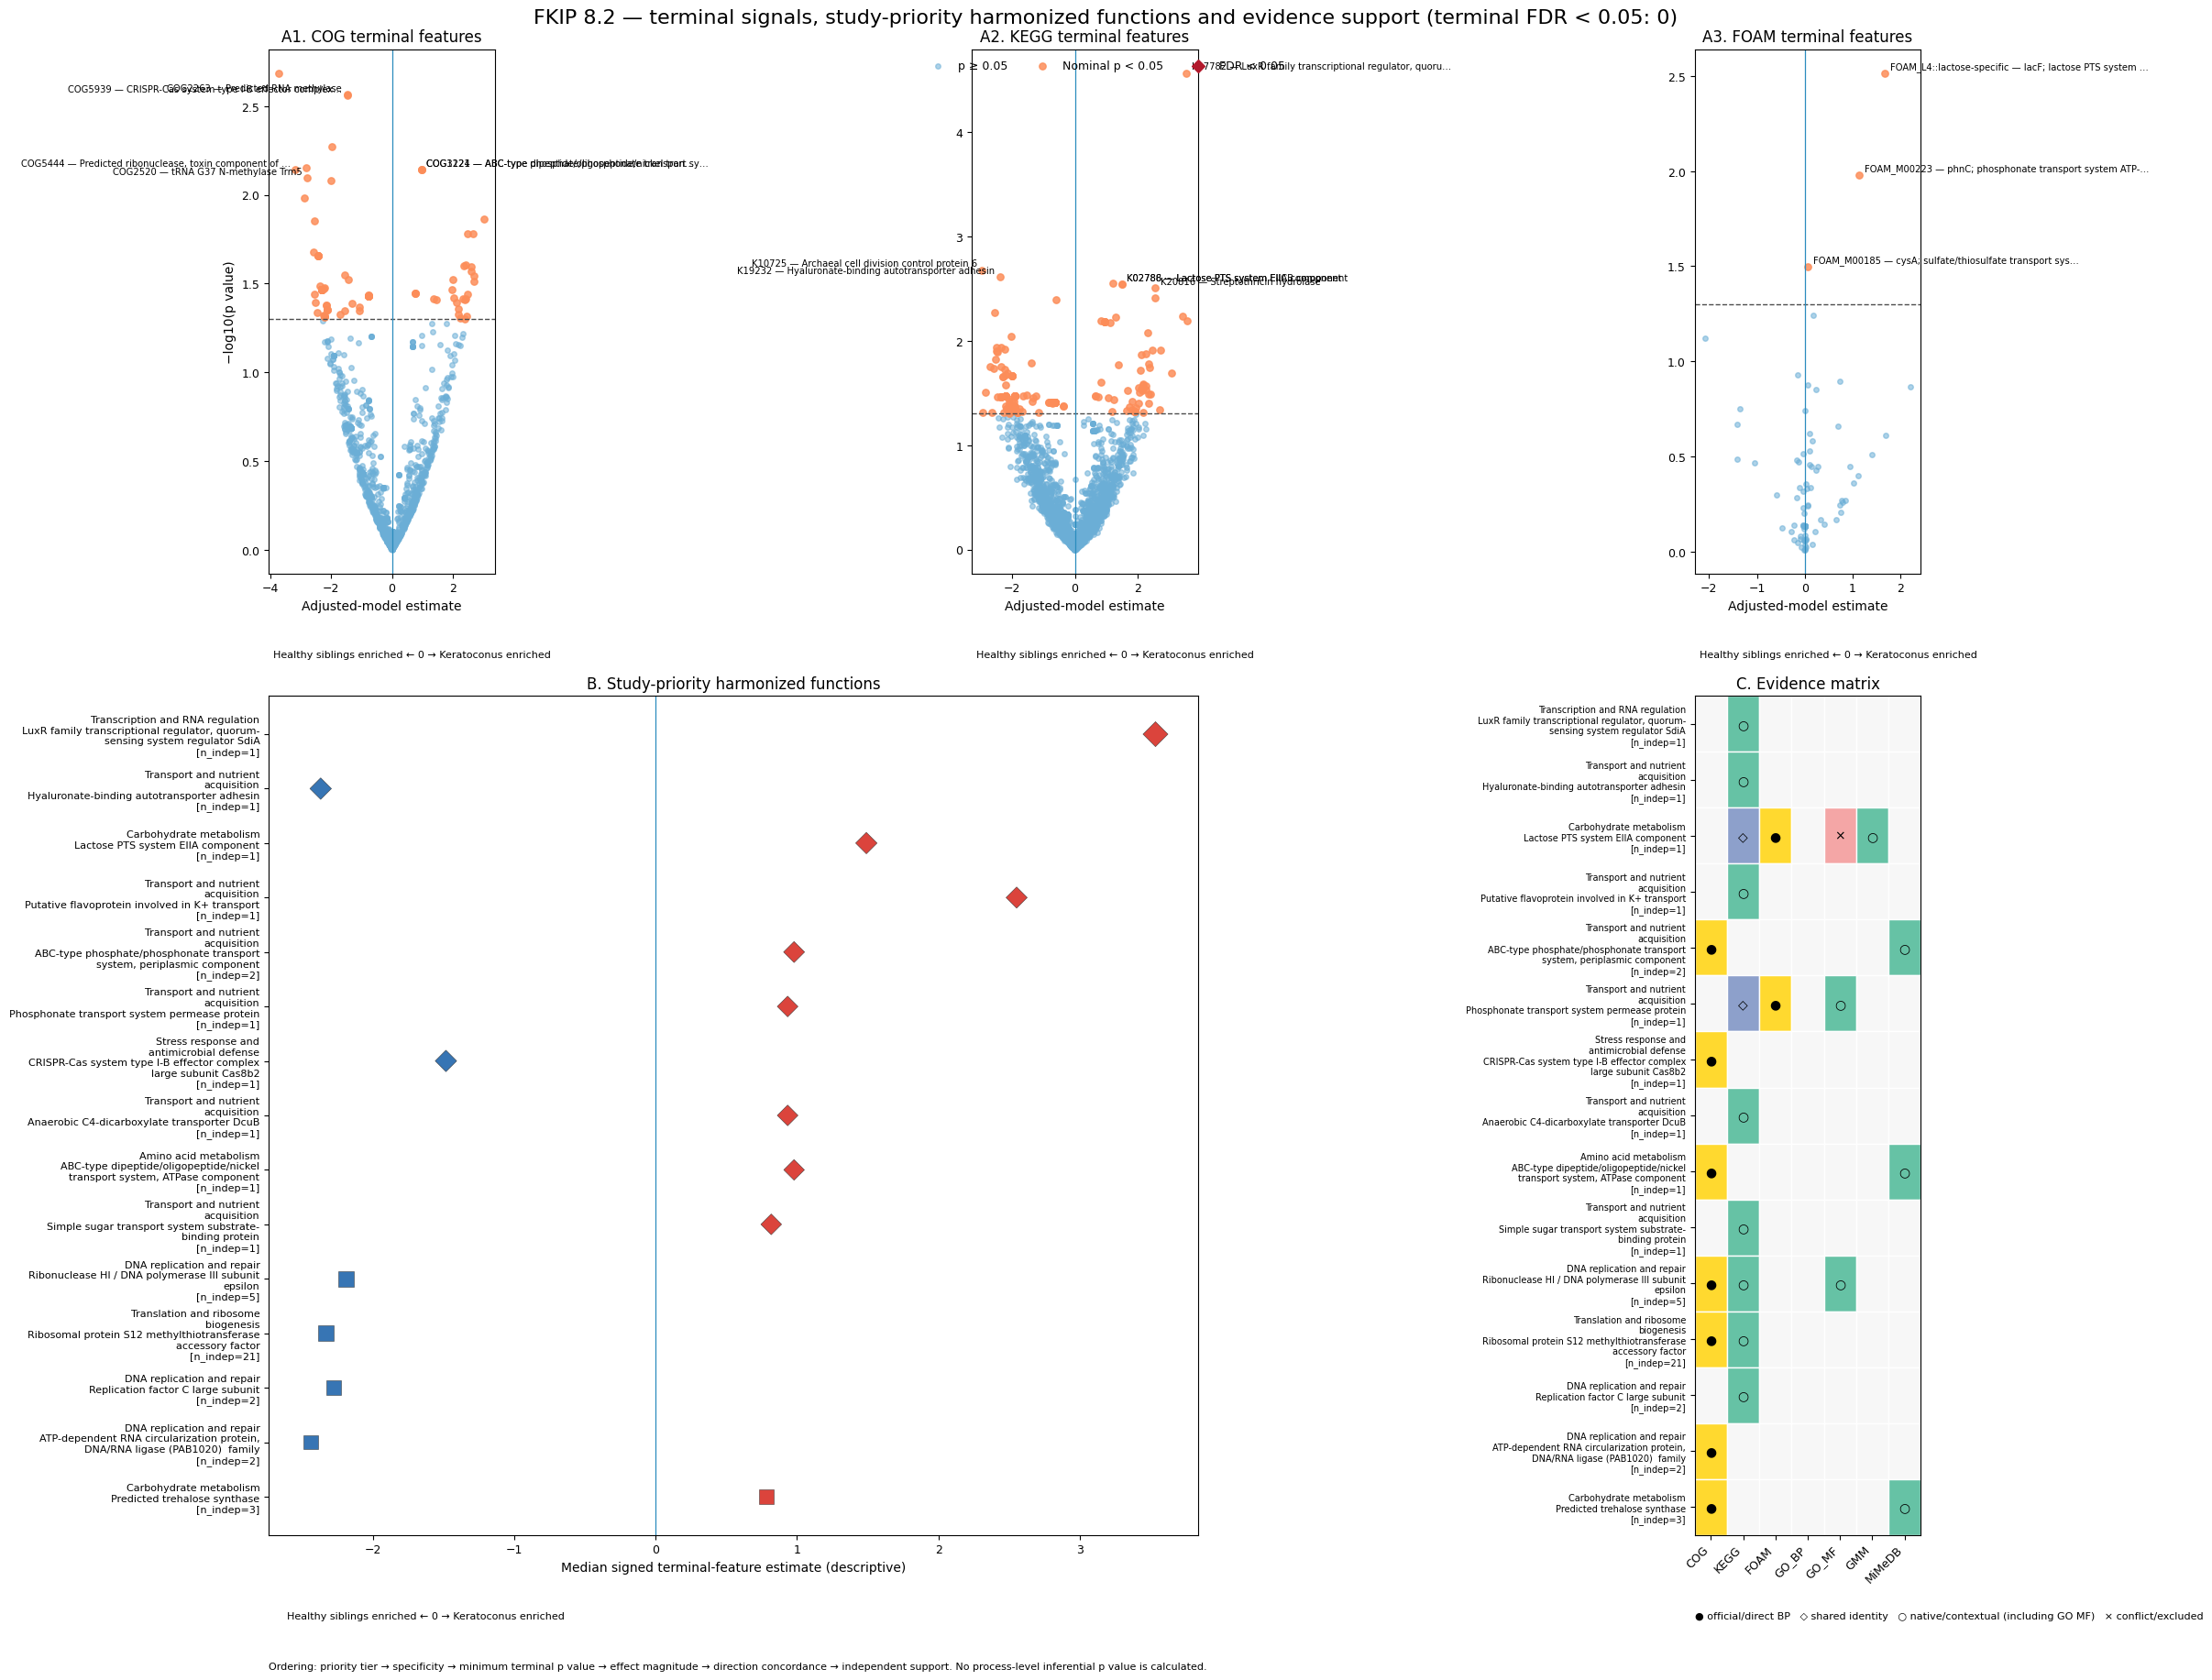

Figure written to: /content/FKIP_v8_2/outputs/figures/FKIP8_1_1_Multipanel_Figure.png
Vector figure written to: /content/FKIP_v8_2/outputs/figures/FKIP8_1_1_Multipanel_Figure.pdf


In [19]:
# ============================================================
# 16. Publication multipanel figure — FKIP v8.2
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from textwrap import fill

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": True,
    "axes.spines.right": True,
})

COLOR_HEALTHY = "#2166AC"
COLOR_KC = "#D73027"
COLOR_NS = "#6BAED6"
COLOR_NOMINAL = "#FC8D59"
COLOR_FDR = "#B2182B"
PANEL_C_COLORS = {
    -1: "#F4A6A6",   # conflict/excluded
    0: "#F7F7F7",    # absent
    1: "#66C2A5",    # native/contextual
    2: "#FFD92F",    # official/direct
    3: "#8DA0CB",    # shared identity
}
PANEL_C_SYMBOLS = {-1: "×", 0: "", 1: "○", 2: "●", 3: "◇"}


def short_label(text, maximum=52):
    value = clean_text(text)
    return value if len(value) <= maximum else value[:maximum - 1] + "…"


def wrap_label(text, width):
    return fill(clean_text(text), width=width) if clean_text(text) else ""


def is_generic_or_uncharacterized(text):
    value = clean_text(text).lower()
    generic_terms = ["uncharacterized", "hypothetical", "predicted protein", "putative protein", "domain-containing protein"]
    return any(term in value for term in generic_terms)

# Panel A uses all tested terminal rows; only publication-ready nominal features receive labels.
plot_terminal = terminal_stats.copy()
plot_terminal["neglog10p"] = -np.log10(pd.to_numeric(plot_terminal["p_value"], errors="coerce").clip(lower=np.nextafter(0, 1)))
label_dictionary = final_table.set_index("feature_key")[["canonical_feature_id", "native_function", "publication_status", "manual_review"]].to_dict("index")
plot_terminal["plot_label"] = plot_terminal["feature_key"].map(
    lambda key: (
        f"{label_dictionary[key]['canonical_feature_id']} — {clean_text(label_dictionary[key]['native_function'])}"
        if key in label_dictionary else ""
    )
)
plot_terminal["label_allowed"] = plot_terminal["feature_key"].isin(final_table.loc[
    final_table["publication_status"].eq("publication_ready") & ~final_table["native_function"].fillna("").map(is_generic_or_uncharacterized),
    "feature_key",
])
plot_terminal["plot_priority"] = (
    plot_terminal["FDR_significant"].astype(int) * 1000
    + plot_terminal["nominal_significant"].astype(int) * 100
    + plot_terminal["neglog10p"].fillna(0)
    + plot_terminal["abs_estimate_percentile_within_database"].fillna(0)
)

# Panel B keeps study-specific processes above broad/core context and labels them as theme / Function.
if study_priority_processes.empty:
    plot_process = pd.DataFrame()
else:
    specific = study_priority_processes.loc[
        study_priority_processes["Study_priority_tier"].isin(["A_specific_supported", "B_coordinated_signal", "D_single_exploratory"])
    ].head(PANEL_B_SPECIFIC_PROCESSES).copy()
    specific["panel_block"] = "A. Specific and supported signals"
    core = study_priority_processes.loc[
        study_priority_processes["Study_priority_tier"] == "C_core_or_broad_context"
    ].head(PANEL_B_CORE_PROCESSES).copy()
    core["panel_block"] = "B. Core or broad context"
    plot_process = pd.concat([specific, core], ignore_index=True).drop_duplicates(["Primary_process", "Representative_function"])
    plot_process["neglog10_min_p"] = -np.log10(pd.to_numeric(plot_process["min_terminal_p_value"], errors="coerce").clip(lower=np.nextafter(0, 1)))
    plot_process = plot_process.sort_values(["Study_priority_tier_rank", "Study_priority_score"], ascending=[True, False], na_position="last").reset_index(drop=True)
    plot_process["display_label"] = plot_process.apply(
        lambda row: (
            wrap_label(clean_text(row.get("Primary_biological_theme", "")), PANEL_B_WRAP_THEME)
            + "\n"
            + wrap_label(clean_text(row.get("Representative_function", row.get("Primary_process", ""))), PANEL_B_WRAP_FUNCTION)
            + f"\n[n_indep={int(row.get('n_independent_terminal_features', 0))}]"
        ),
        axis=1,
    )

if not plot_process.empty and not evidence_matrix.empty:
    matrix_processes = plot_process["Primary_process"].tolist()
    plot_evidence = evidence_matrix.set_index("Primary_process").reindex(matrix_processes).fillna(0)
else:
    plot_evidence = pd.DataFrame()

fig = plt.figure(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), constrained_layout=True)
gs = GridSpec(2, 3, figure=fig, width_ratios=[1, 1, 1], height_ratios=[1.0, 1.6])

# ---------------- Panel A ----------------
legend_handles = None
legend_labels = None
for index, database in enumerate(["COG", "KEGG", "FOAM"]):
    ax = fig.add_subplot(gs[0, index])
    data = plot_terminal.loc[plot_terminal["Database_norm"] == database].copy()
    if data.empty:
        ax.text(0.5, 0.5, "No terminal features", ha="center", va="center")
        ax.set_axis_off()
        continue
    nonsig = ~data["nominal_significant"].fillna(False)
    nominal = data["nominal_significant"].fillna(False) & ~data["FDR_significant"].fillna(False)
    fdr = data["FDR_significant"].fillna(False)
    h1 = ax.scatter(data.loc[nonsig, "Estimate"], data.loc[nonsig, "neglog10p"], alpha=0.55, s=16, color=COLOR_NS, label="p ≥ 0.05")
    h2 = ax.scatter(data.loc[nominal, "Estimate"], data.loc[nominal, "neglog10p"], alpha=0.85, s=28, color=COLOR_NOMINAL, label="Nominal p < 0.05")
    h3 = ax.scatter(data.loc[fdr, "Estimate"], data.loc[fdr, "neglog10p"], marker="D", s=50, color=COLOR_FDR, label="FDR < 0.05")
    ax.axhline(-np.log10(P_VALUE_THRESHOLD), linestyle="--", linewidth=1, color="#4D4D4D")
    ax.axvline(0, linewidth=0.9, color="#2B8CBE")
    ax.set_title(f"A{index + 1}. {database} terminal features")
    ax.set_xlabel("Adjusted-model estimate")
    if index == 0:
        ax.set_ylabel("−log10(p value)")
    top_labels = data.loc[data["label_allowed"]].sort_values(["plot_priority", "p_value"], ascending=[False, True]).head(PANEL_A_LABELS_PER_DATABASE)
    for _, row in top_labels.iterrows():
        dx = 4 if row["Estimate"] >= 0 else -4
        ha = "left" if row["Estimate"] >= 0 else "right"
        ax.annotate(short_label(row["plot_label"], 54), (row["Estimate"], row["neglog10p"]), fontsize=7.2, xytext=(dx, 3), textcoords="offset points", ha=ha)
    ax.text(0.02, -0.16, "Healthy siblings enriched ← 0 → Keratoconus enriched", transform=ax.transAxes, fontsize=8)
    if index == 2:
        legend_handles = [h1, h2, h3]
        legend_labels = ["p ≥ 0.05", "Nominal p < 0.05", "FDR < 0.05"]

if legend_handles is not None:
    fig.legend(legend_handles, legend_labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.985))

# ---------------- Panel B ----------------
ax_b = fig.add_subplot(gs[1, :2])
if plot_process.empty:
    ax_b.text(0.5, 0.5, "No publication-ready harmonized processes", ha="center", va="center")
    ax_b.set_axis_off()
else:
    y = np.arange(len(plot_process))
    tier_markers = {"A_specific_supported": "D", "B_coordinated_signal": "o", "C_core_or_broad_context": "s", "D_single_exploratory": "^"}
    sizes = 70 + 25 * plot_process["neglog10_min_p"].fillna(0).clip(upper=8) + 12 * np.log1p(plot_process["n_independent_terminal_features"])
    for tier, group in plot_process.groupby("Study_priority_tier"):
        positions = group.index.to_numpy()
        colors = [COLOR_KC if value > 0 else COLOR_HEALTHY for value in group["median_signed_estimate"]]
        ax_b.scatter(group["median_signed_estimate"], positions, s=sizes.loc[positions], marker=tier_markers.get(tier, "o"), c=colors, edgecolor="#333333", linewidth=0.4, alpha=0.9, label=tier)
    ax_b.axvline(0, linewidth=0.9, color="#2B8CBE")
    ax_b.set_yticks(y)
    ax_b.set_yticklabels(plot_process["display_label"], fontsize=8)
    ax_b.invert_yaxis()
    ax_b.set_xlabel("Median signed terminal-feature estimate (descriptive)")
    ax_b.set_title("B. Study-priority harmonized functions")
    ax_b.text(0.02, -0.10, "Healthy siblings enriched ← 0 → Keratoconus enriched", transform=ax_b.transAxes, fontsize=8)
    ax_b.text(0.0, -0.16, "Ordering: priority tier → specificity → minimum terminal p value → effect magnitude → direction concordance → independent support. No process-level inferential p value is calculated.", transform=ax_b.transAxes, fontsize=8)

# ---------------- Panel C ----------------
ax_c = fig.add_subplot(gs[1, 2])
if plot_evidence.empty:
    ax_c.text(0.5, 0.5, "No typed evidence matrix", ha="center", va="center")
    ax_c.set_axis_off()
else:
    matrix = plot_evidence.reindex(columns=EVIDENCE_SOURCE_ORDER, fill_value=0)
    color_array = np.empty(matrix.shape, dtype=object)
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            color_array[r, c] = PANEL_C_COLORS.get(int(matrix.iloc[r, c]), "#F7F7F7")
    for r in range(matrix.shape[0]):
        for c in range(matrix.shape[1]):
            rect = plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=color_array[r, c], edgecolor="white", linewidth=1.0)
            ax_c.add_patch(rect)
            symbol = PANEL_C_SYMBOLS.get(int(matrix.iloc[r, c]), "")
            if symbol:
                ax_c.text(c, r, symbol, ha="center", va="center", fontsize=10)
    ax_c.set_xlim(-0.5, matrix.shape[1] - 0.5)
    ax_c.set_ylim(matrix.shape[0] - 0.5, -0.5)
    ax_c.set_xticks(np.arange(matrix.shape[1]))
    ax_c.set_xticklabels(matrix.columns, rotation=45, ha="right")
    ax_c.set_yticks(np.arange(matrix.shape[0]))
    evidence_labels = plot_process["display_label"].tolist() if not plot_process.empty else [wrap_label(value, PANEL_C_WRAP) for value in matrix.index]
    ax_c.set_yticklabels(evidence_labels, fontsize=7)
    ax_c.set_title("C. Evidence matrix")
    ax_c.text(0.0, -0.10, "● official/direct BP   ◇ shared identity   ○ native/contextual (including GO MF)   × conflict/excluded", transform=ax_c.transAxes, fontsize=8)

fdr_count = int(final_table["FDR_significant"].sum())
fig.suptitle(
    f"FKIP 8.2 — terminal signals, study-priority harmonized functions and evidence support (terminal FDR < 0.05: {fdr_count})",
    fontsize=16, y=1.01,
)

png_path = FIGURE_DIR / "FKIP8_1_1_Multipanel_Figure.png"
pdf_path = FIGURE_DIR / "FKIP8_1_1_Multipanel_Figure.pdf"
fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()
print("Figure written to:", png_path)
print("Vector figure written to:", pdf_path)


## Interpretive safeguards

1. Terminal-feature p values and adjusted p values are retained exactly as produced by the original statistical models.
2. Harmonized processes are descriptive syntheses of terminal findings; no process-level inferential test is created from feature-level p values.
3. `n_independent_terminal_features` is calculated after conservative clustering of KEGG–FOAM annotation overlap.
4. Broad and housekeeping functions are retained as biological context but do not automatically outrank study-specific process candidates.
5. GO, GMM and MiMeDB are distinct evidence layers with explicit routes and strength codes.
6. Human/eukaryotic/disease hierarchy paths are retained in evidence tables but excluded from the primary microbiome summary.

7. EC-to-GO and KEGG-reaction-to-GO mappings predominantly describe GO Molecular Function; these mappings are retained as contextual functional support and are not mislabeled as Biological Process evidence.
8. GO Biological Process and GO Molecular Function are displayed separately in the evidence matrix.

7. Automatic publication-ready assignments are restored before manual replacements and are protected by a hard consolidation audit.


In [20]:
# ============================================================
# 17. Bibliography, metadata, workbook, CSVs and Drive upload
# ============================================================
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

bibliography = pd.DataFrame([
    {
        "resource": "MetaCerberus",
        "citation": "Figueroa JL III, et al. MetaCerberus: distributed highly parallelized HMM-based processing for robust functional annotation across the tree of life. Bioinformatics. 2024;40(3):btae119.",
        "doi": "10.1093/bioinformatics/btae119",
        "role_in_FKIP": "Origin of KEGG, COG and FOAM annotations and native Function/hierarchy fields.",
    },
    {
        "resource": "COG2024",
        "citation": "Galperin MY, et al. COG database update 2024. Nucleic Acids Res. 2025;53(D1):D356-D363.",
        "doi": "10.1093/nar/gkae983",
        "role_in_FKIP": "Official COG definitions, categories, gene symbols and structural aliases.",
    },
    {
        "resource": "Gene Ontology",
        "citation": "The Gene Ontology Consortium. The Gene Ontology knowledgebase in 2023. Genetics. 2023;224(1):iyad031.",
        "doi": "10.1093/genetics/iyad031",
        "role_in_FKIP": "Biological Process semantic backbone and exact official cross-references.",
    },
    {
        "resource": "GMM",
        "citation": "Vieira-Silva S, et al. Species-function relationships shape ecological properties of the human gut microbiome. Nat Microbiol. 2016;1:16088.",
        "doi": "10.1038/nmicrobiol.2016.88",
        "role_in_FKIP": "Gut-specific metabolic contextual evidence.",
    },
    {
        "resource": "MiMeDB",
        "citation": "Wishart DS, et al. MiMeDB 2.0: the human microbial metabolome database. Nucleic Acids Res. 2026.",
        "doi": "",
        "role_in_FKIP": "Identifier-linked microbe-gene-metabolite contextual evidence.",
    },
])

resource_manifest_rows = []
for key, info in FILES.items():
    path = LOCAL.get(key)
    if info is None or path is None:
        continue
    resource_manifest_rows.append({
        "resource_key": key,
        "drive_file_id": info.get("id"),
        "drive_name": info.get("display_name", info.get("name")),
        "drive_path": info.get("path"),
        "modifiedTime": info.get("modifiedTime"),
        "md5Checksum_drive": info.get("md5Checksum"),
        "sha256": sha256_file(path),
        "local_size_bytes": Path(path).stat().st_size,
    })
resource_manifest = pd.DataFrame(resource_manifest_rows)

run_metadata = {
    "pipeline_version": "FKIP_v8.2",
    "run_timestamp_utc": RUN_TIMESTAMP,
    "FKIP_folder_id": FKIP_FOLDER_ID,
    "BugBuster_fallback_folder_id": BUGBUSTER_OUTPUT_FOLDER_ID,
    "statistical_policy": {
        "p_value_threshold": P_VALUE_THRESHOLD,
        "absolute_estimate_threshold": None,
        "terminal_levels": {key: sorted(values) for key, values in TERMINAL_LEVELS.items()},
        "primary_selection": "nominal p<0.05 among canonical terminal statistical levels",
        "FDR_status_retained_separately": True,
        "process_level_inference_created": False,
    },
    "sign_convention": {"positive": POSITIVE_GROUP, "negative": NEGATIVE_GROUP},
    "GO_version": GO_VERSION,
    "counts": consistency_check.iloc[0].to_dict(),
    "policies": [
        "Level-ID is the preferred terminal abundance representation for COG and KEGG; FOAM Level-4 is the tested terminal module representation.",
        "Rollups supply native Function, EC, gene aliases and complete hierarchy paths.",
        "Function is a primary semantic and traceability field but not an independent evidence database.",
        "COG gene symbols and PDB identifiers are provenance fields, not independent functions.",
        "Repeated KEGG/FOAM hierarchy paths are not counted as independent terminal findings.",
        "A fixed absolute-estimate threshold is not used.",
        "Exact identifiers and official cross-references are preferred; approximate text matching is never automatically accepted.",
        "Human/eukaryotic/disease contexts remain in evidence tables but are excluded from primary microbiome summaries.",
        "GO evidence is propagated by canonical feature provenance through EC/reaction identifiers to GO BP and harmonized processes; process-name equality is not required.",
        "GO support is classified as official/direct, contextual/related, or conflicting before construction of the evidence matrix.",
        "GO Molecular Function and Biological Process are retained as separate evidence aspects; MF is contextual to process interpretation and is never promoted automatically to BP.",
        "GO, GMM and MiMeDB evidence routes are propagated into the feature and process outputs.",
        "Study-priority process ranking is descriptive and does not generate process-level inferential p values.",
        "Broad and housekeeping processes are retained in a separate contextual tier so they do not obscure specific study signals.",
    ],
}


results_writing_all = final_table.copy()
results_writing_all["Statistical_status"] = np.where(results_writing_all["FDR_significant"], "FDR_significant", np.where(results_writing_all["nominal_significant"], "Nominal_only", "Not_significant"))
results_writing_all["Manual_curated"] = results_writing_all["assignment_origin"].eq("manual_curated")
results_writing_all["Evidence_summary"] = results_writing_all.apply(
    lambda row: " | ".join([item for item in [row.get("Database_norm", ""), row.get("GO_all_IDs", row.get("GO_IDs", "")), row.get("GMM_IDs", ""), row.get("MiMeDB_matched_identifiers", "")] if clean_text(str(item))]),
    axis=1,
)
writing_columns = [
    "Database_norm", "Level_norm", "canonical_feature_id", "native_function", "Primary_biological_theme",
    "Primary_process", "Functional_context", "Estimate", "Std_Error", "p_value", "p_adj", "enriched_group",
    "Statistical_status", "assignment_origin", "confidence", "Manual_curated", "Evidence_summary",
    "manual_review", "publication_status",
]
results_writing_all = results_writing_all.loc[:, [col for col in writing_columns if col in results_writing_all.columns]]
results_writing_priority = final_table.loc[
    final_table["publication_status"].eq("publication_ready")
    & final_table["Primary_biological_theme"].fillna("").ne("")
].copy()
results_writing_priority["Statistical_status"] = np.where(results_writing_priority["FDR_significant"], "FDR_significant", "Nominal_only")
results_writing_priority["Manual_curated"] = results_writing_priority["assignment_origin"].eq("manual_curated")
results_writing_priority["Evidence_summary"] = results_writing_priority.apply(
    lambda row: " | ".join([item for item in [row.get("Database_norm", ""), row.get("GO_all_IDs", row.get("GO_IDs", "")), row.get("GMM_IDs", ""), row.get("MiMeDB_matched_identifiers", "")] if clean_text(str(item))]),
    axis=1,
)
results_writing_priority = results_writing_priority.sort_values(["Primary_biological_theme", "p_value", "Estimate"], ascending=[True, True, False], na_position="last")
results_writing_priority = results_writing_priority.loc[:, [col for col in writing_columns if col in results_writing_priority.columns]]
assignment_audit = final_table[[
    "manual_review_key", "feature_key", "assignment_origin", "automatic_Primary_process", "automatic_Primary_biological_theme",
    "Primary_process", "Primary_biological_theme", "confidence", "publication_status"
] + [col for col in ["manual_decision", "manual_rationale", "manual_reviewer", "manual_source_or_reference"] if col in final_table.columns]].copy()

function_dictionary = final_table[[
    "Database_norm", "Level_norm", "canonical_feature_id", "native_function", "normalized_function",
    "canonical_function", "function_informativeness", "function_semantic_class", "gene_aliases",
    "structural_aliases", "native_ECs", "Native_IDs", "Functional_context", "Primary_process",
    "Secondary_processes", "Primary_biological_theme", "assignment_route", "assignment_rule_id",
    "confidence", "Traceability_summary",
]].drop_duplicates()

tables = {
    "Functional_integration": final_table,
    "Publication_ready": publication_ready,
    "Terminal_features": selected,
    "Study_priority_processes": study_priority_processes,
    "Process_support_summary": process_support_summary,
    "Theme_summary": theme_summary,
    "Evidence_matrix": evidence_matrix,
    "Evidence_matrix_labels": evidence_matrix_labels,
    "Evidence_matrix_long": evidence_matrix_long,
    "Function_dictionary": function_dictionary,
    "Rollup_ID_audit": rollup_id_audit,
    "Rollup_level_audit": rollup_level_audit,
    "Rollup_terminal_ID_audit": rollup_terminal_id_audit,
    "Manual_review": manual_review,
    "Manual_review_template": manual_review_template,
    "Manual_overrides_applied": manual_overrides_applied,
    "Manual_consolidation_audit": manual_consolidation_audit,
    "Results_writing_all": results_writing_all,
    "Results_writing_priority": results_writing_priority,
    "Assignment_audit": assignment_audit,
    "Evidence_long": ontology_paths,
    "Process_catalog_microbiome": process_catalog_microbiome,
    "Excluded_context_catalog": excluded_context_catalog,
    "Diagnostics": diagnostics,
    "Unmatched_features": unmatched,
    "GO_evidence": go_evidence,
    "GO_BP_evidence": go_bp_evidence,
    "GO_MF_evidence": go_mf_evidence,
    "GO_mapping_source_summary": go_mapping_source_summary,
    "GO_BP_process_relations": go_bp_process_relation_long,
    "GO_MF_process_relations": go_mf_process_relation_long,
    "GO_process_relation_long": go_process_relation_long,
    "GO_relation_summary": go_relation_summary,
    "GO_propagation_validation": go_propagation_validation,
    "GO_validation": go_validation,
    "GMM_evidence": gmm_evidence,
    "GMM_catalog": gmm_catalog,
    "GMM_identifier_map": gmm_identifier_map,
    "MiMeDB_gene_hits": mimedb_gene_hits,
    "Consistency_check": consistency_check,
    "Resource_manifest": resource_manifest,
    "Bibliography": bibliography,
}

xlsx_path = OUTPUT_DIR / "Supplementary_Functional_Knowledge_Integration_v8_2.xlsx"
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    for sheet_name, dataframe in tables.items():
        if dataframe is None:
            continue
        dataframe.to_excel(writer, sheet_name=sheet_name[:31], index=False)

# Professional workbook formatting.
workbook = load_workbook(xlsx_path)
header_fill = PatternFill("solid", fgColor="1F4E78")
header_font = Font(color="FFFFFF", bold=True)
for worksheet in workbook.worksheets:
    worksheet.freeze_panes = "A2"
    worksheet.auto_filter.ref = worksheet.dimensions
    for cell in worksheet[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    for column_index, column_cells in enumerate(worksheet.columns, start=1):
        sampled = [clean_text(cell.value) for cell in list(column_cells)[:250]]
        maximum = max([len(value) for value in sampled] + [8])
        worksheet.column_dimensions[get_column_letter(column_index)].width = min(max(maximum + 2, 10), 40)
    for row in worksheet.iter_rows(min_row=2, max_row=min(worksheet.max_row, 5000)):
        for cell in row:
            cell.alignment = Alignment(vertical="top", wrap_text=True)
workbook.save(xlsx_path)

for sheet_name, dataframe in tables.items():
    if dataframe is not None:
        dataframe.to_csv(OUTPUT_DIR / f"{sheet_name}_v8_2.csv", index=False, encoding="utf-8-sig")

metadata_path = OUTPUT_DIR / "Pipeline_Run_Metadata_v8_2.json"
metadata_path.write_text(json.dumps(run_metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

# Compact package for archival transfer.
package_path = OUTPUT_DIR / "FKIP_v8_2_results_package.zip"
with zipfile.ZipFile(package_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for local_path in sorted(OUTPUT_DIR.rglob("*")):
        if local_path.is_file() and local_path != package_path:
            archive.write(local_path, local_path.relative_to(OUTPUT_DIR))

# ---------------- Automatic upload to Drive ----------------
def find_child_folder(parent_id: str, name: str) -> Optional[str]:
    response = DRIVE.files().list(
        q=(
            f"'{parent_id}' in parents and trashed=false and "
            f"mimeType='{FOLDER_MIME}' and name='{name}'"
        ),
        fields="files(id,name)",
        pageSize=100,
        supportsAllDrives=True,
        includeItemsFromAllDrives=True,
    ).execute()
    files = response.get("files", [])
    return files[0]["id"] if files else None


def get_or_create_folder(parent_id: str, name: str) -> str:
    existing = find_child_folder(parent_id, name)
    if existing:
        return existing
    created = DRIVE.files().create(
        body={"name": name, "mimeType": FOLDER_MIME, "parents": [parent_id]},
        fields="id,name",
        supportsAllDrives=True,
    ).execute()
    return created["id"]


def upload_or_replace(local_path: Path, parent_id: str) -> dict:
    local_path = Path(local_path)
    safe_name = local_path.name.replace("'", "\\'")
    response = DRIVE.files().list(
        q=f"'{parent_id}' in parents and trashed=false and name='{safe_name}'",
        fields="files(id,name)",
        pageSize=100,
        supportsAllDrives=True,
        includeItemsFromAllDrives=True,
    ).execute()
    hits = response.get("files", [])
    media = MediaFileUpload(str(local_path), resumable=True)
    if hits:
        return DRIVE.files().update(
            fileId=hits[0]["id"], media_body=media,
            fields="id,name,webViewLink", supportsAllDrives=True,
        ).execute()
    return DRIVE.files().create(
        body={"name": local_path.name, "parents": [parent_id]},
        media_body=media, fields="id,name,webViewLink", supportsAllDrives=True,
    ).execute()

results_parent_id = get_or_create_folder(FKIP_FOLDER_ID, DRIVE_RESULTS_PARENT)
results_v81_id = get_or_create_folder(results_parent_id, DRIVE_RESULTS_FOLDER)

upload_records = []
# The upload manifest is generated after the first pass, then uploaded in a second pass.
for local_path in sorted(OUTPUT_DIR.rglob("*")):
    if not local_path.is_file() or local_path.name.startswith("Drive_Upload_Manifest"):
        continue
    uploaded = upload_or_replace(local_path, results_v81_id)
    upload_records.append({
        "local_path": str(local_path),
        "drive_file_id": uploaded.get("id"),
        "drive_name": uploaded.get("name"),
        "webViewLink": uploaded.get("webViewLink"),
    })
    print("Uploaded:", local_path.name)

upload_manifest = pd.DataFrame(upload_records)
upload_manifest_path = OUTPUT_DIR / "Drive_Upload_Manifest_v8_2.csv"
upload_manifest.to_csv(upload_manifest_path, index=False, encoding="utf-8-sig")
upload_manifest_record = upload_or_replace(upload_manifest_path, results_v81_id)

folder_link = f"https://drive.google.com/drive/folders/{results_v81_id}"
(OUTPUT_DIR / "Drive_Result_Folder_Link_v8_2.txt").write_text(folder_link, encoding="utf-8")
upload_or_replace(OUTPUT_DIR / "Drive_Result_Folder_Link_v8_2.txt", results_v81_id)

print("\nExports written to:", OUTPUT_DIR)
print("Main workbook:", xlsx_path)
print("Drive destination:", folder_link)
print("Files uploaded:", len(upload_records) + 2)


Uploaded: Assignment_audit_v8_2.csv
Uploaded: Bibliography_v8_2.csv
Uploaded: Consistency_check_v8_2.csv
Uploaded: Diagnostics_v8_2.csv
Uploaded: Evidence_long_v8_2.csv
Uploaded: Evidence_matrix_labels_v8_2.csv
Uploaded: Evidence_matrix_long_v8_2.csv
Uploaded: Evidence_matrix_v8_2.csv
Uploaded: Excluded_context_catalog_v8_2.csv
Uploaded: FKIP_v8_2_results_package.zip
Uploaded: Function_dictionary_v8_2.csv
Uploaded: Functional_integration_v8_2.csv
Uploaded: GMM_catalog_v8_2.csv
Uploaded: GMM_evidence_v8_2.csv
Uploaded: GMM_identifier_map_v8_2.csv
Uploaded: GO_BP_evidence_v8_2.csv
Uploaded: GO_BP_process_relations_v8_2.csv
Uploaded: GO_MF_evidence_v8_2.csv
Uploaded: GO_MF_process_relations_v8_2.csv
Uploaded: GO_evidence_v8_2.csv
Uploaded: GO_mapping_source_summary_v8_2.csv
Uploaded: GO_process_relation_long_v8_2.csv
Uploaded: GO_propagation_validation_v8_2.csv
Uploaded: GO_relation_summary_v8_2.csv
Uploaded: GO_validation_v8_2.csv
Uploaded: Manual_consolidation_audit_v8_2.csv
Uploaded: M

## Recommended review sequence

1. **Consistency_check** — verify selected features, publication-ready counts and external evidence coverage.
2. **Rollup_level_audit** and **Rollup_terminal_ID_audit** — confirm the terminal-matrix/rollup relationship.
3. **Rollup_ID_audit** — inspect repeated hierarchy paths, conflicting vectors and Function conflicts.
4. **Publication_ready** — primary feature-level interpretation table.
5. **Study_priority_processes** — processes organized to highlight specific study signals without hiding broad microbiome functions.
6. **Process_support_summary** — complementary ranking by independent terminal support.
7. **Manual_review** — ambiguous, unresolved and excluded records.
8. **Evidence_matrix_long** — trace the exact source and strength of each process-level evidence item.
9. **Function_dictionary** — inspect native Function, canonical function, process, context, theme and assignment rule.
10. **FKIP8_1_Multipanel_Figure** — publication figure with terminal features, study-priority processes and typed evidence.
